In [21]:
import pandas as pd
import numpy as np
from pathlib import Path
import matplotlib.pyplot as plt
import re

# ============================================================
# SINGLE CELL - CLINICAL GROUPING + SAMPLE TYPE HISTOLOGY ANALYSIS + MUTATIONS
#
# GROUP-ORIENTED CHAIN:
# LUAD_NSCLC = LUAD + NSCLC
# LUSC_NSCLC = LUSC + NSCLC
#
# Output principali in memoria:
# - df_with_groups
# - clinical
# - group_sample_type_summary
# - df
# - df_mutations
# - df_final
# - df_final_grouped
#
# Compatibilità:
# Le celle successive del notebook useranno ONCOTREE_CODE come gruppo aggregato:
#   ONCOTREE_CODE = LUAD_NSCLC oppure LUSC_NSCLC
#
# L'istologia originale viene conservata in:
#   ORIGINAL_ONCOTREE_CODE
#
# La nuova variabile clinica di stratificazione è:
#   sample_type_group
# ============================================================


# ============================================================
# 0. Paths e parametri
# ============================================================

data_dir = Path("data_lung")

input_file = data_dir / "filtered_data_LUNG.csv"
file_path_mutations = Path("data") / "data_mutations.txt"

SAVE_OUTPUTS = True

output_dir = data_dir / "clinical_to_network_by_oncotree_groups_sample_type"
output_dir.mkdir(parents=True, exist_ok=True)

oncotree_groups = {
    "LUAD_NSCLC": ["LUAD", "NSCLC"],
    "LUSC_NSCLC": ["LUSC", "NSCLC"],
}

target_groups = ["LUAD_NSCLC", "LUSC_NSCLC"]

group_labels = {
    "LUAD_NSCLC": "LUAD+NSCLC",
    "LUSC_NSCLC": "LUSC+NSCLC",
}

sample_type_original_col = "Sample Type"


# ============================================================
# Helper
# ============================================================

def safe_filename(text):
    text = str(text)
    text = re.sub(r"[^A-Za-z0-9_-]+", "_", text)
    return text.strip("_")


def safe_display(df_obj):
    try:
        display(df_obj)
    except NameError:
        print(df_obj)


def collapse_duplicate_columns(df_in):
    """
    Rimuove/gestisce colonne duplicate.
    Se esistono duplicati con stesso nome, tiene la prima occorrenza.
    """
    return df_in.loc[:, ~df_in.columns.duplicated()].copy()


def clean_sample_type_value(x):
    """
    Normalizza la variabile Sample Type.

    Nel dataset filtrato i valori principali sono:
    - Primary
    - Metastasis
    """
    if pd.isna(x):
        return np.nan

    x_str = str(x).strip()

    if x_str.lower() in ["primary", "primary tumor", "primary tumour"]:
        return "Primary"

    if x_str.lower() in ["metastasis", "metastatic", "metastatic tumor", "metastatic tumour"]:
        return "Metastasis"

    return x_str


# ============================================================
# 1. Load filtered clinical dataset
# ============================================================

df_raw = pd.read_csv(input_file, low_memory=False)
df_raw = collapse_duplicate_columns(df_raw)

df_raw = df_raw.rename(columns={
    "Patient_ID": "PATIENT_ID",
    "Oncotree Code": "ONCOTREE_CODE",
    sample_type_original_col: "SAMPLE_TYPE"
})

df_raw = collapse_duplicate_columns(df_raw)


# ============================================================
# 2. Check colonne richieste
# ============================================================

required_cols = {
    "PATIENT_ID",
    "ONCOTREE_CODE",
    "SAMPLE_TYPE"
}

missing_cols = required_cols - set(df_raw.columns)

if missing_cols:
    raise ValueError(
        f"Colonne mancanti in filtered_data_LUNG.csv: {missing_cols}"
    )


# ============================================================
# 3. Preprocessing Sample Type
# ============================================================

df_raw["PATIENT_ID"] = df_raw["PATIENT_ID"].astype(str)
df_raw["ONCOTREE_CODE"] = df_raw["ONCOTREE_CODE"].astype(str)

df_raw["SAMPLE_TYPE"] = df_raw["SAMPLE_TYPE"].apply(clean_sample_type_value)

df_raw = df_raw.dropna(
    subset=[
        "PATIENT_ID",
        "ONCOTREE_CODE",
        "SAMPLE_TYPE"
    ]
).copy()

# Variabile clinica principale per le analisi successive
df_raw["sample_type_group"] = df_raw["SAMPLE_TYPE"]


# ============================================================
# 4. Patient-level clinical table by original Oncotree Code
# ============================================================

clinical_original = (
    df_raw[
        [
            "PATIENT_ID",
            "ONCOTREE_CODE",
            "SAMPLE_TYPE",
            "sample_type_group"
        ]
    ]
    .drop_duplicates(["PATIENT_ID", "ONCOTREE_CODE", "sample_type_group"])
    .copy()
)

print("Patient-level clinical table originale:")
print("Patients:", clinical_original["PATIENT_ID"].nunique())
print("Patient-istology-sample type rows:", clinical_original.shape[0])

print("\nSample Type distribution by original Oncotree Code:")
safe_display(
    clinical_original
    .groupby(["ONCOTREE_CODE", "sample_type_group"])
    .agg(n_patients=("PATIENT_ID", "nunique"))
    .reset_index()
    .sort_values(["ONCOTREE_CODE", "sample_type_group"])
)


# ============================================================
# 5. Build patient-level clinical table by aggregated groups
#    NSCLC viene incluso sia in LUAD_NSCLC sia in LUSC_NSCLC
# ============================================================

clinical_group_tables = []

for group_name, codes in oncotree_groups.items():

    readable_group_name = group_labels.get(group_name, group_name)

    clinical_group = clinical_original[
        clinical_original["ONCOTREE_CODE"].isin(codes)
    ].copy()

    clinical_group["Oncotree_Group"] = group_name
    clinical_group["Included_Oncotree_Codes"] = readable_group_name

    clinical_group_tables.append(clinical_group)

clinical = pd.concat(
    clinical_group_tables,
    ignore_index=True
)

clinical = clinical.drop_duplicates(
    ["PATIENT_ID", "Oncotree_Group", "sample_type_group"]
).copy()

print("\nPatient-level clinical table by Oncotree groups:")
print("Patients unique global:", clinical["PATIENT_ID"].nunique())
print("Patient-group-sample type rows:", clinical.shape[0])

print("\nSample Type distribution by Oncotree Group:")
safe_display(
    clinical
    .groupby(["Oncotree_Group", "Included_Oncotree_Codes", "sample_type_group"])
    .agg(n_patients=("PATIENT_ID", "nunique"))
    .reset_index()
    .sort_values(["Oncotree_Group", "sample_type_group"])
)


# ============================================================
# 6. Sample Type histology analysis within each Oncotree Group
# ============================================================

group_sample_type_summary = (
    clinical
    .groupby(["Oncotree_Group", "Included_Oncotree_Codes", "sample_type_group"])
    .agg(
        n_patients=("PATIENT_ID", "nunique")
    )
    .reset_index()
)

group_totals = (
    clinical
    .groupby(["Oncotree_Group", "Included_Oncotree_Codes"])
    .agg(
        total_patients=("PATIENT_ID", "nunique")
    )
    .reset_index()
)

group_sample_type_summary = group_sample_type_summary.merge(
    group_totals,
    on=["Oncotree_Group", "Included_Oncotree_Codes"],
    how="left"
)

group_sample_type_summary["percentage"] = (
        group_sample_type_summary["n_patients"]
        / group_sample_type_summary["total_patients"]
        * 100
).round(2)

group_sample_type_summary = group_sample_type_summary.sort_values(
    ["Oncotree_Group", "sample_type_group"]
).reset_index(drop=True)

print("\nSample Type summary by Oncotree Group:")
safe_display(group_sample_type_summary)


# ============================================================
# 7. Merge sample type group back into original filtered dataset
#    Le righe NSCLC vengono duplicate perché appartengono a entrambi i gruppi.
# ============================================================

df_group_tables = []

for group_name, codes in oncotree_groups.items():

    readable_group_name = group_labels.get(group_name, group_name)

    df_group = df_raw[
        df_raw["ONCOTREE_CODE"].isin(codes)
    ].copy()

    df_group["Oncotree_Group"] = group_name
    df_group["Included_Oncotree_Codes"] = readable_group_name

    clinical_group = clinical[
        clinical["Oncotree_Group"] == group_name
        ][
        [
            "PATIENT_ID",
            "Oncotree_Group",
            "SAMPLE_TYPE",
            "sample_type_group"
        ]
    ].copy()

    df_group = df_group.merge(
        clinical_group,
        on=[
            "PATIENT_ID",
            "Oncotree_Group",
            "SAMPLE_TYPE",
            "sample_type_group"
        ],
        how="left"
    )

    df_group_tables.append(df_group)

df_with_groups = pd.concat(
    df_group_tables,
    ignore_index=True
)

print("\nSample Type group distribution by Oncotree Group:")
safe_display(
    df_with_groups
    .drop_duplicates(["PATIENT_ID", "Oncotree_Group", "sample_type_group"])
    .groupby(
        [
            "Oncotree_Group",
            "Included_Oncotree_Codes",
            "sample_type_group"
        ]
    )
    .agg(n_patients=("PATIENT_ID", "nunique"))
    .reset_index()
    .sort_values(
        [
            "Oncotree_Group",
            "sample_type_group"
        ]
    )
)


# ============================================================
# 8. Prepare df for downstream notebook compatibility
# ============================================================
# Da questo punto in poi:
# - df["ONCOTREE_CODE"] contiene LUAD_NSCLC / LUSC_NSCLC
# - df["ORIGINAL_ONCOTREE_CODE"] contiene LUAD / LUSC / NSCLC
# - df["sample_type_group"] contiene Primary oppure Metastasis

df = df_with_groups.copy()
df = collapse_duplicate_columns(df)

df = df.rename(columns={
    "PATIENT_ID": "Patient_ID",
    "Patient_ID": "Patient_ID",

    "Hugo_Symbol": "Hugo_Symbol",

    "Oncotree Code": "ONCOTREE_CODE",
    "ONCOTREE_CODE": "ONCOTREE_CODE",

    "Oncotree Group": "Oncotree_Group",
    "ONCOTREE_GROUP": "Oncotree_Group",
    "Oncotree_Group": "Oncotree_Group",

    sample_type_original_col: "SAMPLE_TYPE"
})

df = collapse_duplicate_columns(df)

required_df_cols = {
    "Patient_ID",
    "ONCOTREE_CODE",
    "Oncotree_Group",
    "SAMPLE_TYPE",
    "sample_type_group"
}

missing_df_cols = required_df_cols - set(df.columns)

if missing_df_cols:
    raise ValueError(
        f"Colonne mancanti dopo la creazione dei gruppi: {missing_df_cols}"
    )

df["Patient_ID"] = df["Patient_ID"].astype(str)
df["ONCOTREE_CODE"] = df["ONCOTREE_CODE"].astype(str)
df["Oncotree_Group"] = df["Oncotree_Group"].astype(str)

df = df[
    df["Oncotree_Group"].isin(target_groups)
].copy()

df["ORIGINAL_ONCOTREE_CODE"] = df["ONCOTREE_CODE"]
df["ONCOTREE_CODE"] = df["Oncotree_Group"]

if "Included_Oncotree_Codes" not in df.columns:
    df["Included_Oncotree_Codes"] = df["ONCOTREE_CODE"].map(group_labels)

unique_patients = df["Patient_ID"].dropna().unique()

print("\nPatients in grouped clinical dataframe:", len(unique_patients))

print("\nOncotree groups used as ONCOTREE_CODE with Sample Type stratification:")
safe_display(
    df[
        [
            "Patient_ID",
            "ONCOTREE_CODE",
            "Included_Oncotree_Codes",
            "ORIGINAL_ONCOTREE_CODE",
            "SAMPLE_TYPE",
            "sample_type_group"
        ]
    ]
    .drop_duplicates()
    .groupby(["ONCOTREE_CODE", "Included_Oncotree_Codes", "sample_type_group"])
    .agg(
        n_patients=("Patient_ID", "nunique"),
        original_oncotree_codes=(
            "ORIGINAL_ONCOTREE_CODE",
            lambda x: ", ".join(sorted(x.dropna().astype(str).unique()))
        )
    )
    .reset_index()
    .sort_values(["ONCOTREE_CODE", "sample_type_group"])
)


# ============================================================
# 9. Load mutations
# ============================================================

df_mutations = pd.read_csv(
    file_path_mutations,
    sep="\t",
    low_memory=False
)

if "Tumor_Sample_Barcode" not in df_mutations.columns:
    raise ValueError(
        "Nel file data/data_mutations.txt manca la colonna Tumor_Sample_Barcode."
    )

df_mutations["Patient_ID"] = (
    df_mutations["Tumor_Sample_Barcode"]
    .astype(str)
    .str.extract(r"^(P-\d+)", expand=False)
    .str.strip()
)

df_final = df_mutations[
    df_mutations["Patient_ID"].isin(unique_patients)
].copy()

print("\nMutation rows after patient filtering:", df_final.shape[0])
print("Mutation patients:", df_final["Patient_ID"].nunique())


# ============================================================
# 10. Mutation dataframe annotated by Oncotree groups + Sample Type
# ============================================================

patient_group_map_cols = [
    "Patient_ID",
    "ONCOTREE_CODE",
    "Included_Oncotree_Codes",
    "ORIGINAL_ONCOTREE_CODE",
    "SAMPLE_TYPE",
    "sample_type_group"
]

patient_group_map_cols = [
    col for col in patient_group_map_cols
    if col in df.columns
]

patient_group_map = (
    df[patient_group_map_cols]
    .drop_duplicates()
    .copy()
)

df_final_grouped = df_final.merge(
    patient_group_map,
    on="Patient_ID",
    how="inner"
)

print("\nGrouped mutation dataframe created in memory:")
print("Rows:", df_final_grouped.shape[0])
print("Patients:", df_final_grouped["Patient_ID"].nunique())

print("\nMutation patients by grouped ONCOTREE_CODE and sample_type_group:")
safe_display(
    df_final_grouped
    .drop_duplicates(["Patient_ID", "ONCOTREE_CODE", "sample_type_group"])
    .groupby(["ONCOTREE_CODE", "Included_Oncotree_Codes", "sample_type_group"])
    .agg(
        n_patients=("Patient_ID", "nunique"),
        original_oncotree_codes=(
            "ORIGINAL_ONCOTREE_CODE",
            lambda x: ", ".join(sorted(x.dropna().astype(str).unique()))
        )
    )
    .reset_index()
    .sort_values(["ONCOTREE_CODE", "sample_type_group"])
)


# ============================================================
# 11. Optional saving
# ============================================================

if SAVE_OUTPUTS:
    group_sample_type_summary.to_csv(
        output_dir / "sample_type_distribution_by_oncotree_groups.csv",
        index=False
    )

    df_with_groups.to_csv(
        output_dir / "filtered_data_LUNG_with_sample_type_groups_BY_ONCOTREE_GROUPS.csv",
        index=False
    )

    clinical.to_csv(
        output_dir / "clinical_sample_type_groups_by_oncotree_groups.csv",
        index=False
    )

    for group_name, df_group in df_with_groups.groupby("Oncotree_Group"):

        safe_code = safe_filename(group_name)

        output_file = (
                output_dir
                / f"filtered_data_LUNG_with_sample_type_groups_{safe_code}.csv"
        )

        df_group.to_csv(
            output_file,
            index=False
        )

    print("\nCSV intermedi salvati in:")
    print(output_dir)


# ============================================================
# 12. Compatibility aliases
# ============================================================

oncotree_sample_type_summary = group_sample_type_summary

print("\nNota finale:")
print(
    "Da questo punto in poi il notebook userà ONCOTREE_CODE come gruppo aggregato "
    "(LUAD_NSCLC / LUSC_NSCLC)."
)
print(
    "Il codice istologico originale è conservato in ORIGINAL_ONCOTREE_CODE."
)
print(
    "La feature clinica usata per la stratificazione non è più smoking_group, "
    "ma sample_type_group."
)

Patient-level clinical table originale:
Patients: 1930
Patient-istology-sample type rows: 1930

Sample Type distribution by original Oncotree Code:


,ONCOTREE_CODE,sample_type_group,n_patients
0,ALUCA,Metastasis,2
1,ALUCA,Primary,1
2,LCLC,Metastasis,1
3,LECLC,Metastasis,1
4,LNET,Metastasis,10
5,LNET,Primary,3
6,LUACC,Metastasis,2
7,LUAD,Metastasis,919
8,LUAD,Primary,621
9,LUAS,Metastasis,4



Patient-level clinical table by Oncotree groups:
Patients unique global: 1841
Patient-group-sample type rows: 1998

Sample Type distribution by Oncotree Group:


,Oncotree_Group,Included_Oncotree_Codes,sample_type_group,n_patients
0,LUAD_NSCLC,LUAD+NSCLC,Metastasis,1011
1,LUAD_NSCLC,LUAD+NSCLC,Primary,686
2,LUSC_NSCLC,LUSC+NSCLC,Metastasis,150
3,LUSC_NSCLC,LUSC+NSCLC,Primary,151



Sample Type summary by Oncotree Group:


,Oncotree_Group,Included_Oncotree_Codes,sample_type_group,n_patients,total_patients,percentage
0,LUAD_NSCLC,LUAD+NSCLC,Metastasis,1011,1697,59.58
1,LUAD_NSCLC,LUAD+NSCLC,Primary,686,1697,40.42
2,LUSC_NSCLC,LUSC+NSCLC,Metastasis,150,301,49.83
3,LUSC_NSCLC,LUSC+NSCLC,Primary,151,301,50.17


... (3 outputs left out)

,ONCOTREE_CODE,Included_Oncotree_Codes,sample_type_group,n_patients,original_oncotree_codes
0,LUAD_NSCLC,LUAD+NSCLC,Metastasis,1011,"LUAD, NSCLC"
1,LUAD_NSCLC,LUAD+NSCLC,Primary,686,"LUAD, NSCLC"
2,LUSC_NSCLC,LUSC+NSCLC,Metastasis,150,"LUSC, NSCLC"
3,LUSC_NSCLC,LUSC+NSCLC,Primary,151,"LUSC, NSCLC"



Mutation rows after patient filtering: 15056
Mutation patients: 1841

Grouped mutation dataframe created in memory:
Rows: 16554
Patients: 1841

Mutation patients by grouped ONCOTREE_CODE and sample_type_group:


,ONCOTREE_CODE,Included_Oncotree_Codes,sample_type_group,n_patients,original_oncotree_codes
0,LUAD_NSCLC,LUAD+NSCLC,Metastasis,1011,"LUAD, NSCLC"
1,LUAD_NSCLC,LUAD+NSCLC,Primary,686,"LUAD, NSCLC"
2,LUSC_NSCLC,LUSC+NSCLC,Metastasis,150,"LUSC, NSCLC"
3,LUSC_NSCLC,LUSC+NSCLC,Primary,151,"LUSC, NSCLC"



CSV intermedi salvati in:
data_lung\clinical_to_network_by_oncotree_groups_sample_type

Nota finale:
Da questo punto in poi il notebook userà ONCOTREE_CODE come gruppo aggregato (LUAD_NSCLC / LUSC_NSCLC).
Il codice istologico originale è conservato in ORIGINAL_ONCOTREE_CODE.
La feature clinica usata per la stratificazione non è più smoking_group, ma sample_type_group.


***
## CO-OCCURRENCE ANALYSIS - LUNG CANCER

## Filter unique patients

In [22]:
# show me how many unique patients have mutations in these genes
unique_patients = df['Patient_ID'].unique()
unique_patients

array(['P-0081657', 'P-0085255', 'P-0087669', ..., 'P-0010636',
       'P-0012925', 'P-0012662'], dtype=object)

In [23]:
df_mutations["Patient_ID"] = (
    df_mutations["Tumor_Sample_Barcode"]
    .astype(str)
    .str.extract(r"^(P-\d+)", expand=False)
    .str.strip()
 )

In [24]:
# given df_mutations, filter by unique_patients
df_final = df_mutations[df_mutations['Patient_ID'].isin(unique_patients)]
print(df_final[['Hugo_Symbol', 'Patient_ID']])

       Hugo_Symbol Patient_ID
0             EGFR  P-0081657
1           PDGFRB  P-0081657
2            RBM10  P-0081657
8             CUL3  P-0085255
9            SETD2  P-0085255
...            ...        ...
206695        PMS1  P-0011453
206696        BAP1  P-0011453
206697       KEAP1  P-0011453
206698       AMER1  P-0011453
206699        BAP1  P-0011453

[15056 rows x 2 columns]


In [25]:
df_final['Patient_ID'].value_counts()

Patient_ID
P-0040867    112
P-0016365     94
P-0075083     87
P-0049029     53
P-0085029     48
            ... 
P-0035021      1
P-0048096      1
P-0026997      1
P-0007322      1
P-0037356      1
Name: count, Length: 1841, dtype: int64

# Structural Variant

In [26]:
file_path_structural = Path("data") / "data_sv.txt"

df_structural = pd.read_csv(file_path_structural, sep='\t')
df_structural.head()

,Sample_Id,SV_Status,Site1_Hugo_Symbol,Site2_Hugo_Symbol,Site1_Chromosome,Site2_Chromosome,Site1_Position,Site2_Position,Site1_Description,Site2_Description,...,Connection_Type,Annotation,DNA_Support,RNA_Support,SV_Length,Normal_Read_Count,Tumor_Read_Count,Normal_Variant_Count,Tumor_Variant_Count,Comments
0,P-0022424-T01-IM6,SOMATIC,SEPTIN12,ARID1A,16,1,4838352.0,27089562.0,5-UTR of SEPT12(-):11Kb before coding start,Exon 8 of ARID1A(+),...,3to3,ARID1A (NM_006015) - SEPT12 (NM_144605) rearra...,yes,unknown,0.0,0.0,0.0,0.0,10.0,Note: The ARID1A - SEPT12 rearrangement is a t...
1,P-0015002-T01-IM6,SOMATIC,A2BP1,ZFHX3,16,16,6119693.0,72831356.0,5-UTR of A2BP1(+): 982Kb before coding start,Exon 9 of ZFHX3(-),...,5to5,ZFHX3 (NM_006885) rearrangement : c.5225:ZFHX3...,yes,unknown,66711663.0,322021.0,328704.0,0.0,22.0,Note: The ZFHX3 (NM_006885) rearrangement resu...
2,P-0067067-T01-IM7,SOMATIC,ABCA3,CREBBP,16,16,2345775.0,3832990.0,Intron of ABCA3(-):34bp before exon 18,Intron of CREBBP(-):63bp before exon 6,...,5to3,ABCA3 (NM_001089) - CREBBP (NM_004380) rearran...,yes,unknown,1487215.0,110825.0,189734.0,0.0,26.0,Note: The ABCA3 - CREBBP rearrangement is a du...
3,P-0056185-T01-IM6,SOMATIC,ABCC4,VEGFA,13,6,95869663.0,43752221.0,Intron of ABCC4(-):7Kb before exon 5,Intron of VEGFA(+):56bp before exon 8,...,5to5,ABCC4 (NM_005845) - VEGFA (NM_001171623) rearr...,yes,unknown,0.0,0.0,0.0,0.0,66.0,Note: The ABCC4 - VEGFA rearrangement is a tra...
4,P-0014522-T01-IM6,SOMATIC,ABCC4,TMPRSS2,21,13,42873289.0,95689572.0,Intron of TMPRSS2(-): 3Kb before exon 2,Intron of ABCC4(-): 3Kb before exon 30,...,3to5,ABCC4 (NM_005845) - TMPRSS2 (NM_001135099) Re...,yes,unknown,0.0,0.0,0.0,0.0,4.0,Note: The ABCC4 - TMPRSS2 Rearrangement is a...


In [27]:
df_structural["Patient_ID"] = (
    df_structural["Sample_Id"]
    .astype(str)
    .str.extract(r"^(P-\d+)", expand=False)
    .str.strip()
 )

In [28]:
df_structural

,Sample_Id,SV_Status,Site1_Hugo_Symbol,Site2_Hugo_Symbol,Site1_Chromosome,Site2_Chromosome,Site1_Position,Site2_Position,Site1_Description,Site2_Description,...,Annotation,DNA_Support,RNA_Support,SV_Length,Normal_Read_Count,Tumor_Read_Count,Normal_Variant_Count,Tumor_Variant_Count,Comments,Patient_ID
0,P-0022424-T01-IM6,SOMATIC,SEPTIN12,ARID1A,16,1,4838352.0,27089562.0,5-UTR of SEPT12(-):11Kb before coding start,Exon 8 of ARID1A(+),...,ARID1A (NM_006015) - SEPT12 (NM_144605) rearra...,yes,unknown,0.0,0.0,0.0,0.0,10.0,Note: The ARID1A - SEPT12 rearrangement is a t...,P-0022424
1,P-0015002-T01-IM6,SOMATIC,A2BP1,ZFHX3,16,16,6119693.0,72831356.0,5-UTR of A2BP1(+): 982Kb before coding start,Exon 9 of ZFHX3(-),...,ZFHX3 (NM_006885) rearrangement : c.5225:ZFHX3...,yes,unknown,66711663.0,322021.0,328704.0,0.0,22.0,Note: The ZFHX3 (NM_006885) rearrangement resu...,P-0015002
2,P-0067067-T01-IM7,SOMATIC,ABCA3,CREBBP,16,16,2345775.0,3832990.0,Intron of ABCA3(-):34bp before exon 18,Intron of CREBBP(-):63bp before exon 6,...,ABCA3 (NM_001089) - CREBBP (NM_004380) rearran...,yes,unknown,1487215.0,110825.0,189734.0,0.0,26.0,Note: The ABCA3 - CREBBP rearrangement is a du...,P-0067067
3,P-0056185-T01-IM6,SOMATIC,ABCC4,VEGFA,13,6,95869663.0,43752221.0,Intron of ABCC4(-):7Kb before exon 5,Intron of VEGFA(+):56bp before exon 8,...,ABCC4 (NM_005845) - VEGFA (NM_001171623) rearr...,yes,unknown,0.0,0.0,0.0,0.0,66.0,Note: The ABCC4 - VEGFA rearrangement is a tra...,P-0056185
4,P-0014522-T01-IM6,SOMATIC,ABCC4,TMPRSS2,21,13,42873289.0,95689572.0,Intron of TMPRSS2(-): 3Kb before exon 2,Intron of ABCC4(-): 3Kb before exon 30,...,ABCC4 (NM_005845) - TMPRSS2 (NM_001135099) Re...,yes,unknown,0.0,0.0,0.0,0.0,4.0,Note: The ABCC4 - TMPRSS2 Rearrangement is a...,P-0014522
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6884,P-0073984-T01-IM7,SOMATIC,ZNRF3,NaN,22,22,29247410.0,29442727.0,IGR: 32Kb before ZNRF3(+),Exon 6 of ZNRF3(+),...,ZNRF3 (NM_001206998): rearrangement: g.2924741...,NaN,NaN,195317.0,10766.0,13674.0,0.0,3.0,Note: The ZNRF3 rearrangement is an inversion ...,P-0073984
6885,P-0051867-T01-IM6,SOMATIC,ZRSR2,ZRSR2,X,X,15815003.0,15827409.0,Intron of ZRSR2(+):3Kb before exon 3,Exon 7 of ZRSR2(+),...,ZRSR2 (NM_005089) rearrangement: c.122-2992_c....,yes,unknown,12406.0,4694.0,12421.0,0.0,16.0,Note: The ZRSR2 rearrangement is an intragenic...,P-0051867
6886,P-0059443-T01-IM7,SOMATIC,ZRSR2,ZNF804A,X,2,15808580.0,186012111.0,5-UTR of ZRSR2(+):38bp before coding start,IGR: 549Kb before ZNF804A(+),...,ZRSR2 (NM_005089) rearrangement: t(2;X)(q31.2;...,yes,unknown,0.0,0.0,0.0,0.0,14.0,Note: The ZRSR2 rearrangement is a translocati...,P-0059443
6887,P-0076134-T01-IM7,SOMATIC,ZYG11B,NTRK1,1,1,53282489.0,156835688.0,Intron of ZYG11B(+):188bp after exon 13,Intron of NTRK1(+):1Kb before exon 4,...,ZYG11B (NM_024646) - NTRK1 (NM_002529) fusion:...,yes,unknown,103553199.0,535464.0,746890.0,0.0,39.0,Note: The ZYG11B - NTRK1 fusion involves ZYG11...,P-0076134


In [29]:
# Keep only patients in df_structural that are also present in df filtered
# unique_patients = df['Patient_ID'].unique()
patients_in_data_filtered = set(df['Patient_ID'].dropna().astype(str).str.strip())

df_structural_filtered = df_structural[df_structural['Patient_ID'].astype(str).str.strip().isin(patients_in_data_filtered)].copy()

print(f"Patients in df: {len(unique_patients)}")
print(f"Patients in df_structural before: {df_structural['Patient_ID'].nunique()}")
print(f"Patients kept in df_structural_filtered: {df_structural_filtered['Patient_ID'].nunique()}")

df_structural_filtered

Patients in df: 1841
Patients in df_structural before: 5398
Patients kept in df_structural_filtered: 484


,Sample_Id,SV_Status,Site1_Hugo_Symbol,Site2_Hugo_Symbol,Site1_Chromosome,Site2_Chromosome,Site1_Position,Site2_Position,Site1_Description,Site2_Description,...,Annotation,DNA_Support,RNA_Support,SV_Length,Normal_Read_Count,Tumor_Read_Count,Normal_Variant_Count,Tumor_Variant_Count,Comments,Patient_ID
13,P-0016809-T02-IM6,SOMATIC,ACLY,TAP2,17,6,40049233.0,32797080.0,Intron of ACLY(-):52bp after exon 15,Intron of TAP2(-):96bp after exon 11,...,TAP2 (NM_018833) rearrangement: t(6;17)(p21.32...,yes,unknown,0.0,0.0,0.0,0.0,6.0,Note: The TAP2 rearrangement is a translocatio...,P-0016809
30,P-0043747-T02-IM6,SOMATIC,AGO2,NaN,8,8,141541880.0,141542584.0,3-UTR of AGO2(-):262bp after coding stop,Exon 18 of AGO2(-),...,AGO2 (NM_012154) rearrangement: c.2402:AGO2_ch...,NaN,NaN,704.0,2116.0,2524.0,0.0,3.0,Note: The AGO2 rearrangement is an inversion o...,P-0043747
36,P-0047553-T01-IM6,SOMATIC,AGO2,AGO2,8,8,141564299.0,141566119.0,Intron of AGO2(-):2Kb after exon 10,Intron of AGO2(-):2bp before exon 10,...,AGO2 (NM_012154) rearrangement: c.1147-2_c.126...,yes,unknown,1820.0,1336.0,1862.0,0.0,50.0,Note: The AGO2 rearrangement is an intragenic ...,P-0047553
63,P-0030134-T01-IM6,SOMATIC,AKT2,AKT2,19,19,40736136.0,40745059.0,Promoter of AKT2(-):87bp from tx start,Intron of AKT2(-):179bp before exon 8,...,AKT2 (NM_001626) rearrangement: c.640-179:AKT2...,yes,unknown,8923.0,12626.0,18625.0,0.0,8.0,Note: The AKT2 rearrangement is an inversion o...,P-0030134
72,P-0055682-T01-IM6,SOMATIC,ALDH2,IFNGR1,12,6,112238291.0,137539706.0,Intron of ALDH2(+):424bp after exon 11,Intron of IFNGR1(-):673bp after exon 1,...,ALDH2 (NM_000690) - IFNGR1 (NM_000416) rearran...,yes,unknown,0.0,0.0,0.0,0.0,5.0,Note: The ALDH2 - IFNGR1 rearrangement is a tr...,P-0055682
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6836,P-0055173-T02-IM6,SOMATIC,ZFHX3,NaN,16,16,72821884.0,72844684.0,Exon 10 of ZFHX3(-),Intron of ZFHX3(-):791bp after exon 7,...,ZFHX3 (NM_006885) rearrangement: c.3864+792_c....,NaN,NaN,22800.0,36481.0,50677.0,0.0,50.0,Note: The ZFHX3 rearrangement is an intragenic...,P-0055173
6842,P-0055799-T03-IM7,SOMATIC,ZFHX3,ZFHX3,19,16,3034795.0,72821251.0,Intron of TLE2(-):6Kb before exon 3,Exon 10 of ZFHX3(-),...,ZFHX3 (NM_006885) rearrangement: t(16;19)(q22....,yes,unknown,0.0,0.0,0.0,0.0,5.0,Note: The ZFHX3 rearrangement is a translocati...,P-0055799
6862,P-0071735-T02-IM7,SOMATIC,ZFHX3,ZFHX3,16,16,72797281.0,72828230.0,IGR: 20Kb before ZFHX3(-),Exon 9 of ZFHX3(-),...,ZFHX3 (NM_006885) rearrangement: c.8351:ZFHX3_...,yes,unknown,30949.0,14108.0,10850.0,0.0,24.0,Note: The ZFHX3 rearrangement is a deletion of...,P-0071735
6869,P-0045566-T01-IM6,SOMATIC,ZFPM2,ALK,8,2,106384092.0,29447902.0,Intron of ZFPM2(+):47Kb before exon 2,Intron of ALK(-):424bp after exon 19,...,ZFPM2 (NM_012082) - ALK (NM_004304) fusion: t(...,yes,unknown,0.0,0.0,0.0,0.0,29.0,Note: The ZFPM2 - ALK fusion involves ZFPM2 ex...,P-0045566


In [30]:
# Group by patient and gene, combining Site1 and Site2 into one gene column
patient_gene_structural = (
    df_structural_filtered[["Patient_ID", "Site1_Hugo_Symbol", "Site2_Hugo_Symbol"]]
    .melt(
        id_vars=["Patient_ID"],
        value_vars=["Site1_Hugo_Symbol", "Site2_Hugo_Symbol"],
        value_name="Gene"
    )
    [["Patient_ID", "Gene"]]
    .dropna()
)

patient_gene_counts = (
    patient_gene_structural
    .groupby(["Patient_ID", "Gene"], as_index=False)
    .size()
    .rename(columns={"size": "count"})
    .sort_values(["Patient_ID", "count"], ascending=[True, False])
)

patient_gene_counts

,Patient_ID,Gene,count
0,P-0000557,ALK,1
1,P-0000557,EML4,1
2,P-0001357,C15orf57,1
3,P-0001357,IGF1R,1
4,P-0001532,ALK,1
...,...,...,...
868,P-0087687,ARHGAP35,1
869,P-0087742,PARP1,1
870,P-0087752,CHEK2,1
871,P-0089490,SYK,1


In [31]:
patient_gene_structural

,Patient_ID,Gene
0,P-0016809,ACLY
1,P-0043747,AGO2
2,P-0047553,AGO2
3,P-0030134,AKT2
4,P-0055682,ALDH2
...,...,...
1210,P-0032823,ZFHX3
1212,P-0055799,ZFHX3
1213,P-0071735,ZFHX3
1214,P-0045566,ALK


In [32]:
#show sorted by count
patient_gene_counts.sort_values("count", ascending=False).head(30)

,Patient_ID,Gene,count
324,P-0034357,RET,3
436,P-0043374,ESR1,2
247,P-0029071,MET,2
265,P-0030309,EGFR,2
263,P-0030156,PREX2,2
262,P-0030134,AKT2,2
261,P-0029997,RET,2
257,P-0029944,PTCH1,2
667,P-0061711,SMARCA4,2
250,P-0029225,AXL,2


# CNA

In [33]:
import pandas as pd
df_cna = pd.read_csv("data/data_cna.txt", sep="\t", low_memory=False)  # se tab

# Rinomina le colonne per estrarre Patient_ID dai nomi dei campioni
import re
df_cna.columns = ['Hugo_Symbol'] + [re.sub(r'^(P-\d+).*', r'\1', col) for col in df_cna.columns[1:]]

df_cna

,Hugo_Symbol,P-0008840,P-0050951,P-0086178,P-0020358,P-0089413,P-0033156,P-0044605,P-0077282,P-0037126,...,P-0011072,P-0072579,P-0050748,P-0087758,P-0062922,P-0052296,P-0048082,P-0069255,P-0060577,P-0070319
0,TAP1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,NaN,NaN
1,ERRFI1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,NaN,NaN
2,STK19,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,NaN,NaN
3,CRKL,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,SCG5,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
697,PDPK1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,NaN,NaN
698,BAP1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
699,SDHB,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
700,SDHD,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [ ]:
# fai una colonna con patient_ID e una con hugo_symbol , dove quando per il paziente x c'e' un nuemro diverso da 0 e
# nan allora crea la riga paziente coppiata con gene name e ovviamente ci possono essere piu geni per paziente
# Trasforma in formato lungo e filtra per valori diversi da 0 e non NaN
df_cna_long = df_cna.melt(id_vars=['Hugo_Symbol'], var_name='Patient_ID', value_name='CNA_Value')
df_cna_long = df_cna_long[(df_cna_long['CNA_Value'] != 0) & (df_cna_long['CNA_Value'].notna())]
df_cna_long = df_cna_long[['Patient_ID', 'Hugo_Symbol']]

df_cna_long

In [15]:
# Keep only patients in df_cna_long that are also present in df
patients_in_data_filtered = set(df["Patient_ID"].dropna().astype(str).str.strip())

df_cna_filtered = df_cna_long[
    df_cna_long["Patient_ID"].astype(str).str.strip().isin(patients_in_data_filtered)
].copy()

print(f"Patients in df: {df['Patient_ID'].nunique()}")
print(f"Patients in df_cna_long before: {df_cna_long['Patient_ID'].nunique()}")
print(f"Patients kept in df_cna_filtered: {df_cna_filtered['Patient_ID'].nunique()}")

df_cna_filtered

Patients in df: 1841
Patients in df_cna_long before: 11689
Patients kept in df_cna_filtered: 999


,Patient_ID,Hugo_Symbol
1579,P-0086178,CDKN2B
1581,P-0086178,CDKN2A
1676,P-0086178,CDK4
1710,P-0086178,CDKN2Ap14ARF
1892,P-0086178,KMT2B
...,...,...
17536791,P-0019713,EGFR
17564312,P-0080659,CDK4
17564402,P-0080659,MDM2
17564713,P-0080659,GLI1


In [16]:
# merge df_final con df_cna_long per avere una tabella finale con tutte le mutazioni e le CNA dei pazienti filtrati
# Usa how='outer' per complementare i due dataset: mantiene tutte le righe da entrambi
df_merge = df_final.merge(df_cna_filtered, on=['Patient_ID', 'Hugo_Symbol'], how='outer', suffixes=('_mut', '_cna'))
df_merge[['Hugo_Symbol', 'Patient_ID']]

,Hugo_Symbol,Patient_ID
0,ATR,P-0000149
1,BRCA2,P-0000149
2,CCNE1,P-0000149
3,CRLF2,P-0000149
4,DAXX,P-0000149
...,...,...
20054,RTEL1,P-0089490
20055,SCG5,P-0089490
20056,SESN1,P-0089490
20057,SPRED1,P-0089490


In [17]:
# Add Patient_ID-Hugo_Symbol associations from patient_gene_counts into df_merge

# Normalize columns from patient_gene_counts to match df_merge keys
pgc_pairs = (
    patient_gene_counts[["Patient_ID", "Gene"]]
    .rename(columns={"Patient_ID": "Patient_ID", "Gene": "Hugo_Symbol"})
    .dropna(subset=["Patient_ID", "Hugo_Symbol"])
    .drop_duplicates()
)

# Existing key pairs in df_merge
merge_pairs = (
    df_merge[["Patient_ID", "Hugo_Symbol"]]
    .dropna(subset=["Patient_ID", "Hugo_Symbol"])
    .drop_duplicates()
)

# Keep only associations not already present in df_merge
missing_pairs = (
    pgc_pairs
    .merge(merge_pairs, on=["Patient_ID", "Hugo_Symbol"], how="left", indicator=True)
    .query("_merge == 'left_only'")
    .drop(columns=["_merge"])
)

before_rows = len(df_merge)

# Append missing pairs (other columns become NaN for new rows)
if len(missing_pairs) > 0:
    df_merge = pd.concat([df_merge, missing_pairs], ignore_index=True, sort=False)

# Final deduplication by key
df_merge = df_merge.drop_duplicates(subset=["Patient_ID", "Hugo_Symbol"], keep="first")

after_rows = len(df_merge)

print(f"New associations added from patient_gene_counts: {len(missing_pairs)}")
print(f"Rows before: {before_rows}")
print(f"Rows after: {after_rows}")
print(df_merge[["Patient_ID", "Hugo_Symbol"]].head(20))

New associations added from patient_gene_counts: 803
Rows before: 20059
Rows after: 20098
   Patient_ID Hugo_Symbol
0   P-0000149         ATR
1   P-0000149       BRCA2
2   P-0000149       CCNE1
3   P-0000149       CRLF2
4   P-0000149        DAXX
5   P-0000149       ERBB2
6   P-0000149       FOXA1
7   P-0000149      NKX2-1
8   P-0000149      PIK3CG
9   P-0000149       PTCH1
10  P-0000149       SETD2
11  P-0000149        TERT
12  P-0000149        TSC1
13  P-0000557        TP53
14  P-0000626       BARD1
15  P-0000626        BRAF
16  P-0000626       GSK3B
17  P-0000626       PBRM1
18  P-0000626       PRDM1
19  P-0000626        TP53


In [18]:
df_merge["Patient_ID"].nunique()

1841

In [19]:
# ============================================================
# Final annotation with clinical / Oncotree / Sample Type information
# ============================================================

# Creo una tabella clinica paziente-istologia.
# Ora la stratificazione clinica non usa più smoking,
# ma la feature Sample Type:
# Primary vs Metastasis.

clinical_cols = ["Patient_ID", "ONCOTREE_CODE"]

optional_cols = [
    "Included_Oncotree_Codes",
    "ORIGINAL_ONCOTREE_CODE",
    "SAMPLE_TYPE",
    "sample_type_group"
]

for col in optional_cols:
    if col in df.columns:
        clinical_cols.append(col)

clinical_annotation = (
    df[clinical_cols]
    .dropna(subset=["Patient_ID", "ONCOTREE_CODE"])
    .drop_duplicates()
    .copy()
)

print("Clinical annotation columns:")
print(clinical_annotation.columns.tolist())

print("Clinical annotation rows:", clinical_annotation.shape[0])
print("Clinical annotation patients:", clinical_annotation["Patient_ID"].nunique())

if "sample_type_group" in clinical_annotation.columns:
    print("\nSample Type distribution in clinical annotation:")
    display(
        clinical_annotation
        .drop_duplicates(["Patient_ID", "ONCOTREE_CODE", "sample_type_group"])
        .groupby(["ONCOTREE_CODE", "sample_type_group"])
        .agg(n_patients=("Patient_ID", "nunique"))
        .reset_index()
        .sort_values(["ONCOTREE_CODE", "sample_type_group"])
    )


# ============================================================
# Add Oncotree Code and Sample Type group to mutations + CNA + SV merge
# ============================================================

df_merge_annotated = df_merge.merge(
    clinical_annotation,
    on="Patient_ID",
    how="left"
)

df_merge_annotated = df_merge_annotated.dropna(
    subset=["Patient_ID", "Hugo_Symbol", "ONCOTREE_CODE"]
).copy()

# Se sample_type_group è presente, lo includo nella deduplicazione.
# Così ogni riga resta specifica per:
# paziente + gene + gruppo istologico + classe Sample Type.
dedup_subset = ["Patient_ID", "Hugo_Symbol", "ONCOTREE_CODE"]

if "sample_type_group" in df_merge_annotated.columns:
    dedup_subset.append("sample_type_group")

df_merge_annotated = df_merge_annotated.drop_duplicates(
    subset=dedup_subset,
    keep="first"
).copy()


# ============================================================
# Final checks
# ============================================================

print("\nFinal annotated merge:")
print("Rows:", df_merge_annotated.shape[0])
print("Patients:", df_merge_annotated["Patient_ID"].nunique())
print("Genes:", df_merge_annotated["Hugo_Symbol"].nunique())

print("\nPatients by Oncotree Code:")
display(
    df_merge_annotated
    .drop_duplicates(["Patient_ID", "ONCOTREE_CODE"])
    .groupby("ONCOTREE_CODE")
    .agg(
        n_patients=("Patient_ID", "nunique")
    )
    .sort_values("n_patients", ascending=False)
)

print("\nRows and genes by Oncotree Code:")
display(
    df_merge_annotated
    .groupby("ONCOTREE_CODE")
    .agg(
        n_rows=("Hugo_Symbol", "size"),
        n_genes=("Hugo_Symbol", "nunique"),
        n_patients=("Patient_ID", "nunique")
    )
    .sort_values("n_patients", ascending=False)
)

if "sample_type_group" in df_merge_annotated.columns:
    print("\nSample Type distribution by Oncotree Code:")
    display(
        df_merge_annotated
        .drop_duplicates(["Patient_ID", "ONCOTREE_CODE", "sample_type_group"])
        .groupby(["ONCOTREE_CODE", "sample_type_group"])
        .agg(n_patients=("Patient_ID", "nunique"))
        .reset_index()
        .sort_values(["ONCOTREE_CODE", "sample_type_group"])
    )

    print("\nGenes by Oncotree Code and Sample Type group:")
    display(
        df_merge_annotated
        .groupby(["ONCOTREE_CODE", "sample_type_group"])
        .agg(
            n_patients=("Patient_ID", "nunique"),
            n_rows=("Hugo_Symbol", "size"),
            n_genes=("Hugo_Symbol", "nunique")
        )
        .reset_index()
        .sort_values(["ONCOTREE_CODE", "sample_type_group"])
    )


# ============================================================
# Save one single annotated merge file
# ============================================================

output_file = (
        Path("data_lung")
        / "CLINICAL_merged_mutations_cna_sv_BY_ONCOTREE_SAMPLE_TYPE.csv"
)

df_merge_annotated.to_csv(output_file, index=False)

print("\nSaved single annotated merge file:")
print(output_file)

Clinical annotation columns:
['Patient_ID', 'ONCOTREE_CODE', 'Included_Oncotree_Codes', 'ORIGINAL_ONCOTREE_CODE', 'SAMPLE_TYPE', 'sample_type_group']
Clinical annotation rows: 1998
Clinical annotation patients: 1841

Sample Type distribution in clinical annotation:


,ONCOTREE_CODE,sample_type_group,n_patients
0,LUAD_NSCLC,Metastasis,1011
1,LUAD_NSCLC,Primary,686
2,LUSC_NSCLC,Metastasis,150
3,LUSC_NSCLC,Primary,151



Final annotated merge:
Rows: 21990
Patients: 1841
Genes: 706

Patients by Oncotree Code:


,n_patients
ONCOTREE_CODE,
LUAD_NSCLC,1697
LUSC_NSCLC,301



Rows and genes by Oncotree Code:


,n_rows,n_genes,n_patients
ONCOTREE_CODE,,,
LUAD_NSCLC,17996,690,1697
LUSC_NSCLC,3994,512,301



Sample Type distribution by Oncotree Code:


,ONCOTREE_CODE,sample_type_group,n_patients
0,LUAD_NSCLC,Metastasis,1011
1,LUAD_NSCLC,Primary,686
2,LUSC_NSCLC,Metastasis,150
3,LUSC_NSCLC,Primary,151



Genes by Oncotree Code and Sample Type group:


,ONCOTREE_CODE,sample_type_group,n_patients,n_rows,n_genes
0,LUAD_NSCLC,Metastasis,1011,11462,620
1,LUAD_NSCLC,Primary,686,6534,569
2,LUSC_NSCLC,Metastasis,150,2038,437
3,LUSC_NSCLC,Primary,151,1956,427



Saved single annotated merge file:
data_lung\CLINICAL_merged_mutations_cna_sv_BY_ONCOTREE_SAMPLE_TYPE.csv


***
***

## NETWORK ANALYSIS
clinical survival groups → two co-occurrence networks → hub comparison

In [20]:
import pandas as pd
from pathlib import Path

# ============================================================
# Add sample_type_group to clinical merged dataset
# ONCOTREE GROUPS-oriented
# LUAD_NSCLC = LUAD + NSCLC
# LUSC_NSCLC = LUSC + NSCLC
# ============================================================

data_dir = Path("data_lung")

# File con sample_type_group calcolato separatamente per gruppi Oncotree
groups_path = (
        data_dir
        / "clinical_to_network_by_oncotree_groups_sample_type"
        / "filtered_data_LUNG_with_sample_type_groups_BY_ONCOTREE_GROUPS.csv"
)

# File usato per la rete clinical-to-network
merge_path = data_dir / "CLINICAL_merged_mutations_cna_sv_BY_ONCOTREE_SAMPLE_TYPE.csv"

# Output finale
output_path = (
        data_dir
        / "CLINICAL_merged_mutations_cna_sv_with_sample_type_groups_BY_ONCOTREE_GROUPS.csv"
)


# ============================================================
# 1. Load files
# ============================================================

df_groups = pd.read_csv(groups_path, low_memory=False)
df_merge = pd.read_csv(merge_path, low_memory=False)

df_groups = df_groups.loc[:, ~df_groups.columns.duplicated()].copy()
df_merge = df_merge.loc[:, ~df_merge.columns.duplicated()].copy()


# ============================================================
# 2. Uniform column names
# ============================================================

df_groups = df_groups.rename(columns={
    "PATIENT_ID": "Patient_ID",
    "Patient_ID": "Patient_ID",

    "ONCOTREE_CODE": "ONCOTREE_CODE",
    "Oncotree Code": "ONCOTREE_CODE",
    "Oncotree_Code": "ONCOTREE_CODE",

    "Oncotree_Group": "Oncotree_Group",
    "ONCOTREE_GROUP": "Oncotree_Group",
    "Oncotree Group": "Oncotree_Group",

    "Included_Oncotree_Codes": "Included_Oncotree_Codes",
    "Included Oncotree Codes": "Included_Oncotree_Codes",

    "Sample Type": "SAMPLE_TYPE",
    "Sample_Type": "SAMPLE_TYPE",
    "sample_type": "SAMPLE_TYPE",
    "SAMPLE_TYPE": "SAMPLE_TYPE",

    "sample_type_group": "sample_type_group",
    "SAMPLE_TYPE_GROUP": "sample_type_group"
})

df_merge = df_merge.rename(columns={
    "PATIENT_ID": "Patient_ID",
    "Patient_ID": "Patient_ID",

    "ONCOTREE_CODE": "ONCOTREE_CODE",
    "Oncotree Code": "ONCOTREE_CODE",
    "Oncotree_Code": "ONCOTREE_CODE",
})

df_groups = df_groups.loc[:, ~df_groups.columns.duplicated()].copy()
df_merge = df_merge.loc[:, ~df_merge.columns.duplicated()].copy()


# ============================================================
# 3. Check required columns
# ============================================================

required_group_cols = {
    "Patient_ID",
    "ONCOTREE_CODE",
    "Oncotree_Group",
    "sample_type_group"
}

missing_group_cols = required_group_cols - set(df_groups.columns)

if missing_group_cols:
    raise ValueError(
        f"Colonne mancanti nel file sample type groups per gruppi Oncotree: "
        f"{missing_group_cols}"
    )

if "Patient_ID" not in df_merge.columns:
    raise ValueError(
        "Colonna Patient_ID mancante nel file CLINICAL_merged_mutations_cna_sv.csv"
    )


# ============================================================
# 4. Tengo solo i due gruppi richiesti
# ============================================================

target_groups = ["LUAD_NSCLC", "LUSC_NSCLC"]

group_labels = {
    "LUAD_NSCLC": "LUAD+NSCLC",
    "LUSC_NSCLC": "LUSC+NSCLC",
}

df_groups["Patient_ID"] = df_groups["Patient_ID"].astype(str)
df_groups["ONCOTREE_CODE"] = df_groups["ONCOTREE_CODE"].astype(str)
df_groups["Oncotree_Group"] = df_groups["Oncotree_Group"].astype(str)
df_groups["sample_type_group"] = df_groups["sample_type_group"].astype(str)

df_groups = df_groups[
    df_groups["Oncotree_Group"].isin(target_groups)
].copy()

if "Included_Oncotree_Codes" not in df_groups.columns:
    df_groups["Included_Oncotree_Codes"] = df_groups["Oncotree_Group"].map(group_labels)

# Mantengo esplicitamente anche l'istologia originale.
# Nel file dei gruppi, ONCOTREE_CODE contiene ancora LUAD / LUSC / NSCLC.
if "ORIGINAL_ONCOTREE_CODE" not in df_groups.columns:
    df_groups["ORIGINAL_ONCOTREE_CODE"] = df_groups["ONCOTREE_CODE"]


# ============================================================
# 5. Build patient + Oncotree Group annotation table
# ============================================================

annotation_cols = [
    "Patient_ID",
    "ONCOTREE_CODE",
    "ORIGINAL_ONCOTREE_CODE",
    "Oncotree_Group",
    "Included_Oncotree_Codes",
    "sample_type_group"
]

optional_cols = [
    "SAMPLE_TYPE"
]

for col in optional_cols:
    if col in df_groups.columns:
        annotation_cols.append(col)

patient_groups = (
    df_groups[annotation_cols]
    .dropna(
        subset=[
            "Patient_ID",
            "ONCOTREE_CODE",
            "Oncotree_Group",
            "sample_type_group"
        ]
    )
    .drop_duplicates(
        [
            "Patient_ID",
            "ONCOTREE_CODE",
            "Oncotree_Group",
            "sample_type_group"
        ]
    )
    .copy()
)

patient_groups["Patient_ID"] = patient_groups["Patient_ID"].astype(str)
patient_groups["ONCOTREE_CODE"] = patient_groups["ONCOTREE_CODE"].astype(str)
patient_groups["ORIGINAL_ONCOTREE_CODE"] = patient_groups["ORIGINAL_ONCOTREE_CODE"].astype(str)
patient_groups["Oncotree_Group"] = patient_groups["Oncotree_Group"].astype(str)
patient_groups["sample_type_group"] = patient_groups["sample_type_group"].astype(str)

df_merge["Patient_ID"] = df_merge["Patient_ID"].astype(str)


# ============================================================
# 6. Remove old survival / smoking / sample type / group columns if already present
# ============================================================

cols_to_remove = [
    # vecchie colonne survival
    "survival_group",
    "survival_threshold_median_by_oncotree",
    "survival_threshold_median_by_oncotree_group",
    "OS_MONTHS",
    "event",
    "OS_STATUS",
    "OS_STATUS_CLEAN",

    # eventuali vecchie colonne smoking
    "smoking_group",
    "SMOKING",

    # eventuali vecchie colonne sample type/gruppo già presenti
    "sample_type_group",
    "SAMPLE_TYPE",

    # eventuali vecchie colonne gruppo
    "Oncotree_Group",
    "Included_Oncotree_Codes",
    "ORIGINAL_ONCOTREE_CODE"
]

cols_to_remove_existing = [
    col for col in cols_to_remove
    if col in df_merge.columns
]

df_merge = df_merge.drop(columns=cols_to_remove_existing)


# ============================================================
# 7. Add ONCOTREE_CODE if missing
# ============================================================

if "ONCOTREE_CODE" not in df_merge.columns:
    print(
        "ONCOTREE_CODE non presente nel merged file: "
        "lo aggiungo da df_groups."
    )

    patient_oncotree = (
        patient_groups[
            [
                "Patient_ID",
                "ONCOTREE_CODE"
            ]
        ]
        .drop_duplicates()
        .copy()
    )

    multi_code = (
        patient_oncotree
        .groupby("Patient_ID")["ONCOTREE_CODE"]
        .nunique()
    )

    patients_with_multiple_codes = multi_code[multi_code > 1]

    if len(patients_with_multiple_codes) > 0:
        print(
            "ATTENZIONE: alcuni pazienti hanno più Oncotree Code. "
            "Il merge su solo Patient_ID potrebbe duplicare righe."
        )
        print(patients_with_multiple_codes.head())

    df_merge = df_merge.merge(
        patient_oncotree,
        on="Patient_ID",
        how="left"
    )

df_merge["ONCOTREE_CODE"] = df_merge["ONCOTREE_CODE"].astype(str)


# ============================================================
# 8. Merge sample type groups using Patient_ID + ONCOTREE_CODE
# ============================================================
# Nota:
# - LUAD entra solo in LUAD_NSCLC
# - LUSC entra solo in LUSC_NSCLC
# - NSCLC viene duplicato, perché appartiene sia a LUAD_NSCLC sia a LUSC_NSCLC

df_merge_with_groups = df_merge.merge(
    patient_groups,
    on=[
        "Patient_ID",
        "ONCOTREE_CODE"
    ],
    how="left"
)

df_merge_with_groups = df_merge_with_groups.loc[
                       :,
                       ~df_merge_with_groups.columns.duplicated()
                       ].copy()


# ============================================================
# 9. Save output
# ============================================================

df_merge_with_groups.to_csv(
    output_path,
    index=False
)

print("Saved:")
print(output_path)

print("\nRows:", df_merge_with_groups.shape[0])
print("Patients:", df_merge_with_groups["Patient_ID"].nunique())

print("\nOncotree Group distribution:")

display(
    df_merge_with_groups
    .dropna(subset=["Oncotree_Group"])
    .groupby(["Oncotree_Group", "Included_Oncotree_Codes"])
    .agg(
        n_patients=("Patient_ID", "nunique"),
        n_rows=("Patient_ID", "size")
    )
    .sort_values("n_patients", ascending=False)
)

print("\nOriginal Oncotree Code distribution inside groups:")

display(
    df_merge_with_groups
    .dropna(subset=["Oncotree_Group"])
    .drop_duplicates(["Patient_ID", "ONCOTREE_CODE", "Oncotree_Group"])
    .groupby(["Oncotree_Group", "Included_Oncotree_Codes", "ONCOTREE_CODE"])
    .agg(
        n_patients=("Patient_ID", "nunique")
    )
    .reset_index()
    .sort_values(["Oncotree_Group", "n_patients"], ascending=[True, False])
)

print("\nSample Type group distribution by Oncotree Group:")

display(
    df_merge_with_groups
    .dropna(subset=["Oncotree_Group"])
    .drop_duplicates(["Patient_ID", "Oncotree_Group", "sample_type_group"])
    .groupby(["Oncotree_Group", "Included_Oncotree_Codes", "sample_type_group"])
    .agg(n_patients=("Patient_ID", "nunique"))
    .reset_index()
    .sort_values(["Oncotree_Group", "sample_type_group"])
)

print("\nMissing sample_type_group:")
print(df_merge_with_groups["sample_type_group"].isna().sum())

print("\nMissing Oncotree_Group:")
print(df_merge_with_groups["Oncotree_Group"].isna().sum())

FileNotFoundError: [Errno 2] No such file or directory: 'data_lung\\CLINICAL_merged_mutations_cna_sv.csv'


#### 1. Aggiunta di `survival_group` al dataset merged clinico-mutazionale

In [21]:
from pathlib import Path
import pandas as pd

# ============================================================
# Final annotation with clinical / Oncotree Group / Sample Type information
# GROUP-ORIENTED:
# LUAD_NSCLC = LUAD + NSCLC
# LUSC_NSCLC = LUSC + NSCLC
# ============================================================

required_vars = ["df", "df_merge"]

missing_vars = [
    var for var in required_vars
    if var not in globals()
]

if missing_vars:
    raise ValueError(
        f"Variabili mancanti: {missing_vars}. "
        "Esegui prima le celle che creano df e df_merge."
    )


# ============================================================
# 1. Normalizzazione colonne clinical df
# ============================================================

df = df.loc[:, ~df.columns.duplicated()].copy()
df_merge = df_merge.loc[:, ~df_merge.columns.duplicated()].copy()

df = df.rename(columns={
    "PATIENT_ID": "Patient_ID",
    "Patient_ID": "Patient_ID",

    "Oncotree Code": "ONCOTREE_CODE",
    "ONCOTREE_CODE": "ONCOTREE_CODE",

    "Oncotree_Group": "Oncotree_Group",
    "ONCOTREE_GROUP": "Oncotree_Group",
    "Oncotree Group": "Oncotree_Group",

    "Included_Oncotree_Codes": "Included_Oncotree_Codes",

    "Sample Type": "SAMPLE_TYPE",
    "Sample_Type": "SAMPLE_TYPE",
    "sample_type": "SAMPLE_TYPE",
    "SAMPLE_TYPE": "SAMPLE_TYPE",

    "sample_type_group": "sample_type_group",
    "SAMPLE_TYPE_GROUP": "sample_type_group"
})

df_merge = df_merge.rename(columns={
    "PATIENT_ID": "Patient_ID",
    "Patient_ID": "Patient_ID",
    "Gene": "Hugo_Symbol"
})

df = df.loc[:, ~df.columns.duplicated()].copy()
df_merge = df_merge.loc[:, ~df_merge.columns.duplicated()].copy()


# ============================================================
# 2. Check colonne richieste
# ============================================================

required_df_cols = {
    "Patient_ID",
    "ONCOTREE_CODE"
}

missing_df_cols = required_df_cols - set(df.columns)

if missing_df_cols:
    raise ValueError(
        f"Colonne mancanti in df clinical: {missing_df_cols}"
    )

required_merge_cols = {
    "Patient_ID",
    "Hugo_Symbol"
}

missing_merge_cols = required_merge_cols - set(df_merge.columns)

if missing_merge_cols:
    raise ValueError(
        f"Colonne mancanti in df_merge: {missing_merge_cols}"
    )

if "sample_type_group" not in df.columns:
    raise ValueError(
        "Colonna sample_type_group mancante in df clinical. "
        "Esegui prima la cella che crea i gruppi clinici basati su Sample Type."
    )


# ============================================================
# 3. Assicuro compatibilità con la nuova catena
# ============================================================
# In questa catena:
# - ONCOTREE_CODE deve contenere LUAD_NSCLC / LUSC_NSCLC
# - ORIGINAL_ONCOTREE_CODE conserva LUAD / LUSC / NSCLC
# - sample_type_group contiene Primary oppure Metastasis

target_groups = ["LUAD_NSCLC", "LUSC_NSCLC"]

group_labels = {
    "LUAD_NSCLC": "LUAD+NSCLC",
    "LUSC_NSCLC": "LUSC+NSCLC",
}

df["Patient_ID"] = df["Patient_ID"].astype(str)
df["ONCOTREE_CODE"] = df["ONCOTREE_CODE"].astype(str)
df["sample_type_group"] = df["sample_type_group"].astype(str)

df_merge["Patient_ID"] = df_merge["Patient_ID"].astype(str)
df_merge["Hugo_Symbol"] = df_merge["Hugo_Symbol"].astype(str)

# Caso A: df ha già ONCOTREE_CODE = LUAD_NSCLC / LUSC_NSCLC
# Caso B: df ha ancora Oncotree_Group separato
if "Oncotree_Group" in df.columns:
    df["Oncotree_Group"] = df["Oncotree_Group"].astype(str)

    # Se ONCOTREE_CODE contiene ancora LUAD/LUSC/NSCLC,
    # salvo il codice originale e poi metto il gruppo in ONCOTREE_CODE.
    if not set(df["ONCOTREE_CODE"].dropna().unique()).issubset(set(target_groups)):
        df["ORIGINAL_ONCOTREE_CODE"] = df["ONCOTREE_CODE"]
        df["ONCOTREE_CODE"] = df["Oncotree_Group"]

else:
    # Se manca Oncotree_Group, assumo che ONCOTREE_CODE sia già il gruppo.
    df["Oncotree_Group"] = df["ONCOTREE_CODE"]

# Se manca ORIGINAL_ONCOTREE_CODE, creo una copia informativa.
# Se ONCOTREE_CODE è già aggregato, non posso recuperare LUAD/LUSC/NSCLC
# a meno che non fosse stato salvato prima.
if "ORIGINAL_ONCOTREE_CODE" not in df.columns:
    df["ORIGINAL_ONCOTREE_CODE"] = df["ONCOTREE_CODE"]

# Tengo solo LUAD_NSCLC e LUSC_NSCLC
df = df[
    df["ONCOTREE_CODE"].isin(target_groups)
].copy()

if "Included_Oncotree_Codes" not in df.columns:
    df["Included_Oncotree_Codes"] = df["ONCOTREE_CODE"].map(group_labels)


# ============================================================
# 4. Creo tabella clinica paziente-gruppo
# ============================================================

clinical_cols = [
    "Patient_ID",
    "ONCOTREE_CODE",
    "Oncotree_Group",
    "Included_Oncotree_Codes",
    "ORIGINAL_ONCOTREE_CODE",
    "sample_type_group"
]

optional_cols = [
    "SAMPLE_TYPE"
]

for col in optional_cols:
    if col in df.columns and col not in clinical_cols:
        clinical_cols.append(col)

clinical_annotation = (
    df[clinical_cols]
    .dropna(subset=["Patient_ID", "ONCOTREE_CODE", "sample_type_group"])
    .drop_duplicates(["Patient_ID", "ONCOTREE_CODE", "sample_type_group"])
    .copy()
)

print("Clinical annotation columns:")
print(clinical_annotation.columns.tolist())

print("Clinical annotation rows:", clinical_annotation.shape[0])
print("Clinical annotation patients:", clinical_annotation["Patient_ID"].nunique())

print("\nClinical annotation by grouped ONCOTREE_CODE:")
display(
    clinical_annotation
    .groupby(["ONCOTREE_CODE", "Included_Oncotree_Codes"])
    .agg(
        n_patients=("Patient_ID", "nunique"),
        original_oncotree_codes=(
            "ORIGINAL_ONCOTREE_CODE",
            lambda x: ", ".join(sorted(x.dropna().astype(str).unique()))
        )
    )
    .sort_values("n_patients", ascending=False)
)

print("\nSample Type distribution in clinical annotation:")
display(
    clinical_annotation
    .drop_duplicates(["Patient_ID", "ONCOTREE_CODE", "sample_type_group"])
    .groupby(["ONCOTREE_CODE", "Included_Oncotree_Codes", "sample_type_group"])
    .agg(
        n_patients=("Patient_ID", "nunique")
    )
    .reset_index()
    .sort_values(["ONCOTREE_CODE", "sample_type_group"])
)


# ============================================================
# 5. Pulizia eventuali vecchie colonne cliniche in df_merge
# ============================================================

cols_to_remove = [
    "ONCOTREE_CODE",
    "Oncotree_Group",
    "Included_Oncotree_Codes",
    "ORIGINAL_ONCOTREE_CODE",

    # vecchie colonne survival, da rimuovere
    "survival_group",
    "survival_threshold_median_by_oncotree",
    "survival_threshold_median_by_oncotree_group",
    "OS_MONTHS",
    "event",
    "OS_STATUS",
    "OS_STATUS_CLEAN",

    # eventuali colonne smoking, da rimuovere
    "SMOKING",
    "smoking_group",

    # eventuali colonne Sample Type già presenti, da rigenerare pulite
    "SAMPLE_TYPE",
    "sample_type_group"
]

cols_to_remove_existing = [
    col for col in cols_to_remove
    if col in df_merge.columns
]

df_merge_clean = df_merge.drop(
    columns=cols_to_remove_existing
).copy()


# ============================================================
# 6. Merge mutazioni+CNA+SV con annotazione clinica grouped + Sample Type
# ============================================================
# Nota:
# - LUAD entra in LUAD_NSCLC
# - LUSC entra in LUSC_NSCLC
# - NSCLC viene duplicato perché appartiene a entrambi i gruppi

df_merge_annotated = df_merge_clean.merge(
    clinical_annotation,
    on="Patient_ID",
    how="left"
)

df_merge_annotated = df_merge_annotated.dropna(
    subset=[
        "Patient_ID",
        "Hugo_Symbol",
        "ONCOTREE_CODE",
        "sample_type_group"
    ]
).copy()

df_merge_annotated = df_merge_annotated.drop_duplicates(
    subset=[
        "Patient_ID",
        "Hugo_Symbol",
        "ONCOTREE_CODE",
        "sample_type_group"
    ],
    keep="first"
).copy()


# ============================================================
# 7. Report finale
# ============================================================

print("\nFinal annotated merge:")
print("Rows:", df_merge_annotated.shape[0])
print("Patients:", df_merge_annotated["Patient_ID"].nunique())
print("Genes:", df_merge_annotated["Hugo_Symbol"].nunique())

print("\nPatients by Oncotree Group:")
display(
    df_merge_annotated
    .groupby(["ONCOTREE_CODE", "Included_Oncotree_Codes"])
    .agg(
        n_patients=("Patient_ID", "nunique"),
        n_rows=("Hugo_Symbol", "size"),
        n_genes=("Hugo_Symbol", "nunique")
    )
    .sort_values("n_patients", ascending=False)
)

print("\nOriginal Oncotree Code distribution inside groups:")
display(
    df_merge_annotated
    .drop_duplicates(["Patient_ID", "ONCOTREE_CODE", "ORIGINAL_ONCOTREE_CODE"])
    .groupby(["ONCOTREE_CODE", "Included_Oncotree_Codes", "ORIGINAL_ONCOTREE_CODE"])
    .agg(
        n_patients=("Patient_ID", "nunique")
    )
    .reset_index()
    .sort_values(["ONCOTREE_CODE", "n_patients"], ascending=[True, False])
)

print("\nSample Type group distribution by Oncotree Group:")
display(
    df_merge_annotated
    .drop_duplicates(["Patient_ID", "ONCOTREE_CODE", "sample_type_group"])
    .groupby(["ONCOTREE_CODE", "Included_Oncotree_Codes", "sample_type_group"])
    .agg(n_patients=("Patient_ID", "nunique"))
    .reset_index()
    .sort_values(["ONCOTREE_CODE", "sample_type_group"])
)

print("\nGenes by Oncotree Group and Sample Type group:")
display(
    df_merge_annotated
    .groupby(["ONCOTREE_CODE", "Included_Oncotree_Codes", "sample_type_group"])
    .agg(
        n_patients=("Patient_ID", "nunique"),
        n_rows=("Hugo_Symbol", "size"),
        n_genes=("Hugo_Symbol", "nunique")
    )
    .reset_index()
    .sort_values(["ONCOTREE_CODE", "sample_type_group"])
)

print("\nMissing sample_type_group:")
print(df_merge_annotated["sample_type_group"].isna().sum())


# ============================================================
# 8. Save one single annotated merge file
# ============================================================

output_file = (
        Path("data_lung")
        / "CLINICAL_merged_mutations_cna_sv_with_sample_type_groups_BY_ONCOTREE_GROUPS.csv"
)

df_merge_annotated.to_csv(
    output_file,
    index=False
)

print("\nSaved single annotated merge file:")
print(output_file)


# ============================================================
# 9. Compatibility aliases
# ============================================================

df_merge_with_groups = df_merge_annotated.copy()

Clinical annotation columns:
['Patient_ID', 'ONCOTREE_CODE', 'Oncotree_Group', 'Included_Oncotree_Codes', 'ORIGINAL_ONCOTREE_CODE', 'sample_type_group', 'SAMPLE_TYPE']
Clinical annotation rows: 1998
Clinical annotation patients: 1841

Clinical annotation by grouped ONCOTREE_CODE:


,,n_patients,original_oncotree_codes
ONCOTREE_CODE,Included_Oncotree_Codes,,
LUAD_NSCLC,LUAD+NSCLC,1697,"LUAD, NSCLC"
LUSC_NSCLC,LUSC+NSCLC,301,"LUSC, NSCLC"



Sample Type distribution in clinical annotation:


,ONCOTREE_CODE,Included_Oncotree_Codes,sample_type_group,n_patients
0,LUAD_NSCLC,LUAD+NSCLC,Metastasis,1011
1,LUAD_NSCLC,LUAD+NSCLC,Primary,686
2,LUSC_NSCLC,LUSC+NSCLC,Metastasis,150
3,LUSC_NSCLC,LUSC+NSCLC,Primary,151



Final annotated merge:
Rows: 16025
Patients: 1301
Genes: 658

Patients by Oncotree Group:


,,n_patients,n_rows,n_genes
ONCOTREE_CODE,Included_Oncotree_Codes,,,
LUAD_NSCLC,LUAD+NSCLC,1195,13065,646
LUSC_NSCLC,LUSC+NSCLC,211,2960,480


... (3 outputs left out)

,ONCOTREE_CODE,Included_Oncotree_Codes,sample_type_group,n_patients
0,LUAD_NSCLC,LUAD+NSCLC,Metastasis,707
1,LUAD_NSCLC,LUAD+NSCLC,Primary,488
2,LUSC_NSCLC,LUSC+NSCLC,Metastasis,107
3,LUSC_NSCLC,LUSC+NSCLC,Primary,104



Genes by Oncotree Group and Sample Type group:


,ONCOTREE_CODE,Included_Oncotree_Codes,sample_type_group,n_patients,n_rows,n_genes
0,LUAD_NSCLC,LUAD+NSCLC,Metastasis,707,8123,587
1,LUAD_NSCLC,LUAD+NSCLC,Primary,488,4942,541
2,LUSC_NSCLC,LUSC+NSCLC,Metastasis,107,1529,394
3,LUSC_NSCLC,LUSC+NSCLC,Primary,104,1431,389



Missing sample_type_group:
0

Saved single annotated merge file:
data_lung\CLINICAL_merged_mutations_cna_sv_with_sample_type_groups_BY_ONCOTREE_GROUPS.csv


#### 2. Costruzione delle network HIGH/LOW per `LUAD_NSCLC` e `LUSC_NSCLC`

Loaded:
data_lung\CLINICAL_merged_mutations_cna_sv_with_sample_type_groups_BY_ONCOTREE_GROUPS.csv

Sample Type group distribution by Oncotree Group:


,Oncotree_Group,Included_Oncotree_Codes,sample_type_group,n_patients
0,LUAD_NSCLC,LUAD+NSCLC,Metastasis,707
1,LUAD_NSCLC,LUAD+NSCLC,Primary,488
2,LUSC_NSCLC,LUSC+NSCLC,Metastasis,107
3,LUSC_NSCLC,LUSC+NSCLC,Primary,104



Oncotree Groups to analyze:
['LUAD_NSCLC', 'LUSC_NSCLC']

ONCOTREE GROUP: LUAD_NSCLC (LUAD+NSCLC)
SAMPLE TYPE GROUP: Primary
Patients: 488
Genes: 541
Edges after filters: 293
KRAS subgraph: 129 genes, 292 edges


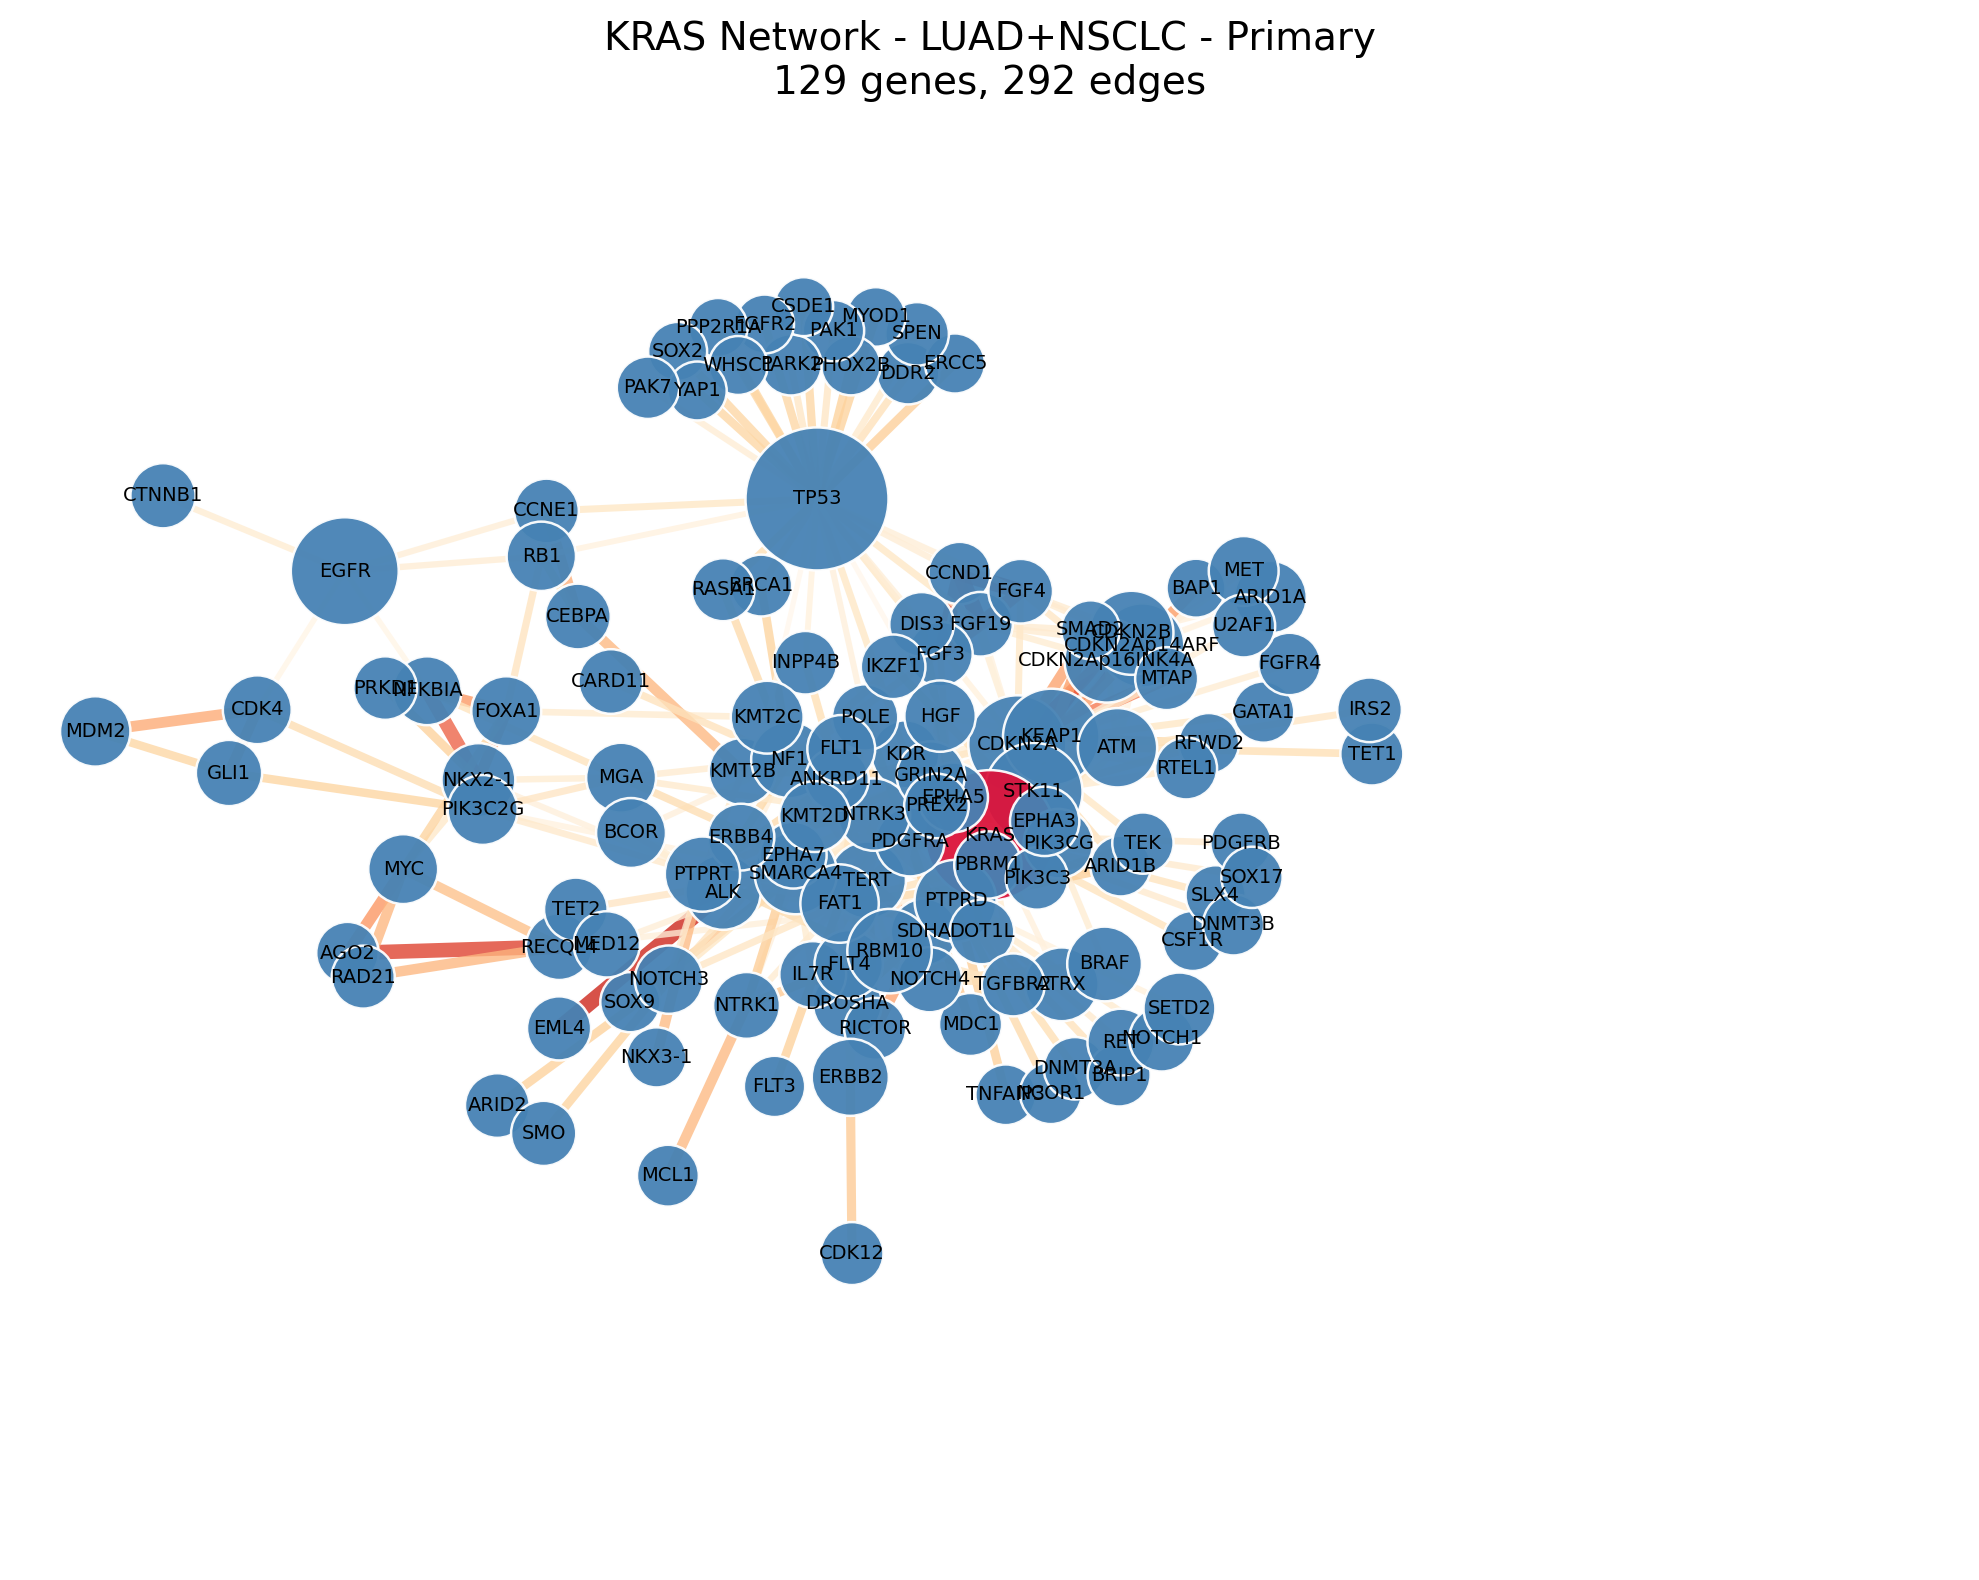


ONCOTREE GROUP: LUAD_NSCLC (LUAD+NSCLC)
SAMPLE TYPE GROUP: Metastasis
Patients: 707
Genes: 587
Edges after filters: 823
KRAS subgraph: 211 genes, 821 edges


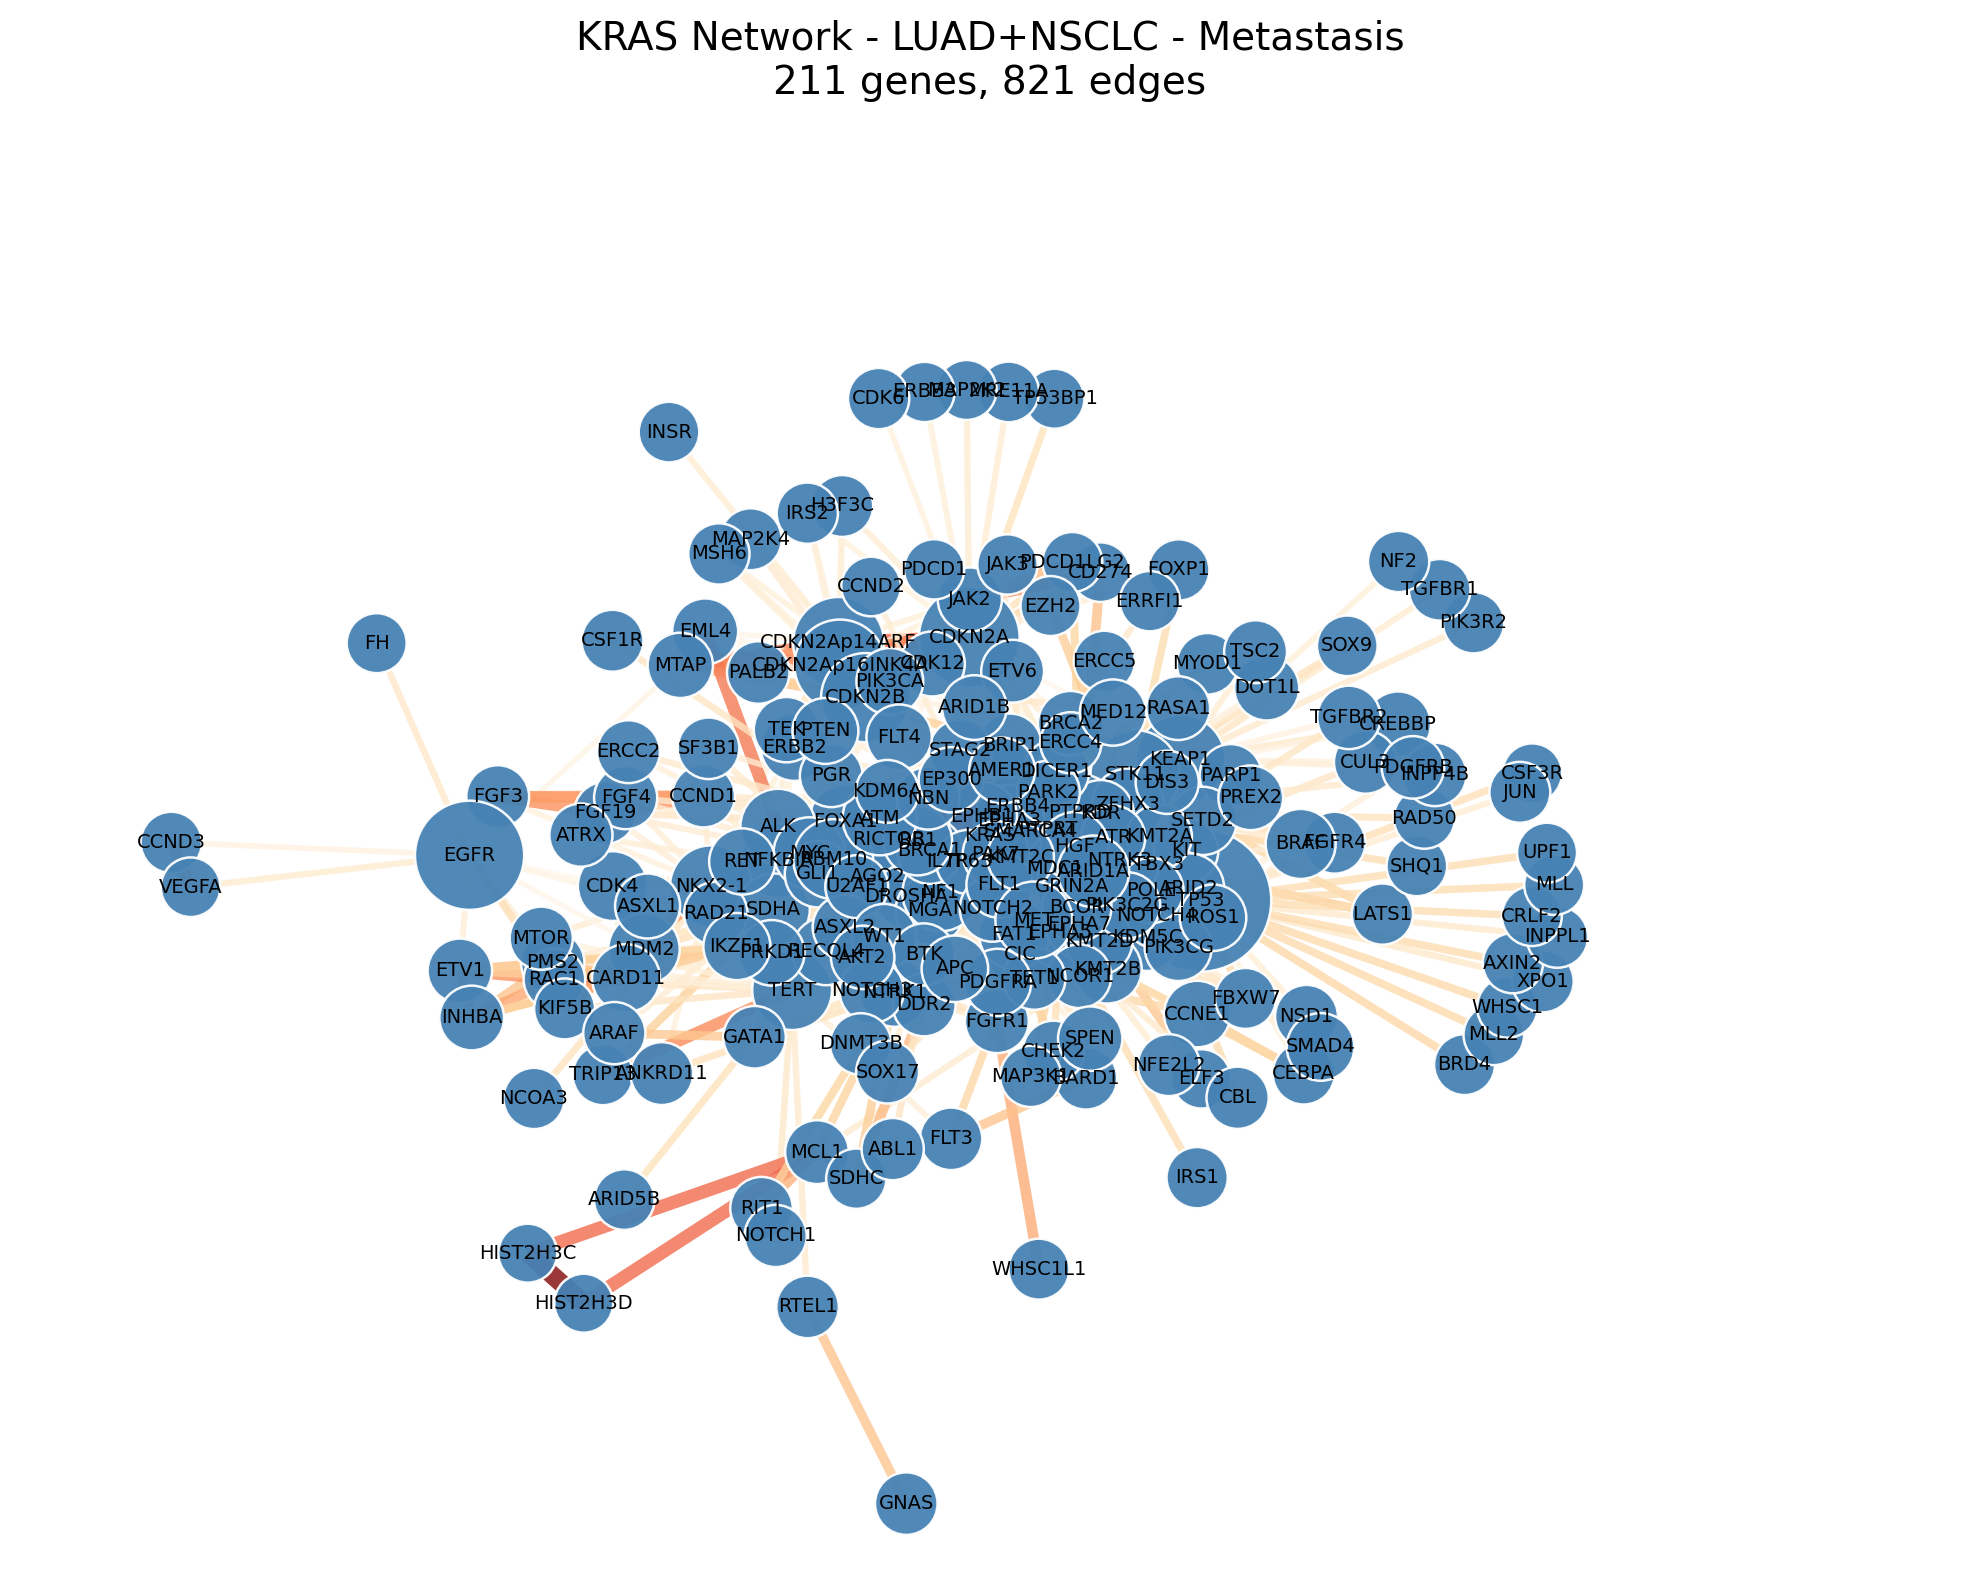


ONCOTREE GROUP: LUSC_NSCLC (LUSC+NSCLC)
SAMPLE TYPE GROUP: Primary
Patients: 104
Genes: 389
Edges after filters: 36
KRAS subgraph: 3 genes, 3 edges


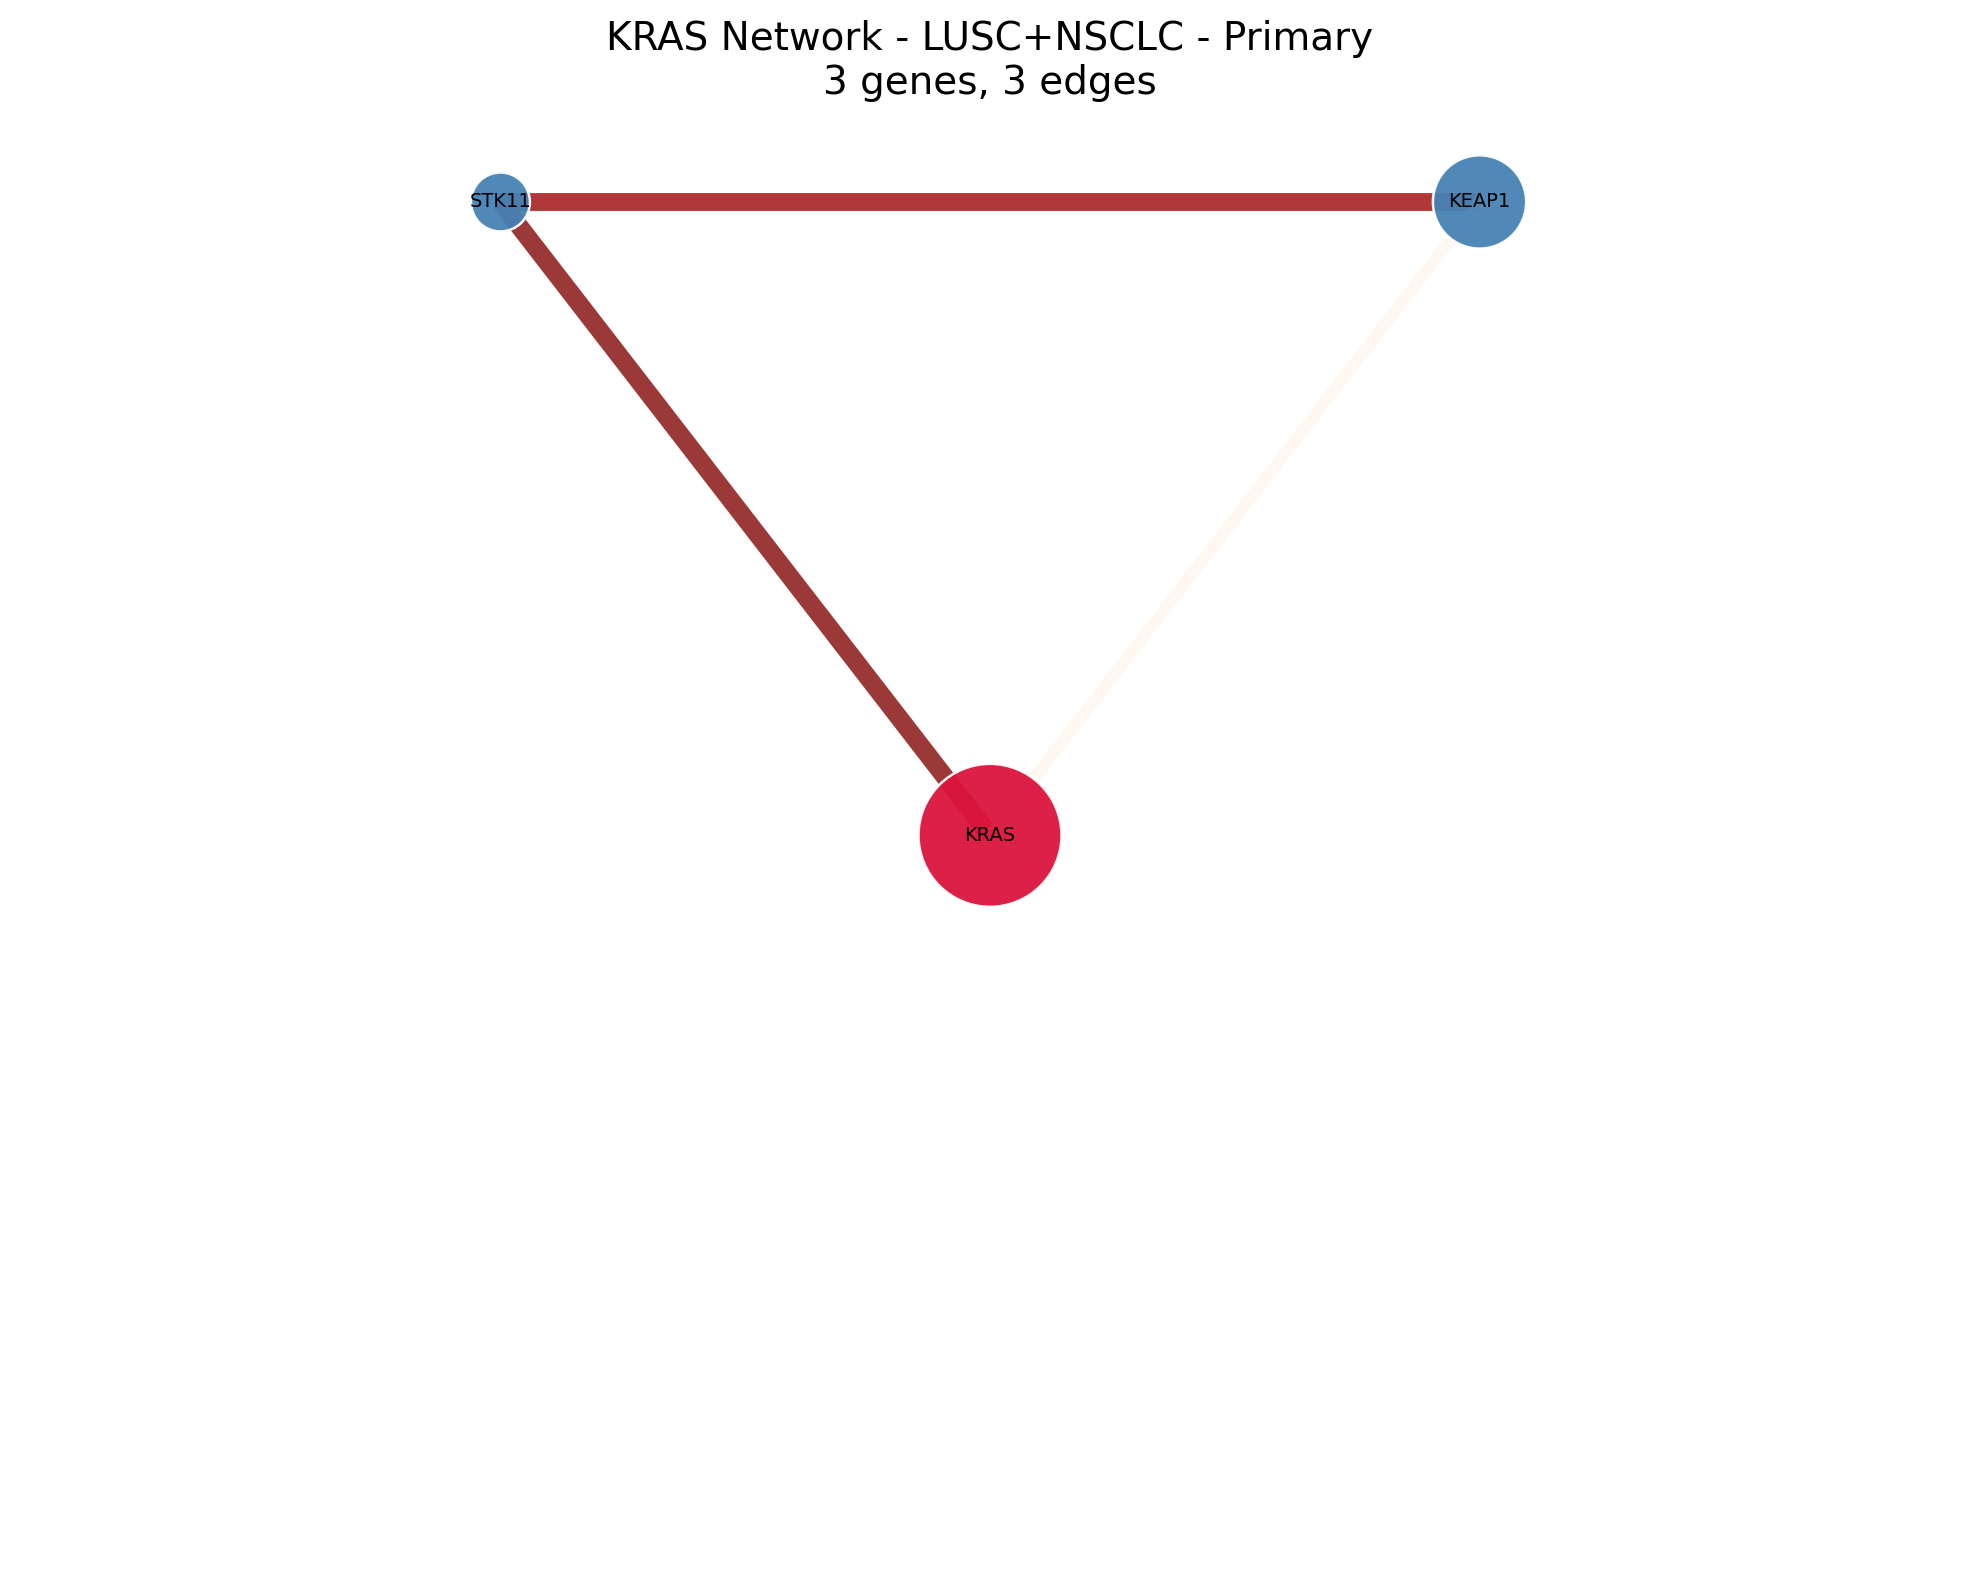


ONCOTREE GROUP: LUSC_NSCLC (LUSC+NSCLC)
SAMPLE TYPE GROUP: Metastasis
Patients: 107
Genes: 394
Edges after filters: 70
KRAS subgraph: 5 genes, 5 edges


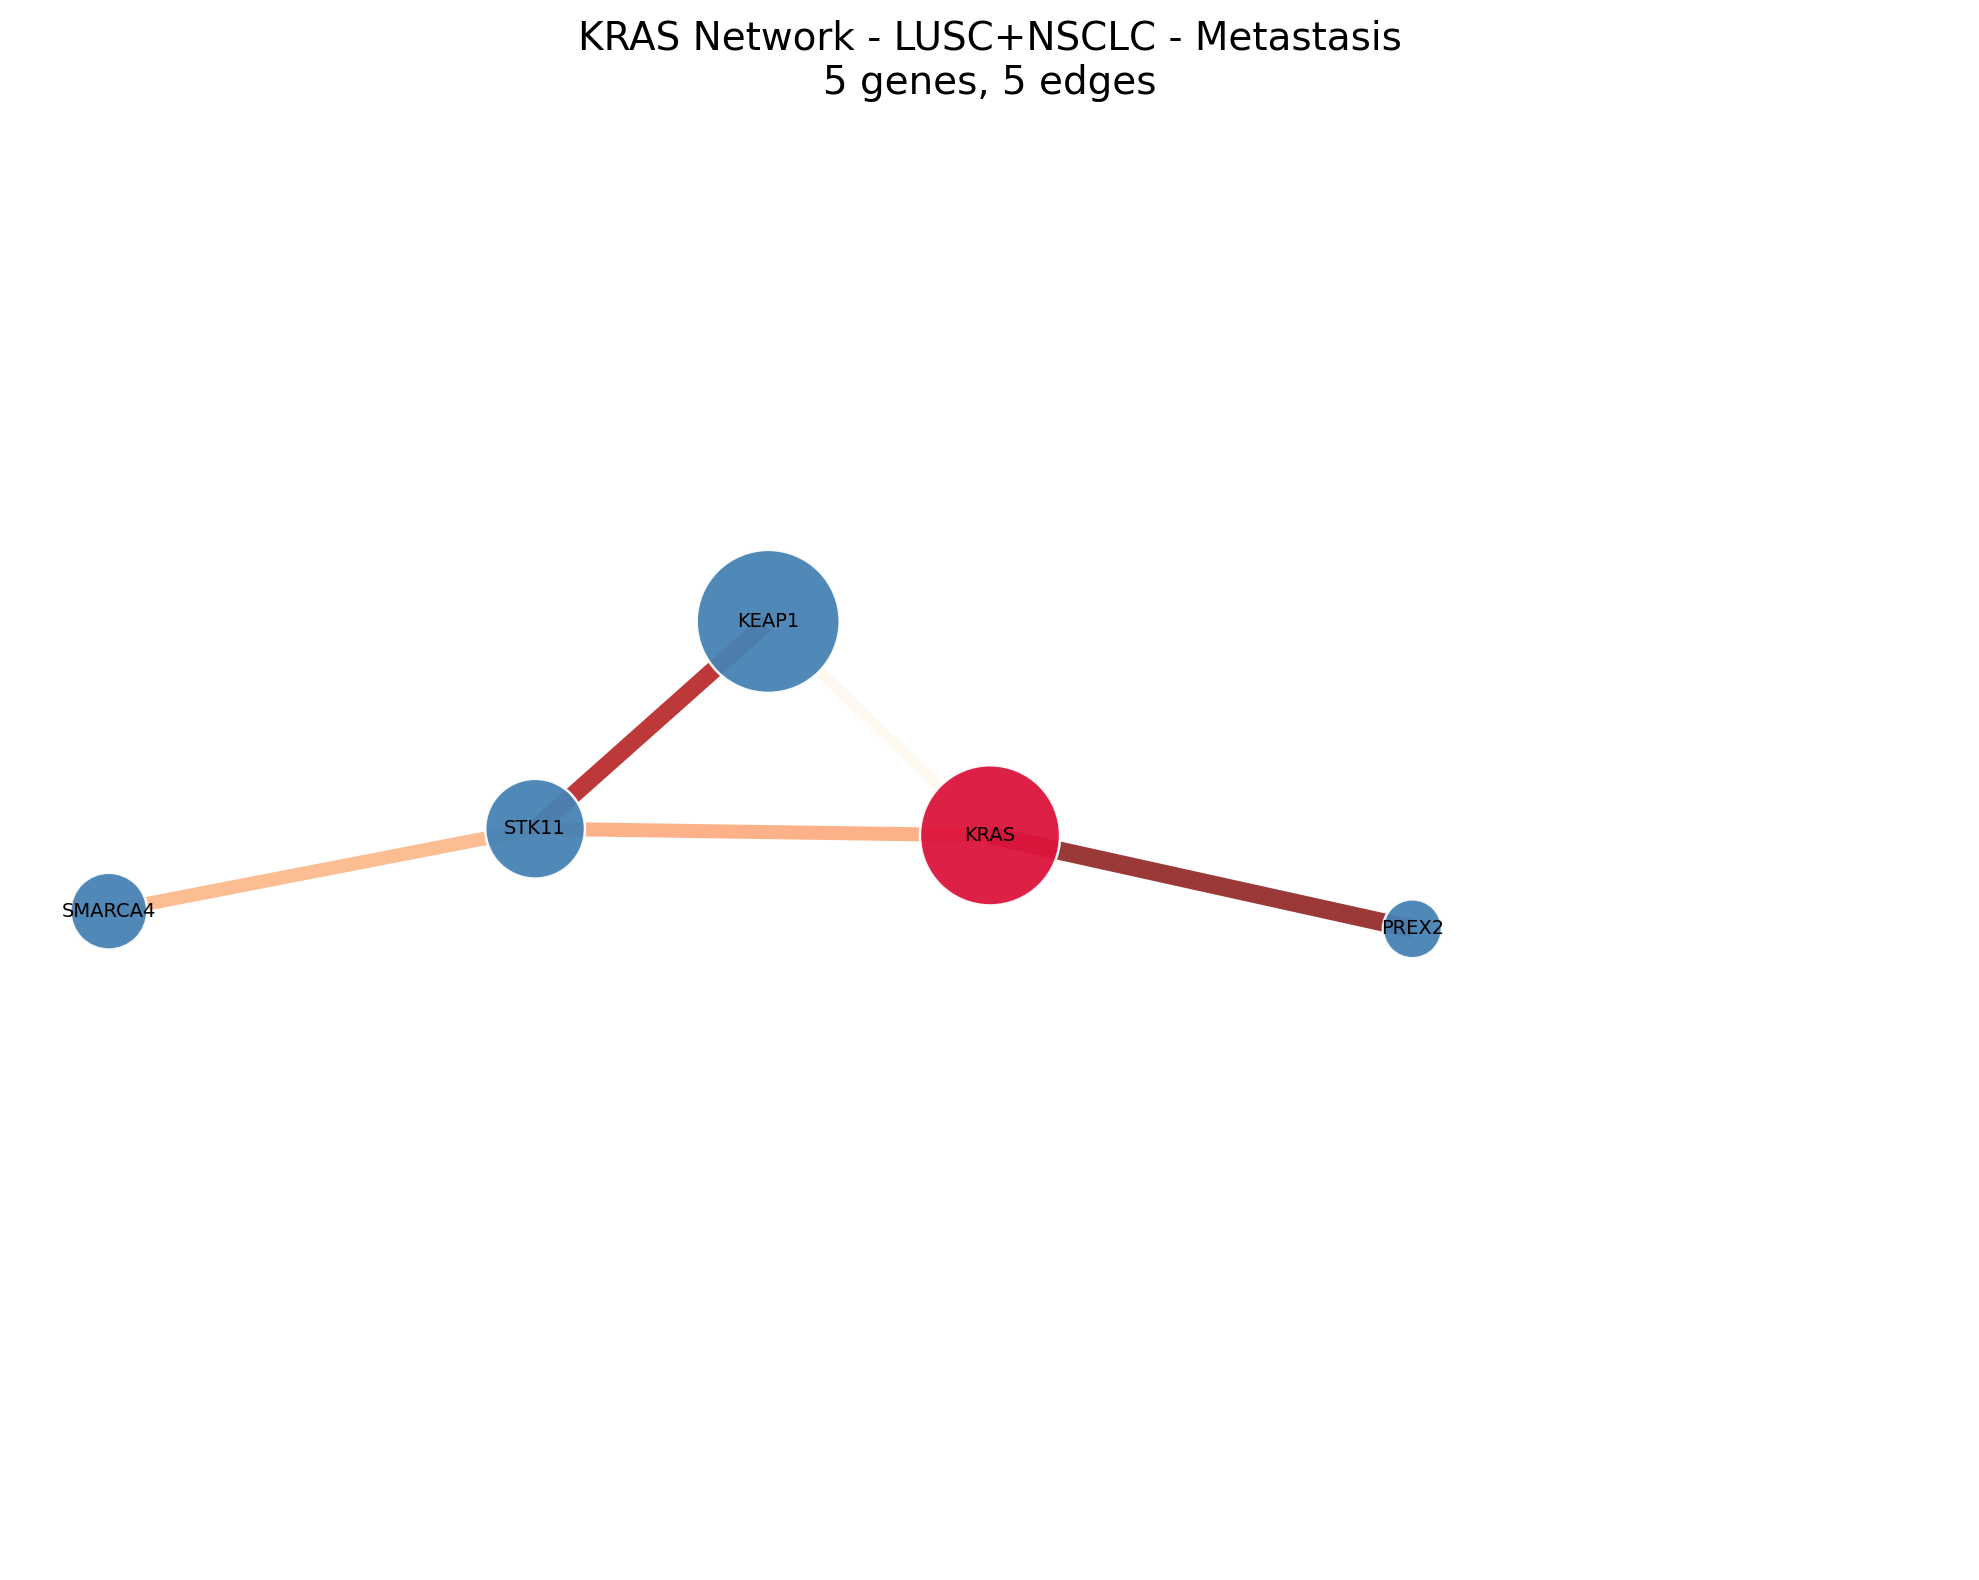


Clinical-to-network summary by Oncotree Group and Sample Type group:


,Oncotree_Group,Included_Oncotree_Codes,sample_type_group,n_patients,n_rows,n_genes_input,graph_nodes,graph_edges,contains_KRAS
0,LUAD_NSCLC,LUAD+NSCLC,Metastasis,707,8123,587,211,821,True
1,LUAD_NSCLC,LUAD+NSCLC,Primary,488,4942,541,129,292,True
2,LUSC_NSCLC,LUSC+NSCLC,Metastasis,107,1529,394,5,5,True
3,LUSC_NSCLC,LUSC+NSCLC,Primary,104,1431,389,3,3,True


In [22]:
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
import numpy as np
from pathlib import Path
from scipy.stats import fisher_exact


# ============================================================
# SETTINGS
# ============================================================

min_log2_or = 1
max_p_value = 0.05
min_shared = 5
max_hops_from_kras = None

min_patients_for_network = 10

# File nuovo, già annotato con sample_type_group stratificato per gruppi Oncotree
file_path_merged = (
        Path("data_lung")
        / "CLINICAL_merged_mutations_cna_sv_with_sample_type_groups_BY_ONCOTREE_GROUPS.csv"
)

# Gruppi istologici da analizzare
selected_oncotree_groups = ["LUAD_NSCLC", "LUSC_NSCLC"]

group_labels = {
    "LUAD_NSCLC": "LUAD+NSCLC",
    "LUSC_NSCLC": "LUSC+NSCLC",
}

# Gruppi Sample Type da analizzare
sample_type_groups_to_analyze = [
    "Primary",
    "Metastasis"
]


# ============================================================
# FUNCTION: build KRAS-focused graph for one Oncotree Group + Sample Type group
# ============================================================

def build_kras_network_for_oncotree_sample_type_group(
        df,
        oncotree_group,
        group_name,
        oncotree_col="Oncotree_Group",
        group_col="sample_type_group",
        patient_col="Patient_ID",
        gene_col="Hugo_Symbol",
        min_log2_or=1,
        max_p_value=0.05,
        min_shared=5,
        max_hops_from_kras=None,
        min_patients_for_network=10
):

    readable_group = group_labels.get(oncotree_group, oncotree_group)

    df_group = df[
        (df[oncotree_col] == oncotree_group)
        & (df[group_col] == group_name)
        ].copy()

    tmp = (
        df_group[[patient_col, gene_col]]
        .dropna()
        .drop_duplicates()
    )

    print("\n" + "=" * 90)
    print(f"ONCOTREE GROUP: {oncotree_group} ({readable_group})")
    print(f"SAMPLE TYPE GROUP: {group_name}")
    print(f"Patients: {tmp[patient_col].nunique()}")
    print(f"Genes: {tmp[gene_col].nunique()}")

    if tmp[patient_col].nunique() < min_patients_for_network:
        print(f"Skipped: fewer than {min_patients_for_network} patients.")
        return None, None, df_group

    if tmp[gene_col].nunique() < 2:
        print("Skipped: fewer than 2 genes.")
        return None, None, df_group

    patient_gene = pd.crosstab(
        tmp[patient_col],
        tmp[gene_col]
    ).astype(bool).astype(int)

    N = patient_gene.shape[0]
    gene_counts = patient_gene.sum(axis=0)

    co = patient_gene.T @ patient_gene

    co_np = co.to_numpy(copy=True)
    np.fill_diagonal(co_np, 0)

    co = pd.DataFrame(
        co_np,
        index=co.index,
        columns=co.columns
    )

    edges = (
        co.where(np.triu(np.ones(co.shape), k=1).astype(bool))
        .stack()
        .rename("a_both")
        .rename_axis(index=["Gene1", "Gene2"])
        .reset_index()
    )

    edges = edges.dropna(subset=["a_both"]).copy()
    edges["a_both"] = edges["a_both"].astype(int)

    rows = []

    for r in edges.itertuples(index=False):
        g1, g2, a = r.Gene1, r.Gene2, int(r.a_both)

        b = int(gene_counts[g1] - a)
        c = int(gene_counts[g2] - a)
        d = int(N - a - b - c)

        odds_ratio, p_value = fisher_exact(
            [[a, b], [c, d]],
            alternative="greater"
        )

        log2_or = np.log2(
            ((a + 0.5) * (d + 0.5)) /
            ((b + 0.5) * (c + 0.5))
        )

        rows.append([
            g1,
            g2,
            a,
            b,
            c,
            d,
            odds_ratio,
            log2_or,
            p_value
        ])

    results = pd.DataFrame(
        rows,
        columns=[
            "Gene1",
            "Gene2",
            "a_both",
            "b_g1_only",
            "c_g2_only",
            "d_neither",
            "odds_ratio",
            "log2_OR",
            "p_value"
        ]
    )

    results["Oncotree_Group"] = oncotree_group
    results["Included_Oncotree_Codes"] = readable_group
    results["sample_type_group"] = group_name
    results["n_patients_group"] = N

    edges_plot = (
        results[
            (results["log2_OR"] > min_log2_or)
            & (results["p_value"] < max_p_value)
            & (results["a_both"] >= min_shared)
            ]
        .sort_values(["p_value", "log2_OR"], ascending=[True, False])
        .copy()
    )

    print(f"Edges after filters: {len(edges_plot)}")

    G_plot = nx.Graph()

    for _, row in edges_plot.iterrows():
        G_plot.add_edge(
            row["Gene1"],
            row["Gene2"],
            log2_or=float(row["log2_OR"]),
            p_value=float(row["p_value"]),
            shared=int(row["a_both"]),
            oncotree_group=oncotree_group,
            included_oncotree_codes=readable_group,
            sample_type_group=group_name
        )

    if G_plot.number_of_nodes() == 0 or G_plot.number_of_edges() == 0:
        print("No edges with current thresholds.")
        return G_plot, results, df_group

    kras_nodes = [
        n for n in G_plot.nodes()
        if str(n).upper() == "KRAS"
    ]

    if not kras_nodes:
        print("KRAS is not present with these thresholds.")
        return G_plot, results, df_group

    kras_node = kras_nodes[0]

    distances = nx.single_source_shortest_path_length(
        G_plot,
        kras_node
    )

    if max_hops_from_kras is None:
        keep_nodes = set(distances.keys())
    else:
        keep_nodes = {
            n for n, d in distances.items()
            if d <= max_hops_from_kras
        }

    G_kras = G_plot.subgraph(keep_nodes).copy()

    print(
        f"KRAS subgraph: "
        f"{G_kras.number_of_nodes()} genes, "
        f"{G_kras.number_of_edges()} edges"
    )

    return G_kras, results, df_group


# ============================================================
# FUNCTION: plot KRAS-focused graph
# ============================================================

def plot_kras_network(
        G_kras,
        df_group,
        oncotree_group,
        group_name,
        patient_col="Patient_ID",
        gene_col="Hugo_Symbol"
):

    readable_group = group_labels.get(oncotree_group, oncotree_group)

    if G_kras is None or G_kras.number_of_edges() == 0:
        print(f"No graph to plot for {oncotree_group} - {group_name}")
        return

    kras_nodes = [
        n for n in G_kras.nodes()
        if str(n).upper() == "KRAS"
    ]

    if not kras_nodes:
        print(f"KRAS not found in graph for {oncotree_group} - {group_name}")
        return

    kras_node = kras_nodes[0]

    tmp = (
        df_group[[patient_col, gene_col]]
        .dropna()
        .drop_duplicates()
    )

    patient_gene = pd.crosstab(
        tmp[patient_col],
        tmp[gene_col]
    ).astype(bool).astype(int)

    gene_support = patient_gene.sum(axis=0).to_dict()

    plt.figure(figsize=(10, 8), dpi=200)

    local_dist = nx.single_source_shortest_path_length(
        G_kras,
        kras_node
    )

    max_d = max(local_dist.values())

    shells = [[kras_node]] + [
        [n for n in G_kras.nodes() if local_dist[n] == d]
        for d in range(1, max_d + 1)
    ]

    pos0 = nx.shell_layout(G_kras, nlist=shells)
    pos0[kras_node] = np.array([0.0, 0.0])

    pos = nx.spring_layout(
        G_kras,
        seed=42,
        k=0.9,
        pos=pos0,
        fixed=[kras_node],
        center=(0, 0),
        iterations=200
    )

    support_vals = [
        float(gene_support.get(n, 1))
        for n in G_kras.nodes()
    ]

    s_min = min(support_vals) if support_vals else 1.0
    s_max = max(support_vals) if support_vals else 1.0

    if s_max == s_min:
        node_sizes = [1000 for _ in G_kras.nodes()]
    else:
        node_sizes = [
            450 + 2200 *
            ((float(gene_support.get(n, s_min)) - s_min) / (s_max - s_min))
            for n in G_kras.nodes()
        ]

    node_colors = [
        "crimson" if str(n).upper() == "KRAS" else "steelblue"
        for n in G_kras.nodes()
    ]

    edge_vals = [
        G_kras[u][v].get("log2_or", 1.0)
        for u, v in G_kras.edges()
    ]

    max_edge = max(edge_vals) if edge_vals else 1.0

    edge_widths = [
        1.4 + 5.2 * (w / max_edge)
        for w in edge_vals
    ]

    nx.draw_networkx_edges(
        G_kras,
        pos,
        width=edge_widths,
        alpha=0.78,
        edge_color=edge_vals,
        edge_cmap=plt.cm.OrRd,
        edge_vmin=min(edge_vals) if edge_vals else 0.0,
        edge_vmax=max(edge_vals) if edge_vals else 1.0
    )

    nx.draw_networkx_nodes(
        G_kras,
        pos,
        node_size=node_sizes,
        node_color=node_colors,
        alpha=0.95,
        linewidths=0.9,
        edgecolors="white"
    )

    labels_all = {n: n for n in G_kras.nodes()}

    nx.draw_networkx_labels(
        G_kras,
        pos,
        labels=labels_all,
        font_size=7
    )

    xy = np.array(list(pos.values()))

    r = float(np.abs(xy).max()) if xy.size else 1.0
    lim = r + (0.08 * r + 0.05)

    plt.xlim(-lim, lim)
    plt.ylim(-lim, lim)

    plt.title(
        f"KRAS Network - {readable_group} - {group_name}\n"
        f"{G_kras.number_of_nodes()} genes, {G_kras.number_of_edges()} edges",
        fontsize=14
    )

    plt.axis("off")
    plt.tight_layout()
    plt.show()


# ============================================================
# LOAD DATA
# ============================================================

df_merge = pd.read_csv(file_path_merged, low_memory=False)
df_merge = df_merge.loc[:, ~df_merge.columns.duplicated()].copy()

df_merge = df_merge.rename(columns={
    "PATIENT_ID": "Patient_ID",
    "ONCOTREE_CODE": "ONCOTREE_CODE",
    "Oncotree Code": "ONCOTREE_CODE",
    "Oncotree_Group": "Oncotree_Group",
    "ONCOTREE_GROUP": "Oncotree_Group",
    "Oncotree Group": "Oncotree_Group",
    "Gene": "Hugo_Symbol",

    "Sample Type": "SAMPLE_TYPE",
    "Sample_Type": "SAMPLE_TYPE",
    "sample_type": "SAMPLE_TYPE",
    "SAMPLE_TYPE": "SAMPLE_TYPE",

    "SAMPLE_TYPE_GROUP": "sample_type_group",
    "sample_type_group": "sample_type_group"
})

df_merge = df_merge.loc[:, ~df_merge.columns.duplicated()].copy()

required_cols = {
    "Patient_ID",
    "Hugo_Symbol",
    "Oncotree_Group",
    "sample_type_group"
}

missing_cols = required_cols - set(df_merge.columns)

if missing_cols:
    raise ValueError(
        f"Colonne mancanti nel file merged clinical-to-network per gruppi: {missing_cols}"
    )

df_merge["Patient_ID"] = df_merge["Patient_ID"].astype(str)
df_merge["Hugo_Symbol"] = df_merge["Hugo_Symbol"].astype(str)
df_merge["Oncotree_Group"] = df_merge["Oncotree_Group"].astype(str)
df_merge["sample_type_group"] = df_merge["sample_type_group"].astype(str)

if "Included_Oncotree_Codes" not in df_merge.columns:
    df_merge["Included_Oncotree_Codes"] = df_merge["Oncotree_Group"].map(group_labels)

print("Loaded:")
print(file_path_merged)

print("\nSample Type group distribution by Oncotree Group:")

try:
    display(
        df_merge
        .drop_duplicates(["Patient_ID", "Oncotree_Group", "sample_type_group"])
        .groupby(["Oncotree_Group", "Included_Oncotree_Codes", "sample_type_group"])
        .agg(n_patients=("Patient_ID", "nunique"))
        .reset_index()
        .sort_values(["Oncotree_Group", "sample_type_group"])
    )
except NameError:
    print(
        df_merge
        .drop_duplicates(["Patient_ID", "Oncotree_Group", "sample_type_group"])
        .groupby(["Oncotree_Group", "Included_Oncotree_Codes", "sample_type_group"])
        .agg(n_patients=("Patient_ID", "nunique"))
        .reset_index()
        .sort_values(["Oncotree_Group", "sample_type_group"])
    )


# ============================================================
# SELECT ONCOTREE GROUPS
# ============================================================

if selected_oncotree_groups is None:
    oncotree_groups_to_analyze = sorted(
        df_merge["Oncotree_Group"]
        .dropna()
        .unique()
    )
else:
    oncotree_groups_to_analyze = selected_oncotree_groups

oncotree_groups_to_analyze = [
    g for g in oncotree_groups_to_analyze
    if g in df_merge["Oncotree_Group"].unique()
]

print("\nOncotree Groups to analyze:")
print(oncotree_groups_to_analyze)


# ============================================================
# BUILD AND PLOT NETWORKS BY ONCOTREE GROUP AND SAMPLE TYPE GROUP
# ============================================================

graphs_by_oncotree_sample_type = {}
results_by_oncotree_sample_type = {}

for oncotree_group in oncotree_groups_to_analyze:

    graphs_by_oncotree_sample_type[oncotree_group] = {}
    results_by_oncotree_sample_type[oncotree_group] = {}

    for group_name in sample_type_groups_to_analyze:

        G_group, results_group, df_group = build_kras_network_for_oncotree_sample_type_group(
            df=df_merge,
            oncotree_group=oncotree_group,
            group_name=group_name,
            oncotree_col="Oncotree_Group",
            group_col="sample_type_group",
            patient_col="Patient_ID",
            gene_col="Hugo_Symbol",
            min_log2_or=min_log2_or,
            max_p_value=max_p_value,
            min_shared=min_shared,
            max_hops_from_kras=max_hops_from_kras,
            min_patients_for_network=min_patients_for_network
        )

        graphs_by_oncotree_sample_type[oncotree_group][group_name] = G_group
        results_by_oncotree_sample_type[oncotree_group][group_name] = results_group

        plot_kras_network(
            G_kras=G_group,
            df_group=df_group,
            oncotree_group=oncotree_group,
            group_name=group_name,
            patient_col="Patient_ID",
            gene_col="Hugo_Symbol"
        )


# ============================================================
# FINAL SUMMARY
# ============================================================

summary_rows = []

for oncotree_group, group_dict in graphs_by_oncotree_sample_type.items():

    readable_group = group_labels.get(oncotree_group, oncotree_group)

    for group_name, G in group_dict.items():

        if G is None:
            n_nodes = 0
            n_edges = 0
            has_kras = False
        else:
            n_nodes = G.number_of_nodes()
            n_edges = G.number_of_edges()
            has_kras = any(str(n).upper() == "KRAS" for n in G.nodes())

        df_tmp = df_merge[
            (df_merge["Oncotree_Group"] == oncotree_group)
            & (df_merge["sample_type_group"] == group_name)
            ]

        summary_rows.append({
            "Oncotree_Group": oncotree_group,
            "Included_Oncotree_Codes": readable_group,
            "sample_type_group": group_name,
            "n_patients": df_tmp["Patient_ID"].nunique(),
            "n_rows": df_tmp.shape[0],
            "n_genes_input": df_tmp["Hugo_Symbol"].nunique(),
            "graph_nodes": n_nodes,
            "graph_edges": n_edges,
            "contains_KRAS": has_kras
        })

clinical_network_summary = (
    pd.DataFrame(summary_rows)
    .sort_values(["Oncotree_Group", "sample_type_group"])
    .reset_index(drop=True)
)

print("\nClinical-to-network summary by Oncotree Group and Sample Type group:")

try:
    display(clinical_network_summary)
except NameError:
    print(clinical_network_summary)


# ============================================================
# COMPATIBILITY ALIASES
# ============================================================

graphs_by_oncotree_group_sample_type = graphs_by_oncotree_sample_type
results_by_oncotree_group_sample_type = results_by_oncotree_sample_type

#### 3. Hub analysis e confronto HIGH vs LOW

In [23]:
import pandas as pd
import numpy as np
import networkx as nx
from pathlib import Path
import re

# ============================================================
# HUB ANALYSIS - ONCOTREE GROUPS ORIENTED
# SAMPLE TYPE networks within each Oncotree Group
# LUAD_NSCLC = LUAD + NSCLC
# LUSC_NSCLC = LUSC + NSCLC
# ============================================================

# Compatibilità con i nomi creati nella cella precedente
if "graphs_by_oncotree_sample_type" not in globals():
    if "graphs_by_oncotree_group_sample_type" in globals():
        graphs_by_oncotree_sample_type = graphs_by_oncotree_group_sample_type
    else:
        raise ValueError(
            "graphs_by_oncotree_sample_type non disponibile. "
            "Esegui prima la cella che costruisce le network per sample_type_group "
            "per Oncotree Group."
        )

target_groups = ["LUAD_NSCLC", "LUSC_NSCLC"]

group_labels = {
    "LUAD_NSCLC": "LUAD+NSCLC",
    "LUSC_NSCLC": "LUSC+NSCLC",
}

sample_type_groups_to_compare = [
    "Primary",
    "Metastasis"
]

hub_output_dir = (
        Path("data_lung")
        / "clinical_to_network_by_oncotree_groups_sample_type"
        / "hub_analysis_by_oncotree_group_sample_type"
)

hub_output_dir.mkdir(parents=True, exist_ok=True)


# ============================================================
# Helper
# ============================================================

def safe_filename(text):
    text = str(text)
    text = re.sub(r"[^A-Za-z0-9_-]+", "_", text)
    return text.strip("_")


# ============================================================
# FUNCTION: compute hub table
# ============================================================

def compute_hub_table(
        G,
        oncotree_group,
        group_name,
        weight_col="log2_or"
):
    """
    Calcola le metriche hub per una network specifica:
    - un Oncotree Group: LUAD_NSCLC / LUSC_NSCLC
    - un Sample Type group: Primary / Metastasis
    """

    readable_group = group_labels.get(oncotree_group, oncotree_group)

    if G is None or G.number_of_nodes() == 0 or G.number_of_edges() == 0:
        print(f"No graph available for {oncotree_group} - {group_name}")
        return pd.DataFrame()

    degree = dict(G.degree())

    node_strength = {
        n: sum(
            G[n][nbr].get(weight_col, 1.0)
            for nbr in G.neighbors(n)
        )
        for n in G.nodes()
    }

    betweenness = nx.betweenness_centrality(
        G,
        weight=weight_col,
        normalized=True
    )

    closeness = nx.closeness_centrality(G)

    hub_df = pd.DataFrame({
        "Oncotree_Group": oncotree_group,
        "Included_Oncotree_Codes": readable_group,
        "sample_type_group": group_name,
        "Gene": list(G.nodes()),
        "Degree": [degree.get(g, 0) for g in G.nodes()],
        "Node_Strength": [node_strength.get(g, 0) for g in G.nodes()],
        "Betweenness": [betweenness.get(g, 0) for g in G.nodes()],
        "Closeness": [closeness.get(g, 0) for g in G.nodes()],
        "Graph_nodes": G.number_of_nodes(),
        "Graph_edges": G.number_of_edges(),
        "Graph_density": nx.density(G)
    })

    # HubScore composito
    hub_df["HubScore"] = (
            hub_df["Degree"].rank(pct=True) * 0.25
            + hub_df["Node_Strength"].rank(pct=True) * 0.25
            + hub_df["Betweenness"].rank(pct=True) * 0.25
            + hub_df["Closeness"].rank(pct=True) * 0.25
    )

    hub_df = hub_df.sort_values(
        "HubScore",
        ascending=False
    ).reset_index(drop=True)

    hub_df["Rank_in_network"] = hub_df.index + 1

    return hub_df


# ============================================================
# 1. Compute hub tables for each Oncotree Group and Sample Type group
# ============================================================

hub_tables_by_oncotree_sample_type = {}
all_hub_tables_sample_type = []

for oncotree_group, group_graphs in graphs_by_oncotree_sample_type.items():

    if oncotree_group not in target_groups:
        continue

    readable_group = group_labels.get(oncotree_group, oncotree_group)

    hub_tables_by_oncotree_sample_type[oncotree_group] = {}

    for group_name, G in group_graphs.items():

        hub_df = compute_hub_table(
            G=G,
            oncotree_group=oncotree_group,
            group_name=group_name
        )

        hub_tables_by_oncotree_sample_type[oncotree_group][group_name] = hub_df

        if not hub_df.empty:
            all_hub_tables_sample_type.append(hub_df)

            safe_group_name = safe_filename(group_name)

            output_file = (
                    hub_output_dir
                    / f"hub_genes_{oncotree_group}_{safe_group_name}_sample_type_network.csv"
            )

            hub_df.to_csv(output_file, index=False)

            print(f"Saved: {output_file}")


# ============================================================
# 2. Combined hub table
# ============================================================

if len(all_hub_tables_sample_type) > 0:
    hub_all_oncotree_sample_type = pd.concat(
        all_hub_tables_sample_type,
        ignore_index=True
    )

    hub_all_file = (
            hub_output_dir
            / "hub_genes_all_oncotree_group_sample_type_networks.csv"
    )

    hub_all_oncotree_sample_type.to_csv(
        hub_all_file,
        index=False
    )

    print("\nSaved combined hub table:")
    print(hub_all_file)

else:
    hub_all_oncotree_sample_type = pd.DataFrame()
    print("No hub tables were created.")


# ============================================================
# 3. Display top hubs per Oncotree Group and Sample Type group
# ============================================================

top_n = 20

for oncotree_group, group_tables in hub_tables_by_oncotree_sample_type.items():

    readable_group = group_labels.get(oncotree_group, oncotree_group)

    print("\n" + "#" * 100)
    print(f"ONCOTREE GROUP: {oncotree_group} ({readable_group})")
    print("#" * 100)

    for group_name in sample_type_groups_to_compare:

        hub_df = group_tables.get(group_name, pd.DataFrame())

        print("\n" + "=" * 90)
        print(
            f"TOP HUB GENES - {oncotree_group} ({readable_group}) - "
            f"{group_name.upper()} NETWORK"
        )
        print("=" * 90)

        if hub_df is None or hub_df.empty:
            print(f"No hub table available for {oncotree_group} - {group_name}")
            continue

        print(
            f"Questa tabella mostra i geni più centrali nella rete costruita solo sui pazienti "
            f"{group_name} del gruppo {readable_group}."
        )

        display(
            hub_df[
                [
                    "Oncotree_Group",
                    "Included_Oncotree_Codes",
                    "sample_type_group",
                    "Gene",
                    "Degree",
                    "Node_Strength",
                    "Betweenness",
                    "Closeness",
                    "HubScore",
                    "Rank_in_network"
                ]
            ].head(top_n)
        )


# ============================================================
# 4. Compare Primary vs Metastasis hub scores
#    within each Oncotree Group
# ============================================================

comparison_tables = []

primary_label = "Primary"
metastasis_label = "Metastasis"

for oncotree_group, group_tables in hub_tables_by_oncotree_sample_type.items():

    readable_group = group_labels.get(oncotree_group, oncotree_group)

    hub_primary = group_tables.get(primary_label, pd.DataFrame())
    hub_metastasis = group_tables.get(metastasis_label, pd.DataFrame())

    if hub_primary is None or hub_primary.empty:
        print(f"[{oncotree_group}] Primary hub table missing or empty. Skipping comparison.")
        continue

    if hub_metastasis is None or hub_metastasis.empty:
        print(f"[{oncotree_group}] Metastasis hub table missing or empty. Skipping comparison.")
        continue

    hub_primary_for_merge = hub_primary.copy()
    hub_metastasis_for_merge = hub_metastasis.copy()

    hub_primary_for_merge = hub_primary_for_merge.drop(
        columns=["sample_type_group"],
        errors="ignore"
    )

    hub_metastasis_for_merge = hub_metastasis_for_merge.drop(
        columns=["sample_type_group"],
        errors="ignore"
    )

    hub_comparison = hub_primary_for_merge.merge(
        hub_metastasis_for_merge,
        on=["Oncotree_Group", "Included_Oncotree_Codes", "Gene"],
        how="outer",
        suffixes=("_primary", "_metastasis")
    )

    hub_comparison["Delta_HubScore_primary_minus_metastasis"] = (
            hub_comparison["HubScore_primary"].fillna(0)
            - hub_comparison["HubScore_metastasis"].fillna(0)
    )

    hub_comparison["Delta_Degree_primary_minus_metastasis"] = (
            hub_comparison["Degree_primary"].fillna(0)
            - hub_comparison["Degree_metastasis"].fillna(0)
    )

    hub_comparison["Delta_Node_Strength_primary_minus_metastasis"] = (
            hub_comparison["Node_Strength_primary"].fillna(0)
            - hub_comparison["Node_Strength_metastasis"].fillna(0)
    )

    comparison_tables.append(hub_comparison)

    output_file = (
            hub_output_dir
            / f"hub_genes_{oncotree_group}_primary_vs_metastasis_comparison.csv"
    )

    hub_comparison.to_csv(output_file, index=False)

    print(f"\nSaved comparison for {oncotree_group}:")
    print(output_file)

    # ------------------------------------------------------------
    # Genes more important in Primary network
    # ------------------------------------------------------------

    print("\n" + "=" * 90)
    print(f"GENES MORE IMPORTANT IN PRIMARY NETWORK - {oncotree_group} ({readable_group})")
    print("=" * 90)
    print(
        "Delta positivo = il gene è più hub/importante nella rete Primary "
        "rispetto alla rete Metastasis, dentro lo stesso gruppo istologico."
    )

    display(
        hub_comparison
        .sort_values("Delta_HubScore_primary_minus_metastasis", ascending=False)
        [
            [
                "Oncotree_Group",
                "Included_Oncotree_Codes",
                "Gene",
                "HubScore_primary",
                "HubScore_metastasis",
                "Delta_HubScore_primary_minus_metastasis",
                "Degree_primary",
                "Degree_metastasis",
                "Node_Strength_primary",
                "Node_Strength_metastasis"
            ]
        ]
        .head(top_n)
    )

    # ------------------------------------------------------------
    # Genes more important in Metastasis network
    # ------------------------------------------------------------

    print("\n" + "=" * 90)
    print(f"GENES MORE IMPORTANT IN METASTASIS NETWORK - {oncotree_group} ({readable_group})")
    print("=" * 90)
    print(
        "Delta negativo = il gene è più hub/importante nella rete Metastasis "
        "rispetto alla rete Primary, dentro lo stesso gruppo istologico."
    )

    display(
        hub_comparison
        .sort_values("Delta_HubScore_primary_minus_metastasis", ascending=True)
        [
            [
                "Oncotree_Group",
                "Included_Oncotree_Codes",
                "Gene",
                "HubScore_primary",
                "HubScore_metastasis",
                "Delta_HubScore_primary_minus_metastasis",
                "Degree_primary",
                "Degree_metastasis",
                "Node_Strength_primary",
                "Node_Strength_metastasis"
            ]
        ]
        .head(top_n)
    )


# ============================================================
# 5. Combined comparison table
# ============================================================

if len(comparison_tables) > 0:
    hub_comparison_all_oncotree = pd.concat(
        comparison_tables,
        ignore_index=True
    )

    combined_comparison_file = (
            hub_output_dir
            / "hub_genes_primary_vs_metastasis_comparison_all_oncotree_groups.csv"
    )

    hub_comparison_all_oncotree.to_csv(
        combined_comparison_file,
        index=False
    )

    print("\nSaved combined Primary vs Metastasis comparison:")
    print(combined_comparison_file)

    print("\nCombined comparison preview:")

    display(
        hub_comparison_all_oncotree
        .sort_values(
            ["Oncotree_Group", "Delta_HubScore_primary_minus_metastasis"],
            ascending=[True, False]
        )
        .head(40)
    )

else:
    hub_comparison_all_oncotree = pd.DataFrame()
    print("No Primary vs Metastasis comparison table was created.")


# ============================================================
# OPTIONAL COMPATIBILITY ALIASES
# ============================================================

hub_tables_by_oncotree_group_sample_type = hub_tables_by_oncotree_sample_type
hub_comparison_all_oncotree_groups = hub_comparison_all_oncotree
hub_comparison_all_oncotree_sample_type = hub_comparison_all_oncotree

Saved: data_lung\clinical_to_network_by_oncotree_groups_sample_type\hub_analysis_by_oncotree_group_sample_type\hub_genes_LUAD_NSCLC_Primary_sample_type_network.csv
Saved: data_lung\clinical_to_network_by_oncotree_groups_sample_type\hub_analysis_by_oncotree_group_sample_type\hub_genes_LUAD_NSCLC_Metastasis_sample_type_network.csv
Saved: data_lung\clinical_to_network_by_oncotree_groups_sample_type\hub_analysis_by_oncotree_group_sample_type\hub_genes_LUSC_NSCLC_Primary_sample_type_network.csv
Saved: data_lung\clinical_to_network_by_oncotree_groups_sample_type\hub_analysis_by_oncotree_group_sample_type\hub_genes_LUSC_NSCLC_Metastasis_sample_type_network.csv

Saved combined hub table:
data_lung\clinical_to_network_by_oncotree_groups_sample_type\hub_analysis_by_oncotree_group_sample_type\hub_genes_all_oncotree_group_sample_type_networks.csv

####################################################################################################
ONCOTREE GROUP: LUAD_NSCLC (LUAD+NSCLC)
###########

,Oncotree_Group,Included_Oncotree_Codes,sample_type_group,Gene,Degree,Node_Strength,Betweenness,Closeness,HubScore,Rank_in_network
0,LUAD_NSCLC,LUAD+NSCLC,Primary,PTPRD,25,59.804449,0.195497,0.426667,0.992248,1
1,LUAD_NSCLC,LUAD+NSCLC,Primary,CDKN2A,23,69.599733,0.139887,0.422442,0.981589,2
2,LUAD_NSCLC,LUAD+NSCLC,Primary,TP53,28,72.472941,0.300689,0.395062,0.980620,3
3,LUAD_NSCLC,LUAD+NSCLC,Primary,KEAP1,21,49.190456,0.195005,0.415584,0.968992,4
4,LUAD_NSCLC,LUAD+NSCLC,Primary,FAT1,19,43.609372,0.121801,0.425249,0.965116,5
5,LUAD_NSCLC,LUAD+NSCLC,Primary,NF1,16,40.451186,0.054380,0.419672,0.941860,6
6,LUAD_NSCLC,LUAD+NSCLC,Primary,SMARCA4,14,28.618181,0.172490,0.398754,0.932171,7
7,LUAD_NSCLC,LUAD+NSCLC,Primary,PDGFRA,14,35.347314,0.039124,0.419672,0.926357,8
8,LUAD_NSCLC,LUAD+NSCLC,Primary,NTRK3,12,26.353967,0.068406,0.419672,0.920543,9
9,LUAD_NSCLC,LUAD+NSCLC,Primary,KRAS,14,26.152280,0.131767,0.384384,0.910853,10



TOP HUB GENES - LUAD_NSCLC (LUAD+NSCLC) - METASTASIS NETWORK
Questa tabella mostra i geni più centrali nella rete costruita solo sui pazienti Metastasis del gruppo LUAD+NSCLC.


,Oncotree_Group,Included_Oncotree_Codes,sample_type_group,Gene,Degree,Node_Strength,Betweenness,Closeness,HubScore,Rank_in_network
0,LUAD_NSCLC,LUAD+NSCLC,Metastasis,PTPRD,51,105.365329,0.172978,0.513447,0.998815,1
1,LUAD_NSCLC,LUAD+NSCLC,Metastasis,TP53,50,102.611245,0.252449,0.478360,0.992299,2
2,LUAD_NSCLC,LUAD+NSCLC,Metastasis,SMARCA4,39,71.195933,0.129779,0.490654,0.984597,3
3,LUAD_NSCLC,LUAD+NSCLC,Metastasis,PTPRT,47,98.905071,0.059604,0.483871,0.979858,4
4,LUAD_NSCLC,LUAD+NSCLC,Metastasis,NF1,37,66.996506,0.144270,0.472973,0.974526,5
5,LUAD_NSCLC,LUAD+NSCLC,Metastasis,EPHA3,33,70.938698,0.050854,0.489510,0.966825,6
6,LUAD_NSCLC,LUAD+NSCLC,Metastasis,KEAP1,36,63.588984,0.119025,0.454545,0.963270,7
7,LUAD_NSCLC,LUAD+NSCLC,Metastasis,CDKN2A,32,86.090659,0.110595,0.447761,0.961493,8
8,LUAD_NSCLC,LUAD+NSCLC,Metastasis,FAT1,35,77.867333,0.028025,0.478360,0.961493,9
9,LUAD_NSCLC,LUAD+NSCLC,Metastasis,NTRK3,34,77.539856,0.011255,0.472973,0.941351,10



####################################################################################################
ONCOTREE GROUP: LUSC_NSCLC (LUSC+NSCLC)
####################################################################################################

TOP HUB GENES - LUSC_NSCLC (LUSC+NSCLC) - PRIMARY NETWORK
Questa tabella mostra i geni più centrali nella rete costruita solo sui pazienti Primary del gruppo LUSC+NSCLC.


,Oncotree_Group,Included_Oncotree_Codes,sample_type_group,Gene,Degree,Node_Strength,Betweenness,Closeness,HubScore,Rank_in_network
0,LUSC_NSCLC,LUSC+NSCLC,Primary,STK11,2,6.905798,0.0,1.0,0.750000,1
1,LUSC_NSCLC,LUSC+NSCLC,Primary,KRAS,2,5.381892,0.0,1.0,0.666667,2
2,LUSC_NSCLC,LUSC+NSCLC,Primary,KEAP1,2,5.264014,0.0,1.0,0.583333,3


... (8 outputs left out)


GENES MORE IMPORTANT IN METASTASIS NETWORK - LUSC_NSCLC (LUSC+NSCLC)
Delta negativo = il gene è più hub/importante nella rete Metastasis rispetto alla rete Primary, dentro lo stesso gruppo istologico.


,Oncotree_Group,Included_Oncotree_Codes,Gene,HubScore_primary,HubScore_metastasis,Delta_HubScore_primary_minus_metastasis,Degree_primary,Degree_metastasis,Node_Strength_primary,Node_Strength_metastasis
2,LUSC_NSCLC,LUSC+NSCLC,PREX2,NaN,0.350,-0.350000,NaN,1,NaN,3.350497
3,LUSC_NSCLC,LUSC+NSCLC,SMARCA4,NaN,0.300,-0.300000,NaN,1,NaN,2.292389
1,LUSC_NSCLC,LUSC+NSCLC,KRAS,0.666667,0.875,-0.208333,2.0,3,5.381892,7.234118
4,LUSC_NSCLC,LUSC+NSCLC,STK11,0.750000,0.925,-0.175000,2.0,3,6.905798,7.807165
0,LUSC_NSCLC,LUSC+NSCLC,KEAP1,0.583333,0.550,0.033333,2.0,2,5.264014,4.678605



Saved combined Primary vs Metastasis comparison:
data_lung\clinical_to_network_by_oncotree_groups_sample_type\hub_analysis_by_oncotree_group_sample_type\hub_genes_primary_vs_metastasis_comparison_all_oncotree_groups.csv

Combined comparison preview:


,Oncotree_Group,Included_Oncotree_Codes,Gene,Degree_primary,Node_Strength_primary,Betweenness_primary,Closeness_primary,Graph_nodes_primary,Graph_edges_primary,Graph_density_primary,...,Betweenness_metastasis,Closeness_metastasis,Graph_nodes_metastasis,Graph_edges_metastasis,Graph_density_metastasis,HubScore_metastasis,Rank_in_network_metastasis,Delta_HubScore_primary_minus_metastasis,Delta_Degree_primary_minus_metastasis,Delta_Node_Strength_primary_minus_metastasis
159,LUAD_NSCLC,LUAD+NSCLC,PBRM1,4.0,9.907744,0.000000,0.365714,129.0,292.0,0.035368,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.584302,4.0,9.907744
198,LUAD_NSCLC,LUAD+NSCLC,SMAD2,2.0,11.360783,0.000000,0.316832,129.0,292.0,0.035368,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.471899,2.0,11.360783
167,LUAD_NSCLC,LUAD+NSCLC,PIK3C3,2.0,6.291339,0.000000,0.337731,129.0,292.0,0.035368,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.461240,2.0,6.291339
187,LUAD_NSCLC,LUAD+NSCLC,RFWD2,2.0,6.471711,0.000000,0.301176,129.0,292.0,0.035368,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.416667,2.0,6.471711
162,LUAD_NSCLC,LUAD+NSCLC,PDGFRA,14.0,35.347314,0.039124,0.419672,129.0,292.0,0.035368,...,0.000000,0.388170,211.0,821.0,0.037057,0.511848,98.0,0.414508,8.0,22.339764
18,LUAD_NSCLC,LUAD+NSCLC,BAP1,1.0,5.721386,0.000000,0.294253,129.0,292.0,0.035368,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.318798,1.0,5.721386
215,LUAD_NSCLC,LUAD+NSCLC,TNFAIP3,1.0,3.876130,0.000000,0.299766,129.0,292.0,0.035368,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.307171,1.0,3.876130
16,LUAD_NSCLC,LUAD+NSCLC,ATRX,2.0,4.543840,0.002338,0.301887,129.0,292.0,0.035368,...,0.000000,0.321593,211.0,821.0,0.037057,0.174763,191.0,0.298105,1.0,2.486042
79,LUAD_NSCLC,LUAD+NSCLC,FGF3,5.0,26.281725,0.000000,0.356546,129.0,292.0,0.035368,...,0.000000,0.288462,211.0,821.0,0.037057,0.382109,127.0,0.279713,1.0,3.308404
54,LUAD_NSCLC,LUAD+NSCLC,DNMT3A,1.0,2.973050,0.000000,0.299766,129.0,292.0,0.035368,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.278101,1.0,2.973050


#### 4. Plot degli hub e differenze HIGH vs LOW


####################################################################################################
ONCOTREE GROUP: LUAD_NSCLC (LUAD+NSCLC)
####################################################################################################


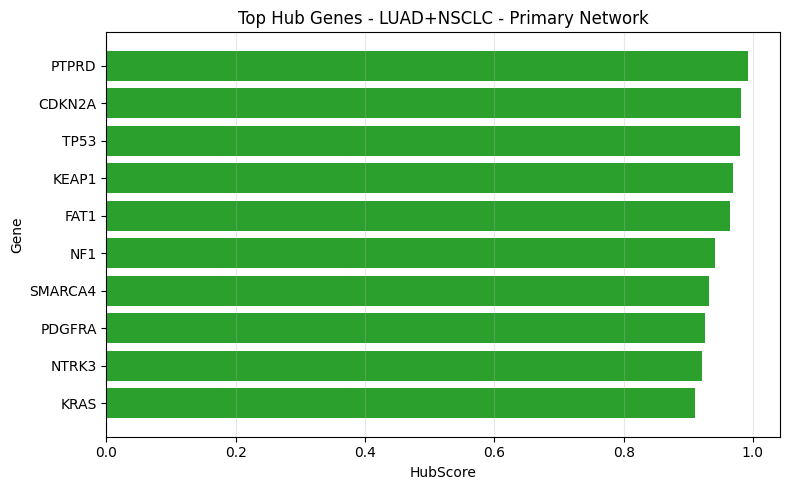

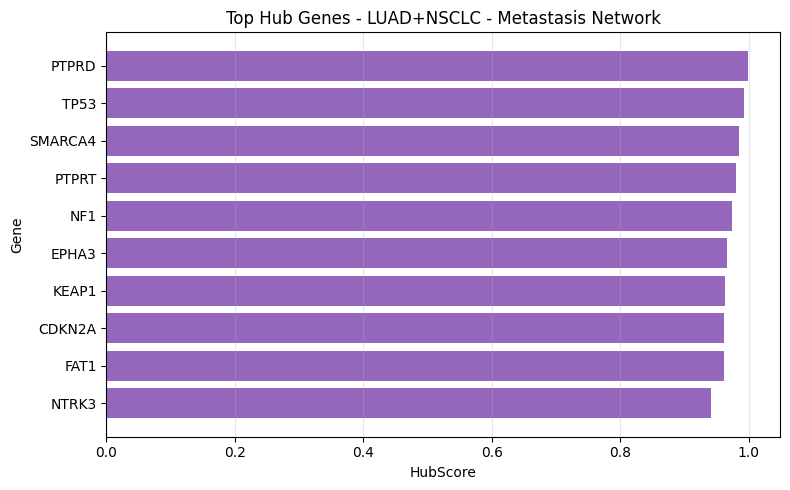

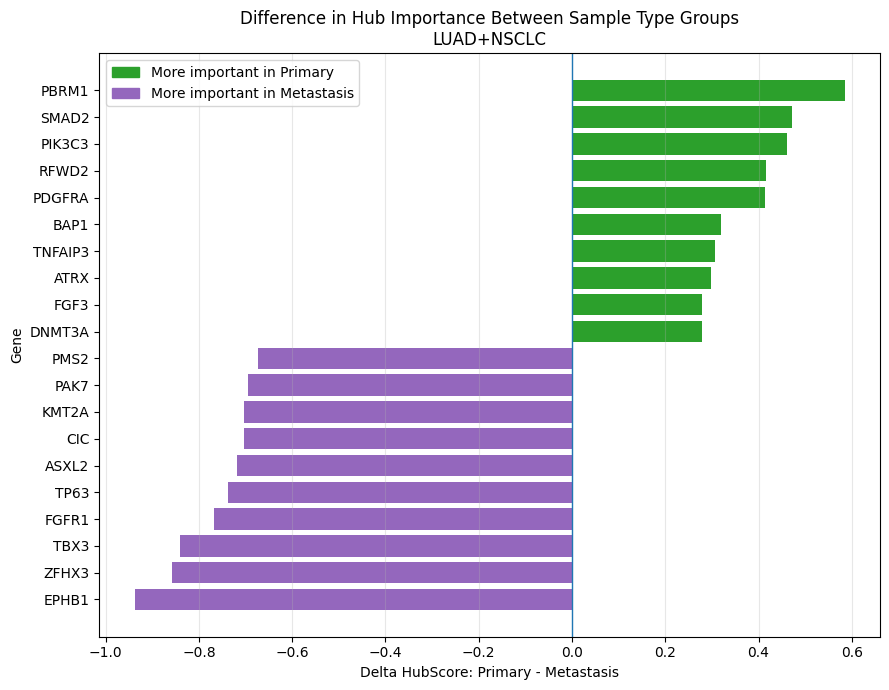


####################################################################################################
ONCOTREE GROUP: LUSC_NSCLC (LUSC+NSCLC)
####################################################################################################


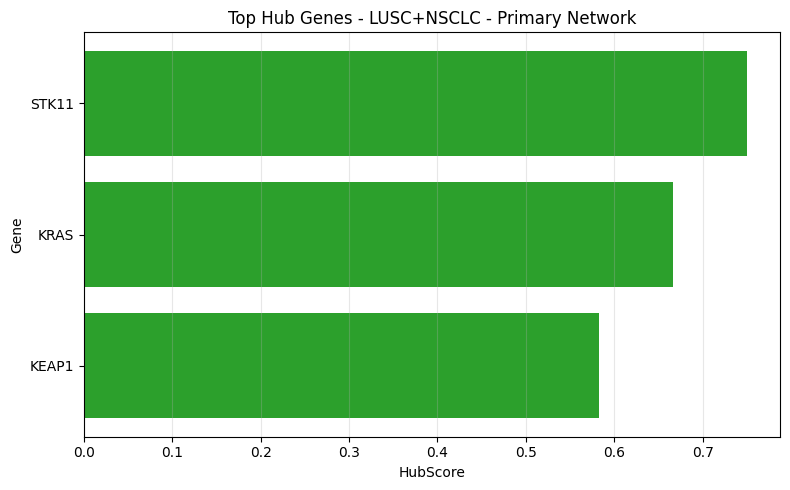

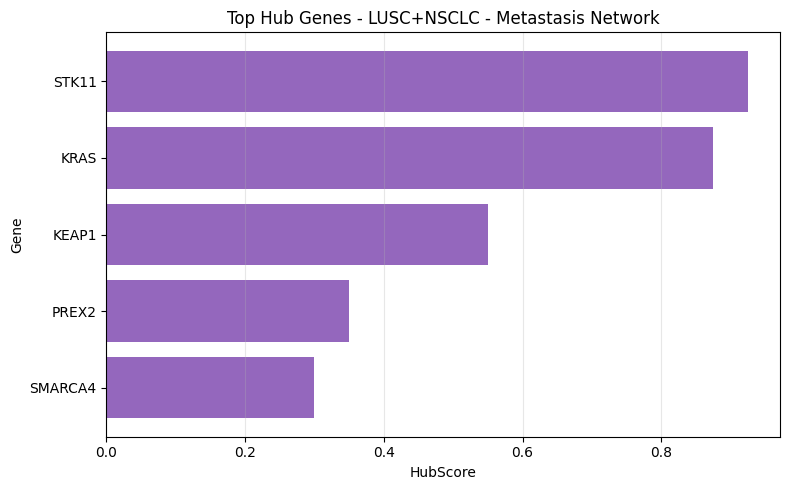

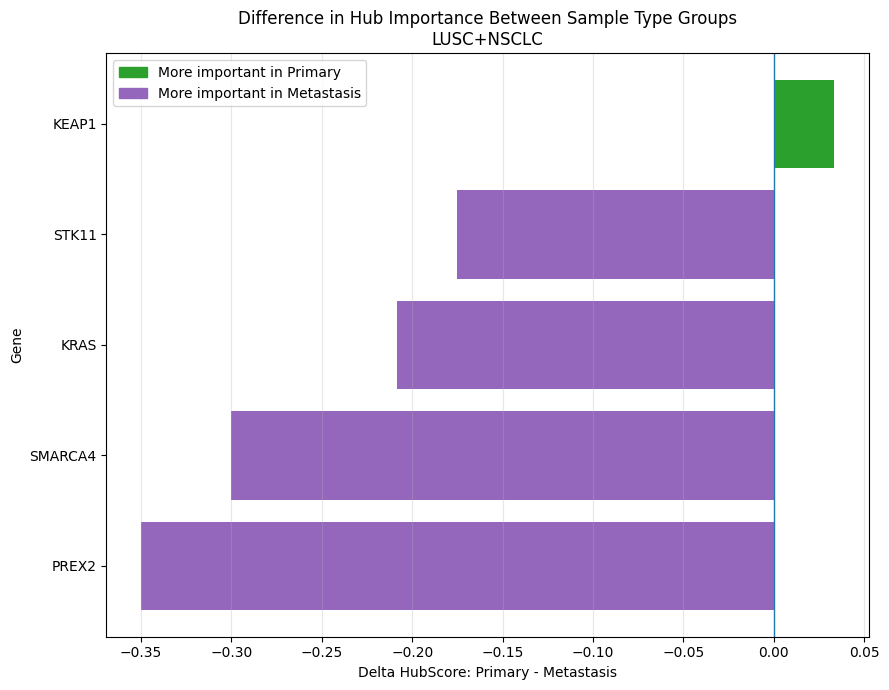

In [24]:
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import pandas as pd
import numpy as np

# ============================================================
# HUB PLOTS - ONCOTREE GROUPS ORIENTED
# Primary vs Metastasis networks
# LUAD_NSCLC = LUAD + NSCLC
# LUSC_NSCLC = LUSC + NSCLC
# ============================================================

# Compatibilità con i nomi creati nella cella precedente
if "hub_tables_by_oncotree_sample_type" not in globals():
    if "hub_tables_by_oncotree_group_sample_type" in globals():
        hub_tables_by_oncotree_sample_type = hub_tables_by_oncotree_group_sample_type
    else:
        raise ValueError(
            "hub_tables_by_oncotree_sample_type non disponibile. "
            "Esegui prima la cella hub analysis per sample_type_group e Oncotree Group."
        )

if "hub_comparison_all_oncotree" not in globals():
    if "hub_comparison_all_oncotree_sample_type" in globals():
        hub_comparison_all_oncotree = hub_comparison_all_oncotree_sample_type
    else:
        raise ValueError(
            "hub_comparison_all_oncotree non disponibile. "
            "Esegui prima la cella di confronto hub Primary vs Metastasis per Oncotree Group."
        )

top_n = 10

target_groups = ["LUAD_NSCLC", "LUSC_NSCLC"]

group_labels = {
    "LUAD_NSCLC": "LUAD+NSCLC",
    "LUSC_NSCLC": "LUSC+NSCLC",
}

# Gruppi Sample Type
PRIMARY_GROUP = "Primary"
METASTASIS_GROUP = "Metastasis"

# Colori Sample Type groups
PRIMARY_COLOR = "tab:green"       # Primary
METASTASIS_COLOR = "tab:purple"   # Metastasis

# Metti una lista se vuoi plottare solo un gruppo, esempio:
# oncotree_groups_to_plot = ["LUAD_NSCLC"]
oncotree_groups_to_plot = [
    group_name
    for group_name in target_groups
    if group_name in hub_tables_by_oncotree_sample_type
]


# ============================================================
# LOOP PER ONCOTREE GROUP
# ============================================================

for oncotree_group in oncotree_groups_to_plot:

    readable_group = group_labels.get(oncotree_group, oncotree_group)

    print("\n" + "#" * 100)
    print(f"ONCOTREE GROUP: {oncotree_group} ({readable_group})")
    print("#" * 100)

    group_tables = hub_tables_by_oncotree_sample_type.get(oncotree_group, {})

    hub_primary = group_tables.get(PRIMARY_GROUP, pd.DataFrame())
    hub_metastasis = group_tables.get(METASTASIS_GROUP, pd.DataFrame())

    # ------------------------------------------------------------
    # Recupero confronto Primary vs Metastasis
    # ------------------------------------------------------------

    if "Oncotree_Group" in hub_comparison_all_oncotree.columns:
        hub_comparison = hub_comparison_all_oncotree[
            hub_comparison_all_oncotree["Oncotree_Group"] == oncotree_group
            ].copy()

    elif "ONCOTREE_CODE" in hub_comparison_all_oncotree.columns:
        # fallback se hai mantenuto vecchio nome colonna
        hub_comparison = hub_comparison_all_oncotree[
            hub_comparison_all_oncotree["ONCOTREE_CODE"] == oncotree_group
            ].copy()

    else:
        raise ValueError(
            "hub_comparison_all_oncotree deve contenere 'Oncotree_Group' "
            "oppure 'ONCOTREE_CODE'."
        )

    # ========================================================
    # 1. Top hubs Primary
    # ========================================================

    if hub_primary is None or hub_primary.empty:
        print(f"[{oncotree_group}] Nessuna hub table Primary disponibile.")
    else:

        top_primary = (
            hub_primary
            .sort_values("HubScore", ascending=False)
            .head(top_n)
            .copy()
        )

        plt.figure(figsize=(8, 5))

        plt.barh(
            top_primary["Gene"][::-1],
            top_primary["HubScore"][::-1],
            color=PRIMARY_COLOR
        )

        plt.title(
            f"Top Hub Genes - {readable_group} - Primary Network"
        )
        plt.xlabel("HubScore")
        plt.ylabel("Gene")
        plt.grid(axis="x", alpha=0.3)
        plt.tight_layout()
        plt.show()

    # ========================================================
    # 2. Top hubs Metastasis
    # ========================================================

    if hub_metastasis is None or hub_metastasis.empty:
        print(f"[{oncotree_group}] Nessuna hub table Metastasis disponibile.")
    else:

        top_metastasis = (
            hub_metastasis
            .sort_values("HubScore", ascending=False)
            .head(top_n)
            .copy()
        )

        plt.figure(figsize=(8, 5))

        plt.barh(
            top_metastasis["Gene"][::-1],
            top_metastasis["HubScore"][::-1],
            color=METASTASIS_COLOR
        )

        plt.title(
            f"Top Hub Genes - {readable_group} - Metastasis Network"
        )
        plt.xlabel("HubScore")
        plt.ylabel("Gene")
        plt.grid(axis="x", alpha=0.3)
        plt.tight_layout()
        plt.show()

    # ========================================================
    # 3. Difference Primary vs Metastasis
    # ========================================================

    if hub_comparison is None or hub_comparison.empty:
        print(f"[{oncotree_group}] Nessun confronto Primary vs Metastasis disponibile.")
        continue

    if "Delta_HubScore_primary_minus_metastasis" not in hub_comparison.columns:
        print(
            f"[{oncotree_group}] Colonna Delta_HubScore_primary_minus_metastasis mancante. "
            "Controlla la cella precedente."
        )
        continue

    delta_primary = (
        hub_comparison
        .sort_values("Delta_HubScore_primary_minus_metastasis", ascending=False)
        .head(top_n)
        .copy()
    )

    delta_metastasis = (
        hub_comparison
        .sort_values("Delta_HubScore_primary_minus_metastasis", ascending=True)
        .head(top_n)
        .copy()
    )

    delta_plot = pd.concat(
        [delta_metastasis, delta_primary],
        axis=0
    ).drop_duplicates(
        subset=["Gene"]
    )

    delta_plot = delta_plot.sort_values(
        "Delta_HubScore_primary_minus_metastasis"
    )

    colors = [
        PRIMARY_COLOR if val > 0 else METASTASIS_COLOR
        for val in delta_plot["Delta_HubScore_primary_minus_metastasis"]
    ]

    plt.figure(figsize=(9, 7))

    plt.barh(
        delta_plot["Gene"],
        delta_plot["Delta_HubScore_primary_minus_metastasis"],
        color=colors
    )

    plt.axvline(0, linewidth=1)

    plt.title(
        f"Difference in Hub Importance Between Sample Type Groups\n"
        f"{readable_group}"
    )

    plt.xlabel("Delta HubScore: Primary - Metastasis")
    plt.ylabel("Gene")
    plt.grid(axis="x", alpha=0.3)

    primary_patch = mpatches.Patch(
        color=PRIMARY_COLOR,
        label="More important in Primary"
    )

    metastasis_patch = mpatches.Patch(
        color=METASTASIS_COLOR,
        label="More important in Metastasis"
    )

    plt.legend(handles=[primary_patch, metastasis_patch])

    plt.tight_layout()
    plt.show()

In [26]:
import pandas as pd
import numpy as np
from pathlib import Path

# ============================================================
# MAP SAMPLE TYPE HUB GENES TO LEIDEN CLUSTERS
# LUAD_NSCLC
#
# Obiettivo:
# - prendere i geni hub più rappresentativi di Primary vs Metastasis
# - vedere in quali cluster Leiden cadono
# - riassumere quali cluster sono più arricchiti/rappresentati
# ============================================================


# ============================================================
# 0. Paths and parameters
# ============================================================

data_dir = Path("data_lung")

oncotree_group = "LUAD_NSCLC"
included_codes = "LUAD+NSCLC"

clusters_path = (
    data_dir
    / "networks_by_oncotree_groups"
    / "final_leiden_clusters_with_hub_metrics"
    / f"leiden_clusters_with_hub_metrics_{oncotree_group}.csv"
)

hub_comparison_path = (
        data_dir
        / "clinical_to_network_by_oncotree_groups_sample_type"
        / "hub_analysis_by_oncotree_group_sample_type"
        / "hub_genes_primary_vs_metastasis_comparison_all_oncotree_groups.csv"
)

hub_all_path = (
        data_dir
        / "clinical_to_network_by_oncotree_groups_sample_type"
        / "hub_analysis_by_oncotree_group_sample_type"
        / "hub_genes_all_oncotree_group_sample_type_networks.csv"
)

output_dir = (
        data_dir
        / "clinical_to_network_by_oncotree_groups_sample_type"
        / "hub_genes_cluster_mapping"
)

output_dir.mkdir(parents=True, exist_ok=True)

# Numero di geni da prendere per ciascun gruppo
top_n = 20

# Se vuoi usare più geni, aumenta ad esempio a 30 o 50
# top_n = 30


# ============================================================
# 1. Helper functions
# ============================================================

def safe_display(df_obj):
    try:
        display(df_obj)
    except NameError:
        print(df_obj)


def clean_gene_name(x):
    if pd.isna(x):
        return np.nan
    return str(x).strip().upper()


def load_hub_comparison():
    """
    Carica la tabella di confronto Primary vs Metastasis.
    Prima prova a usare la variabile già in memoria.
    Se non esiste, carica il CSV salvato.
    """

    if "hub_comparison_all_oncotree_sample_type" in globals():
        print("Uso hub_comparison_all_oncotree_sample_type già presente in memoria.")
        return hub_comparison_all_oncotree_sample_type.copy()

    if "hub_comparison_all_oncotree" in globals():
        print("Uso hub_comparison_all_oncotree già presente in memoria.")
        return hub_comparison_all_oncotree.copy()

    if hub_comparison_path.exists():
        print("Carico hub comparison da CSV:")
        print(hub_comparison_path)
        return pd.read_csv(hub_comparison_path, low_memory=False)

    raise FileNotFoundError(
        "Non trovo la tabella di confronto Primary vs Metastasis. "
        "Esegui prima la cella hub analysis oppure controlla il path:\n"
        f"{hub_comparison_path}"
    )


def load_hub_all():
    """
    Carica la tabella con gli hub separati Primary e Metastasis.
    Prima prova a usare la variabile già in memoria.
    Se non esiste, carica il CSV salvato.
    """

    if "hub_all_oncotree_sample_type" in globals():
        print("Uso hub_all_oncotree_sample_type già presente in memoria.")
        return hub_all_oncotree_sample_type.copy()

    if hub_all_path.exists():
        print("Carico hub all da CSV:")
        print(hub_all_path)
        return pd.read_csv(hub_all_path, low_memory=False)

    print(
        "Tabella hub separata non trovata. "
        "Salto l'analisi alternativa sui top hub separati."
    )
    return None


def map_genes_to_clusters(gene_table, cluster_table):
    """
    Associa ogni gene alla sua informazione di cluster Leiden.
    """

    gene_table = gene_table.copy()
    cluster_table = cluster_table.copy()

    gene_table["Gene_clean"] = gene_table["Gene"].apply(clean_gene_name)
    cluster_table["Gene_clean"] = cluster_table["Gene"].apply(clean_gene_name)

    cluster_cols = [
        "Gene_clean",
        "Cluster",
        "Rank_in_cluster",
        "HubScore",
        "Degree",
        "Node Strength",
        "Betweenness",
        "Closeness"
    ]

    cluster_cols = [
        col for col in cluster_cols
        if col in cluster_table.columns
    ]

    cluster_gene_map = (
        cluster_table[cluster_cols]
        .drop_duplicates("Gene_clean")
        .copy()
    )

    mapped = gene_table.merge(
        cluster_gene_map,
        on="Gene_clean",
        how="left",
        suffixes=("", "_cluster")
    )

    mapped["Found_in_Leiden_clusters"] = mapped["Cluster"].notna()

    return mapped


def summarize_cluster_distribution(mapped_df, group_col):
    """
    Riassume quanti geni di ciascun gruppo cadono in ciascun cluster.
    """

    summary = (
        mapped_df
        .dropna(subset=["Cluster"])
        .groupby([group_col, "Cluster"])
        .agg(
            n_genes=("Gene", "nunique"),
            genes=("Gene", lambda x: ", ".join(sorted(x.dropna().astype(str).unique()))),
            mean_abs_delta=(
                "Abs_Delta_HubScore",
                "mean"
            ) if "Abs_Delta_HubScore" in mapped_df.columns else ("Gene", "size"),
            mean_cluster_rank=("Rank_in_cluster", "mean")
        )
        .reset_index()
    )

    totals = (
        mapped_df
        .dropna(subset=["Cluster"])
        .groupby(group_col)
        .agg(total_mapped_genes=("Gene", "nunique"))
        .reset_index()
    )

    summary = summary.merge(
        totals,
        on=group_col,
        how="left"
    )

    summary["percentage"] = (
            summary["n_genes"]
            / summary["total_mapped_genes"]
            * 100
    ).round(2)

    summary = summary.sort_values(
        [group_col, "n_genes", "percentage"],
        ascending=[True, False, False]
    ).reset_index(drop=True)

    return summary


# ============================================================
# 2. Load Leiden cluster table
# ============================================================

clusters = pd.read_csv(clusters_path, low_memory=False)

clusters = clusters.loc[:, ~clusters.columns.duplicated()].copy()

# Normalize column names from the final Leiden cluster file
clusters = clusters.rename(columns={
    "Hugo_Symbol": "Gene",
    "gene": "Gene",
    "GENE": "Gene",
    "cluster": "Cluster",
    "Leiden_cluster": "Cluster",
    "Leiden_Cluster": "Cluster",
    "leiden_cluster": "Cluster",
    "hubscore": "HubScore",
    "rank_in_cluster": "Rank_in_cluster",
    "Oncotree_Code": "Oncotree_Group",
    "ONCOTREE_CODE": "Oncotree_Group",
    "Oncotree Code": "Oncotree_Group"
})
clusters = clusters.loc[:, ~clusters.columns.duplicated()].copy()

required_cluster_cols = {
    "Gene",
    "Cluster"
}

missing_cluster_cols = required_cluster_cols - set(clusters.columns)

if missing_cluster_cols:
    raise ValueError(
        f"Colonne mancanti nel file Leiden clusters: {missing_cluster_cols}"
    )

clusters["Gene"] = clusters["Gene"].astype(str)
clusters["Gene_clean"] = clusters["Gene"].apply(clean_gene_name)

print("Loaded Leiden clusters:")
print(clusters_path)
print("Rows:", clusters.shape[0])
print("Genes:", clusters["Gene_clean"].nunique())
print("Clusters:", sorted(clusters["Cluster"].dropna().unique()))

print("\nCluster size summary:")
cluster_size_summary = (
    clusters
    .groupby("Cluster")
    .agg(
        n_genes=("Gene", "nunique"),
        top_cluster_genes=(
            "Gene",
            lambda x: ", ".join(x.dropna().astype(str).head(10))
        )
    )
    .reset_index()
    .sort_values("n_genes", ascending=False)
)

safe_display(cluster_size_summary)


# ============================================================
# 3. ANALISI PRINCIPALE:
#    uso i geni differenziali Primary vs Metastasis
# ============================================================

hub_comparison = load_hub_comparison()
hub_comparison = hub_comparison.loc[:, ~hub_comparison.columns.duplicated()].copy()

# Normalizzo eventuale nome gruppo
if "Oncotree_Group" not in hub_comparison.columns:
    if "ONCOTREE_CODE" in hub_comparison.columns:
        hub_comparison = hub_comparison.rename(
            columns={"ONCOTREE_CODE": "Oncotree_Group"}
        )
    else:
        raise ValueError(
            "La tabella hub_comparison deve contenere Oncotree_Group oppure ONCOTREE_CODE."
        )

required_comparison_cols = {
    "Oncotree_Group",
    "Gene",
    "Delta_HubScore_primary_minus_metastasis"
}

missing_comparison_cols = required_comparison_cols - set(hub_comparison.columns)

if missing_comparison_cols:
    raise ValueError(
        f"Colonne mancanti nella tabella di confronto hub: {missing_comparison_cols}"
    )

hub_comparison = hub_comparison[
    hub_comparison["Oncotree_Group"].astype(str) == oncotree_group
    ].copy()

hub_comparison["Gene"] = hub_comparison["Gene"].astype(str)

hub_comparison["Delta_HubScore_primary_minus_metastasis"] = pd.to_numeric(
    hub_comparison["Delta_HubScore_primary_minus_metastasis"],
    errors="coerce"
)

hub_comparison = hub_comparison.dropna(
    subset=["Gene", "Delta_HubScore_primary_minus_metastasis"]
).copy()

# Geni più rappresentativi della rete Primary
primary_genes = (
    hub_comparison
    .sort_values("Delta_HubScore_primary_minus_metastasis", ascending=False)
    .head(top_n)
    .copy()
)

primary_genes["Signature_Group"] = "Primary-enriched hub genes"

# Geni più rappresentativi della rete Metastasis
metastasis_genes = (
    hub_comparison
    .sort_values("Delta_HubScore_primary_minus_metastasis", ascending=True)
    .head(top_n)
    .copy()
)

metastasis_genes["Signature_Group"] = "Metastasis-enriched hub genes"

differential_genes = pd.concat(
    [primary_genes, metastasis_genes],
    ignore_index=True
)

differential_genes["Abs_Delta_HubScore"] = (
    differential_genes["Delta_HubScore_primary_minus_metastasis"]
    .abs()
)

differential_mapped = map_genes_to_clusters(
    gene_table=differential_genes,
    cluster_table=clusters
)

print("\n" + "=" * 100)
print("DIFFERENTIAL HUB GENES MAPPED TO LEIDEN CLUSTERS")
print("=" * 100)

cols_to_show = [
    "Signature_Group",
    "Gene",
    "Delta_HubScore_primary_minus_metastasis",
    "Abs_Delta_HubScore",
    "HubScore_primary",
    "HubScore_metastasis",
    "Degree_primary",
    "Degree_metastasis",
    "Cluster",
    "Rank_in_cluster",
    "HubScore_cluster",
    "Degree",
    "Node Strength",
    "Found_in_Leiden_clusters"
]

cols_to_show = [
    col for col in cols_to_show
    if col in differential_mapped.columns
]

safe_display(
    differential_mapped[cols_to_show]
    .sort_values(
        ["Signature_Group", "Abs_Delta_HubScore"],
        ascending=[True, False]
    )
)

differential_cluster_summary = summarize_cluster_distribution(
    mapped_df=differential_mapped,
    group_col="Signature_Group"
)

print("\n" + "=" * 100)
print("CLUSTER DISTRIBUTION OF DIFFERENTIAL HUB GENES")
print("=" * 100)

safe_display(differential_cluster_summary)


# ============================================================
# 4. Dominant cluster per gruppo differenziale
# ============================================================

dominant_clusters = (
    differential_cluster_summary
    .sort_values(
        ["Signature_Group", "n_genes", "percentage"],
        ascending=[True, False, False]
    )
    .groupby("Signature_Group")
    .head(1)
    .reset_index(drop=True)
)

print("\n" + "=" * 100)
print("DOMINANT LEIDEN CLUSTER FOR EACH DIFFERENTIAL HUB SIGNATURE")
print("=" * 100)

safe_display(dominant_clusters)


# ============================================================
# 5. ANALISI ALTERNATIVA:
#    uso le top hub list separate Primary e Metastasis
# ============================================================

hub_all = load_hub_all()

if hub_all is not None:

    hub_all = hub_all.loc[:, ~hub_all.columns.duplicated()].copy()

    required_hub_all_cols = {
        "Oncotree_Group",
        "sample_type_group",
        "Gene",
        "HubScore"
    }

    missing_hub_all_cols = required_hub_all_cols - set(hub_all.columns)

    if missing_hub_all_cols:
        print(
            "Colonne mancanti nella tabella hub separata. "
            f"Salto analisi alternativa. Mancano: {missing_hub_all_cols}"
        )

        separate_mapped = pd.DataFrame()
        separate_cluster_summary = pd.DataFrame()

    else:
        hub_all = hub_all[
            hub_all["Oncotree_Group"].astype(str) == oncotree_group
            ].copy()

        hub_all["Gene"] = hub_all["Gene"].astype(str)
        hub_all["HubScore"] = pd.to_numeric(
            hub_all["HubScore"],
            errors="coerce"
        )

        primary_top_hubs = (
            hub_all[
                hub_all["sample_type_group"].astype(str) == "Primary"
                ]
            .sort_values("HubScore", ascending=False)
            .head(top_n)
            .copy()
        )

        primary_top_hubs["Hub_List_Group"] = "Top Primary hub genes"

        metastasis_top_hubs = (
            hub_all[
                hub_all["sample_type_group"].astype(str) == "Metastasis"
                ]
            .sort_values("HubScore", ascending=False)
            .head(top_n)
            .copy()
        )

        metastasis_top_hubs["Hub_List_Group"] = "Top Metastasis hub genes"

        separate_top_hubs = pd.concat(
            [primary_top_hubs, metastasis_top_hubs],
            ignore_index=True
        )

        separate_mapped = map_genes_to_clusters(
            gene_table=separate_top_hubs,
            cluster_table=clusters
        )

        print("\n" + "=" * 100)
        print("SEPARATE TOP HUB LISTS MAPPED TO LEIDEN CLUSTERS")
        print("=" * 100)

        cols_to_show_sep = [
            "Hub_List_Group",
            "sample_type_group",
            "Gene",
            "HubScore",
            "Degree",
            "Node_Strength",
            "Betweenness",
            "Closeness",
            "Cluster",
            "Rank_in_cluster",
            "HubScore_cluster",
            "Found_in_Leiden_clusters"
        ]

        cols_to_show_sep = [
            col for col in cols_to_show_sep
            if col in separate_mapped.columns
        ]

        safe_display(
            separate_mapped[cols_to_show_sep]
            .sort_values(["Hub_List_Group", "HubScore"], ascending=[True, False])
        )

        separate_cluster_summary = (
            separate_mapped
            .dropna(subset=["Cluster"])
            .groupby(["Hub_List_Group", "Cluster"])
            .agg(
                n_genes=("Gene", "nunique"),
                genes=("Gene", lambda x: ", ".join(sorted(x.dropna().astype(str).unique()))),
                mean_hubscore=("HubScore", "mean"),
                mean_cluster_rank=("Rank_in_cluster", "mean")
            )
            .reset_index()
        )

        separate_totals = (
            separate_mapped
            .dropna(subset=["Cluster"])
            .groupby("Hub_List_Group")
            .agg(total_mapped_genes=("Gene", "nunique"))
            .reset_index()
        )

        separate_cluster_summary = separate_cluster_summary.merge(
            separate_totals,
            on="Hub_List_Group",
            how="left"
        )

        separate_cluster_summary["percentage"] = (
                separate_cluster_summary["n_genes"]
                / separate_cluster_summary["total_mapped_genes"]
                * 100
        ).round(2)

        separate_cluster_summary = separate_cluster_summary.sort_values(
            ["Hub_List_Group", "n_genes", "percentage"],
            ascending=[True, False, False]
        ).reset_index(drop=True)

        print("\n" + "=" * 100)
        print("CLUSTER DISTRIBUTION OF SEPARATE TOP HUB LISTS")
        print("=" * 100)

        safe_display(separate_cluster_summary)

else:
    separate_mapped = pd.DataFrame()
    separate_cluster_summary = pd.DataFrame()


# ============================================================
# 6. Save outputs
# ============================================================

differential_mapped_file = (
        output_dir
        / f"{oncotree_group}_differential_primary_vs_metastasis_hub_genes_mapped_to_leiden_clusters.csv"
)

differential_summary_file = (
        output_dir
        / f"{oncotree_group}_differential_primary_vs_metastasis_cluster_distribution.csv"
)

dominant_clusters_file = (
        output_dir
        / f"{oncotree_group}_dominant_clusters_for_differential_hub_signatures.csv"
)

differential_mapped.to_csv(
    differential_mapped_file,
    index=False
)

differential_cluster_summary.to_csv(
    differential_summary_file,
    index=False
)

dominant_clusters.to_csv(
    dominant_clusters_file,
    index=False
)

print("\nSaved differential mapped table:")
print(differential_mapped_file)

print("\nSaved differential cluster summary:")
print(differential_summary_file)

print("\nSaved dominant clusters table:")
print(dominant_clusters_file)

if not separate_mapped.empty:

    separate_mapped_file = (
            output_dir
            / f"{oncotree_group}_separate_primary_metastasis_top_hub_genes_mapped_to_leiden_clusters.csv"
    )

    separate_summary_file = (
            output_dir
            / f"{oncotree_group}_separate_primary_metastasis_top_hub_cluster_distribution.csv"
    )

    separate_mapped.to_csv(
        separate_mapped_file,
        index=False
    )

    separate_cluster_summary.to_csv(
        separate_summary_file,
        index=False
    )

    print("\nSaved separate top hub mapped table:")
    print(separate_mapped_file)

    print("\nSaved separate top hub cluster summary:")
    print(separate_summary_file)


# ============================================================
# 7. Final interpretation helper
# ============================================================

print("\n" + "=" * 100)
print("INTERPRETATION GUIDE")
print("=" * 100)

print(
    "1. Usa soprattutto la tabella 'differential_cluster_summary' per il report.\n"
    "   Questa indica in quali cluster cadono maggiormente i geni più specifici\n"
    "   della rete Primary o Metastasis.\n"
)

print(
    "2. Delta_HubScore_primary_minus_metastasis > 0 significa che il gene è più hub\n"
    "   nella rete Primary rispetto alla rete Metastasis.\n"
)

print(
    "3. Delta_HubScore_primary_minus_metastasis < 0 significa che il gene è più hub\n"
    "   nella rete Metastasis rispetto alla rete Primary.\n"
)

print(
    "4. La tabella 'dominant_clusters' ti dà direttamente il cluster principale\n"
    "   per ciascuna signature differenziale.\n"
)

print(
    "5. L'analisi alternativa con le top hub list separate è utile come controllo,\n"
    "   ma è meno specifica perché un gene può essere molto hub in entrambi i gruppi.\n"
)

Loaded Leiden clusters:
data_lung\networks_by_oncotree_groups\leiden_clusters_by_oncotree_groups\leiden_clusters_LUAD_NSCLC.csv
Rows: 359
Genes: 359
Clusters: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10]

Cluster size summary:


,Cluster,n_genes,top_cluster_genes
0,0,93,"PTPRT, PTPRD, NTRK3, EPHA3, ERBB4, GRIN2A, EPH..."
1,1,49,"SMARCA4, KEAP1, PIK3C2G, STK11, KRAS, ATRX, ET..."
2,2,48,"FAT1, NF1, HGF, MGA, PIK3CG, ATM, RBM10, ARID1..."
3,3,44,"SDHA, TERT, KMT2B, CARD11, DROSHA, IL7R, EP300..."
4,4,39,"CDKN2A, CDKN2Ap16INK4A, CDKN2Ap14ARF, CDKN2B, ..."
5,5,23,"PREX2, FGFR1, RECQL4, MYC, SOX17, AGO2, NBN, R..."
6,6,23,"FGF3, NFKBIA, FOXA1, NKX2-1, CCND1, FGF4, FGF1..."
7,7,15,"NTRK1, DDR2, MCL1, RB1, RIT1, SDHC, SETDB1, HI..."
8,8,15,"TP53, BRD4, CTCF, FGFR3, GAB1, MITF, SPOP, HLA..."
9,9,7,"ALK, CREBBP, TSC2, SLX4, EML4, PPP2R1A, TRAF7"


Uso hub_comparison_all_oncotree_sample_type già presente in memoria.

DIFFERENTIAL HUB GENES MAPPED TO LEIDEN CLUSTERS


,Signature_Group,Gene,Delta_HubScore_primary_minus_metastasis,Abs_Delta_HubScore,HubScore_primary,HubScore_metastasis,Degree_primary,Degree_metastasis,Cluster,Rank_in_cluster,Degree,Node Strength,Found_in_Leiden_clusters
20,Metastasis-enriched hub genes,EPHB1,-0.937796,0.937796,NaN,0.937796,NaN,32.0,0.0,9.0,53.0,116.512812,True
21,Metastasis-enriched hub genes,ZFHX3,-0.858412,0.858412,NaN,0.858412,NaN,19.0,0.0,14.0,45.0,90.721541,True
22,Metastasis-enriched hub genes,TBX3,-0.840640,0.840640,NaN,0.840640,NaN,13.0,0.0,16.0,37.0,74.693339,True
23,Metastasis-enriched hub genes,FGFR1,-0.767773,0.767773,NaN,0.767773,NaN,9.0,5.0,2.0,38.0,98.756167,True
24,Metastasis-enriched hub genes,TP63,-0.738152,0.738152,NaN,0.738152,NaN,9.0,0.0,36.0,21.0,44.831448,True
25,Metastasis-enriched hub genes,ASXL2,-0.717417,0.717417,NaN,0.717417,NaN,9.0,2.0,12.0,19.0,40.166626,True
26,Metastasis-enriched hub genes,CIC,-0.704384,0.704384,NaN,0.704384,NaN,11.0,0.0,46.0,20.0,43.486154,True
27,Metastasis-enriched hub genes,KMT2A,-0.703199,0.703199,NaN,0.703199,NaN,7.0,0.0,33.0,26.0,52.490209,True
28,Metastasis-enriched hub genes,PAK7,-0.694235,0.694235,0.193798,0.888033,1.0,19.0,0.0,17.0,30.0,61.980970,True
29,Metastasis-enriched hub genes,PMS2,-0.672986,0.672986,NaN,0.672986,NaN,8.0,3.0,15.0,12.0,42.477294,True



CLUSTER DISTRIBUTION OF DIFFERENTIAL HUB GENES


,Signature_Group,Cluster,n_genes,genes,mean_abs_delta,mean_cluster_rank,total_mapped_genes,percentage
0,Metastasis-enriched hub genes,0.0,12,"AMER1, ATR, CIC, DICER1, EPHB1, KIT, KMT2A, NO...",0.718299,26.916667,20,60.00
1,Metastasis-enriched hub genes,3.0,4,"AKT2, APC, PMS2, RAC1",0.622334,17.500000,20,20.00
2,Metastasis-enriched hub genes,2.0,2,"ASXL2, WT1",0.693720,11.000000,20,10.00
3,Metastasis-enriched hub genes,4.0,1,JAK2,0.567536,6.000000,20,5.00
4,Metastasis-enriched hub genes,5.0,1,FGFR1,0.767773,2.000000,20,5.00
5,Primary-enriched hub genes,0.0,7,"ANKRD11, CSDE1, DNMT3A, PBRM1, PDGFRA, RFWD2, ...",0.358603,59.285714,19,36.84
6,Primary-enriched hub genes,2.0,3,"PHOX2B, PIK3C3, YAP1",0.317829,29.333333,19,15.79
7,Primary-enriched hub genes,4.0,2,"SMAD2, SOX2",0.356589,21.500000,19,10.53
8,Primary-enriched hub genes,6.0,2,"FGF3, FGF4",0.266289,3.500000,19,10.53
9,Primary-enriched hub genes,9.0,2,"ALK, PPP2R1A",0.238797,3.500000,19,10.53


... (3 outputs left out)

,Hub_List_Group,sample_type_group,Gene,HubScore,Degree,Node_Strength,Betweenness,Closeness,Cluster,Rank_in_cluster,HubScore_cluster,Found_in_Leiden_clusters
20,Top Metastasis hub genes,Metastasis,PTPRD,0.998815,51,105.365329,0.172978,0.513447,0,2,0.996518,True
21,Top Metastasis hub genes,Metastasis,TP53,0.992299,50,102.611245,0.252449,0.478360,8,1,0.976323,True
22,Top Metastasis hub genes,Metastasis,SMARCA4,0.984597,39,71.195933,0.129779,0.490654,1,1,0.988858,True
23,Top Metastasis hub genes,Metastasis,PTPRT,0.979858,47,98.905071,0.059604,0.483871,0,1,0.999304,True
24,Top Metastasis hub genes,Metastasis,NF1,0.974526,37,66.996506,0.144270,0.472973,2,2,0.968663,True
25,Top Metastasis hub genes,Metastasis,EPHA3,0.966825,33,70.938698,0.050854,0.489510,0,4,0.981198,True
26,Top Metastasis hub genes,Metastasis,KEAP1,0.963270,36,63.588984,0.119025,0.454545,1,2,0.972841,True
27,Top Metastasis hub genes,Metastasis,CDKN2A,0.961493,32,86.090659,0.110595,0.447761,4,1,0.933148,True
28,Top Metastasis hub genes,Metastasis,FAT1,0.961493,35,77.867333,0.028025,0.478360,2,1,0.990599,True
29,Top Metastasis hub genes,Metastasis,NTRK3,0.941351,34,77.539856,0.011255,0.472973,0,3,0.985724,True



CLUSTER DISTRIBUTION OF SEPARATE TOP HUB LISTS


,Hub_List_Group,Cluster,n_genes,genes,mean_hubscore,mean_cluster_rank,total_mapped_genes,percentage
0,Top Metastasis hub genes,0,8,"EPHA3, EPHA5, EPHB1, GRIN2A, NTRK3, PAK7, PTPR...",0.942536,6.500000,20,40.0
1,Top Metastasis hub genes,1,3,"KEAP1, KRAS, SMARCA4",0.954384,2.666667,20,15.0
2,Top Metastasis hub genes,2,3,"FAT1, NF1, RBM10",0.955371,3.333333,20,15.0
3,Top Metastasis hub genes,4,2,"CDKN2A, CDKN2B",0.929206,2.500000,20,10.0
4,Top Metastasis hub genes,3,1,TERT,0.918246,2.000000,20,5.0
5,Top Metastasis hub genes,6,1,FOXA1,0.925948,3.000000,20,5.0
6,Top Metastasis hub genes,7,1,NTRK1,0.909953,1.000000,20,5.0
7,Top Metastasis hub genes,8,1,TP53,0.992299,1.000000,20,5.0
8,Top Primary hub genes,0,7,"EPHA3, EPHA5, GRIN2A, NTRK3, PDGFRA, PTPRD, PTPRT",0.882890,5.571429,20,35.0
9,Top Primary hub genes,2,4,"ATM, FAT1, HGF, NF1",0.907703,3.000000,20,20.0



Saved differential mapped table:
data_lung\clinical_to_network_by_oncotree_groups_sample_type\hub_genes_cluster_mapping\LUAD_NSCLC_differential_primary_vs_metastasis_hub_genes_mapped_to_leiden_clusters.csv

Saved differential cluster summary:
data_lung\clinical_to_network_by_oncotree_groups_sample_type\hub_genes_cluster_mapping\LUAD_NSCLC_differential_primary_vs_metastasis_cluster_distribution.csv

Saved dominant clusters table:
data_lung\clinical_to_network_by_oncotree_groups_sample_type\hub_genes_cluster_mapping\LUAD_NSCLC_dominant_clusters_for_differential_hub_signatures.csv

Saved separate top hub mapped table:
data_lung\clinical_to_network_by_oncotree_groups_sample_type\hub_genes_cluster_mapping\LUAD_NSCLC_separate_primary_metastasis_top_hub_genes_mapped_to_leiden_clusters.csv

Saved separate top hub cluster summary:
data_lung\clinical_to_network_by_oncotree_groups_sample_type\hub_genes_cluster_mapping\LUAD_NSCLC_separate_primary_metastasis_top_hub_cluster_distribution.csv

INTER


HUB COUNTS BY CLUSTER - DIFFERENTIAL HUB LIST


,Cluster,cluster_size_genes,Primary_n_hubs,Primary_pct_of_group_hubs,Metastasis_n_hubs,Metastasis_pct_of_group_hubs,Delta_n_hubs_Primary_minus_Metastasis,Delta_pct_group_Primary_minus_Metastasis,Primary_genes,Metastasis_genes
0,0,93,7,36.84,12,60.0,-5,-23.16,"ANKRD11, CSDE1, DNMT3A, PBRM1, PDGFRA, RFWD2, TNFAIP3","AMER1, ATR, CIC, DICER1, EPHB1, KIT, KMT2A, NOTCH2, PAK7, TBX3, TP63, ZFHX3"
1,1,49,1,5.26,0,0.0,1,5.26,ATRX,-
2,2,48,3,15.79,2,10.0,1,5.79,"PHOX2B, PIK3C3, YAP1","ASXL2, WT1"
3,3,44,1,5.26,4,20.0,-3,-14.74,BAP1,"AKT2, APC, PMS2, RAC1"
4,4,39,2,10.53,1,5.0,1,5.53,"SMAD2, SOX2",JAK2
5,5,23,1,5.26,1,5.0,0,0.26,NKX3-1,FGFR1
6,6,23,2,10.53,0,0.0,2,10.53,"FGF3, FGF4",-
7,7,15,0,0.00,0,0.0,0,0.00,-,-
8,8,15,0,0.00,0,0.0,0,0.00,-,-
9,9,7,2,10.53,0,0.0,2,10.53,"ALK, PPP2R1A",-



FOCUS ON PROGNOSTIC CLUSTERS 1 AND 3


,Cluster,cluster_size_genes,Primary_n_hubs,Primary_pct_of_group_hubs,Metastasis_n_hubs,Metastasis_pct_of_group_hubs,Delta_n_hubs_Primary_minus_Metastasis,Delta_pct_group_Primary_minus_Metastasis,Primary_genes,Metastasis_genes
1,1,49,1,5.26,0,0.0,1,5.26,ATRX,-
3,3,44,1,5.26,4,20.0,-3,-14.74,BAP1,"AKT2, APC, PMS2, RAC1"


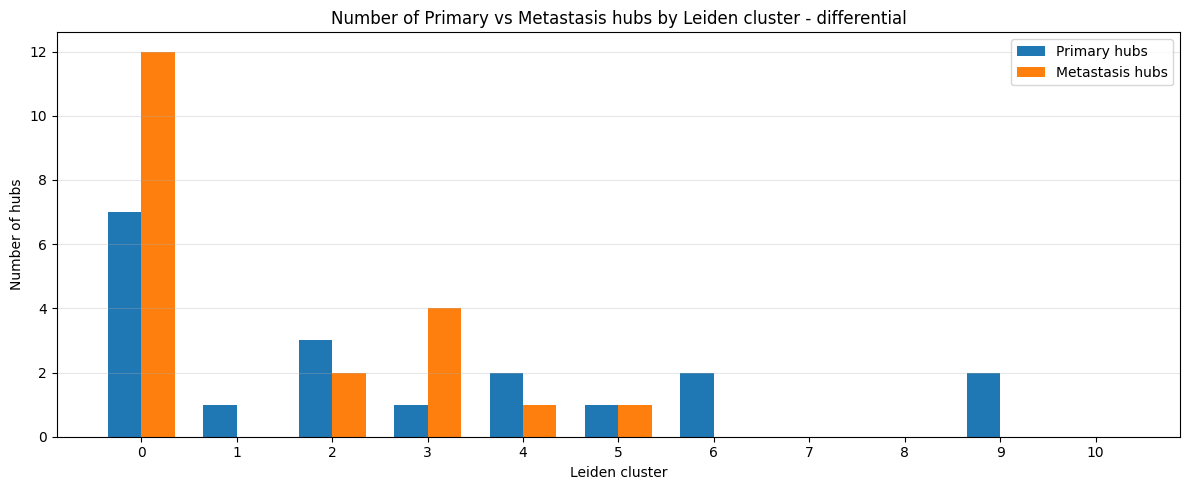

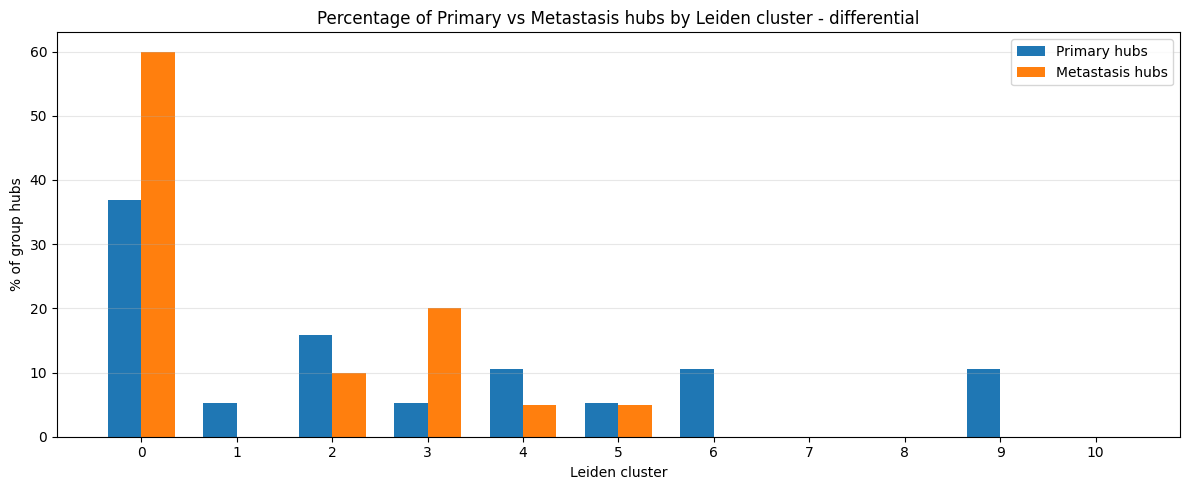


Saved long table:
data_lung\clinical_to_network_by_oncotree_groups_sample_type\hub_genes_cluster_mapping\readable_hub_counts_by_cluster\LUAD_NSCLC_differential_hub_counts_by_cluster_long.csv

Saved wide readable table:
data_lung\clinical_to_network_by_oncotree_groups_sample_type\hub_genes_cluster_mapping\readable_hub_counts_by_cluster\LUAD_NSCLC_differential_hub_counts_by_cluster_wide.csv

Saved focus table for clusters 1 and 3:
data_lung\clinical_to_network_by_oncotree_groups_sample_type\hub_genes_cluster_mapping\readable_hub_counts_by_cluster\LUAD_NSCLC_differential_hub_counts_clusters_1_3.csv


In [28]:
import pandas as pd
import numpy as np
from pathlib import Path
import matplotlib.pyplot as plt

# ============================================================
# HUB COUNTS AND PERCENTAGES BY LEIDEN CLUSTER
# Primary vs Metastasis
# LUAD_NSCLC
# ============================================================

data_dir = Path("data_lung")

oncotree_group = "LUAD_NSCLC"

# Scegli quale analisi usare:
# "differential" = geni più rappresentativi Primary vs Metastasis
# "separate" = top hub genes presi separatamente da Primary e Metastasis
ANALYSIS_MODE = "differential"
# ANALYSIS_MODE = "separate"

clusters_path = (
    data_dir
    / "networks_by_oncotree_groups"
    / "final_leiden_clusters_with_hub_metrics"
    / f"leiden_clusters_with_hub_metrics_{oncotree_group}.csv"
)

if ANALYSIS_MODE == "differential":
    mapped_path = (
            data_dir
            / "clinical_to_network_by_oncotree_groups_sample_type"
            / "hub_genes_cluster_mapping"
            / "LUAD_NSCLC_differential_primary_vs_metastasis_hub_genes_mapped_to_leiden_clusters.csv"
    )

elif ANALYSIS_MODE == "separate":
    mapped_path = (
            data_dir
            / "clinical_to_network_by_oncotree_groups_sample_type"
            / "hub_genes_cluster_mapping"
            / "LUAD_NSCLC_separate_primary_metastasis_top_hub_genes_mapped_to_leiden_clusters.csv"
    )

else:
    raise ValueError("ANALYSIS_MODE deve essere 'differential' oppure 'separate'.")

output_dir = (
        data_dir
        / "clinical_to_network_by_oncotree_groups_sample_type"
        / "hub_genes_cluster_mapping"
        / "readable_hub_counts_by_cluster"
)

output_dir.mkdir(parents=True, exist_ok=True)


# ============================================================
# 1. Load files
# ============================================================

clusters = pd.read_csv(clusters_path, low_memory=False)
mapped = pd.read_csv(mapped_path, low_memory=False)

clusters = clusters.loc[:, ~clusters.columns.duplicated()].copy()

# Normalize column names from the final Leiden cluster file
clusters = clusters.rename(columns={
    "Hugo_Symbol": "Gene",
    "gene": "Gene",
    "GENE": "Gene",
    "cluster": "Cluster",
    "Leiden_cluster": "Cluster",
    "Leiden_Cluster": "Cluster",
    "leiden_cluster": "Cluster",
    "hubscore": "HubScore",
    "rank_in_cluster": "Rank_in_cluster",
    "Oncotree_Code": "Oncotree_Group",
    "ONCOTREE_CODE": "Oncotree_Group",
    "Oncotree Code": "Oncotree_Group"
})
clusters = clusters.loc[:, ~clusters.columns.duplicated()].copy()
mapped = mapped.loc[:, ~mapped.columns.duplicated()].copy()

clusters["Cluster"] = pd.to_numeric(clusters["Cluster"], errors="coerce")
mapped["Cluster"] = pd.to_numeric(mapped["Cluster"], errors="coerce")

clusters["Gene"] = clusters["Gene"].astype(str)
mapped["Gene"] = mapped["Gene"].astype(str)


# ============================================================
# 2. Identify hub group: Primary or Metastasis
# ============================================================

def infer_hub_group(row):
    """
    Ricava se il gene appartiene al gruppo Primary o Metastasis.
    Funziona sia per:
    - differential mapped table
    - separate top hub mapped table
    """

    text_parts = []

    for col in ["Signature_Group", "Hub_List_Group", "sample_type_group"]:
        if col in row.index:
            text_parts.append(str(row[col]))

    text = " ".join(text_parts).lower()

    if "primary" in text:
        return "Primary"

    if "metastasis" in text:
        return "Metastasis"

    return np.nan


mapped["Hub_Group"] = mapped.apply(infer_hub_group, axis=1)

mapped = mapped.dropna(
    subset=["Gene", "Hub_Group"]
).copy()

# Tengo solo geni che sono stati effettivamente trovati nei cluster Leiden
mapped_in_clusters = mapped.dropna(subset=["Cluster"]).copy()

mapped_in_clusters["Cluster"] = mapped_in_clusters["Cluster"].astype(int)


# ============================================================
# 3. Cluster size
# ============================================================

cluster_sizes = (
    clusters
    .dropna(subset=["Cluster"])
    .assign(Cluster=lambda x: x["Cluster"].astype(int))
    .groupby("Cluster")
    .agg(
        cluster_size_genes=("Gene", "nunique")
    )
    .reset_index()
)


# ============================================================
# 4. Count hubs by group and cluster
# ============================================================

# Totale hub per gruppo, considerando solo quelli mappati nei cluster
total_hubs_by_group = (
    mapped_in_clusters
    .groupby("Hub_Group")
    .agg(
        total_hubs_group=("Gene", "nunique")
    )
    .reset_index()
)

hub_counts_long = (
    mapped_in_clusters
    .groupby(["Hub_Group", "Cluster"])
    .agg(
        n_hubs=("Gene", "nunique"),
        genes=("Gene", lambda x: ", ".join(sorted(x.dropna().astype(str).unique())))
    )
    .reset_index()
)

hub_counts_long = hub_counts_long.merge(
    total_hubs_by_group,
    on="Hub_Group",
    how="left"
)

hub_counts_long = hub_counts_long.merge(
    cluster_sizes,
    on="Cluster",
    how="left"
)

# Percentuale rispetto al totale degli hub del gruppo
# Esempio: quanti hub Primary cadono nel cluster 1 rispetto a tutti gli hub Primary?
hub_counts_long["pct_of_group_hubs"] = (
        hub_counts_long["n_hubs"]
        / hub_counts_long["total_hubs_group"]
        * 100
).round(2)

# Percentuale rispetto alla dimensione del cluster
# Esempio: quanti geni del cluster 1 sono hub Primary?
hub_counts_long["pct_of_cluster_genes"] = (
        hub_counts_long["n_hubs"]
        / hub_counts_long["cluster_size_genes"]
        * 100
).round(2)

hub_counts_long = hub_counts_long.sort_values(
    ["Cluster", "Hub_Group"]
).reset_index(drop=True)


# ============================================================
# 5. Wide table: easier to read Primary vs Metastasis
# ============================================================

all_clusters = sorted(clusters["Cluster"].dropna().astype(int).unique())

all_combinations = pd.MultiIndex.from_product(
    [["Primary", "Metastasis"], all_clusters],
    names=["Hub_Group", "Cluster"]
).to_frame(index=False)

hub_counts_complete = all_combinations.merge(
    hub_counts_long,
    on=["Hub_Group", "Cluster"],
    how="left"
)

hub_counts_complete = hub_counts_complete.merge(
    cluster_sizes,
    on="Cluster",
    how="left",
    suffixes=("", "_from_clusters")
)

hub_counts_complete["cluster_size_genes"] = (
    hub_counts_complete["cluster_size_genes"]
    .fillna(hub_counts_complete["cluster_size_genes_from_clusters"])
)

hub_counts_complete = hub_counts_complete.drop(
    columns=["cluster_size_genes_from_clusters"],
    errors="ignore"
)

hub_counts_complete["n_hubs"] = hub_counts_complete["n_hubs"].fillna(0).astype(int)
hub_counts_complete["genes"] = hub_counts_complete["genes"].fillna("-")

# Riaggiungo i totali per calcolare percentuali anche dove n_hubs = 0
hub_counts_complete = hub_counts_complete.drop(
    columns=["total_hubs_group"],
    errors="ignore"
).merge(
    total_hubs_by_group,
    on="Hub_Group",
    how="left"
)

hub_counts_complete["pct_of_group_hubs"] = (
        hub_counts_complete["n_hubs"]
        / hub_counts_complete["total_hubs_group"]
        * 100
).round(2)

hub_counts_complete["pct_of_cluster_genes"] = (
        hub_counts_complete["n_hubs"]
        / hub_counts_complete["cluster_size_genes"]
        * 100
).round(2)

# Tabella larga
wide_parts = []

for group in ["Primary", "Metastasis"]:

    tmp = hub_counts_complete[
        hub_counts_complete["Hub_Group"] == group
        ][
        [
            "Cluster",
            "n_hubs",
            "pct_of_group_hubs",
            "pct_of_cluster_genes",
            "genes"
        ]
    ].copy()

    tmp = tmp.rename(columns={
        "n_hubs": f"{group}_n_hubs",
        "pct_of_group_hubs": f"{group}_pct_of_group_hubs",
        "pct_of_cluster_genes": f"{group}_pct_of_cluster_genes",
        "genes": f"{group}_genes"
    })

    wide_parts.append(tmp)

hub_counts_wide = cluster_sizes.copy()

for tmp in wide_parts:
    hub_counts_wide = hub_counts_wide.merge(
        tmp,
        on="Cluster",
        how="left"
    )

hub_counts_wide = hub_counts_wide.fillna({
    "Primary_n_hubs": 0,
    "Primary_pct_of_group_hubs": 0,
    "Primary_pct_of_cluster_genes": 0,
    "Primary_genes": "-",
    "Metastasis_n_hubs": 0,
    "Metastasis_pct_of_group_hubs": 0,
    "Metastasis_pct_of_cluster_genes": 0,
    "Metastasis_genes": "-"
})

hub_counts_wide["Primary_n_hubs"] = hub_counts_wide["Primary_n_hubs"].astype(int)
hub_counts_wide["Metastasis_n_hubs"] = hub_counts_wide["Metastasis_n_hubs"].astype(int)

hub_counts_wide["Delta_n_hubs_Primary_minus_Metastasis"] = (
        hub_counts_wide["Primary_n_hubs"]
        - hub_counts_wide["Metastasis_n_hubs"]
)

hub_counts_wide["Delta_pct_group_Primary_minus_Metastasis"] = (
        hub_counts_wide["Primary_pct_of_group_hubs"]
        - hub_counts_wide["Metastasis_pct_of_group_hubs"]
).round(2)

hub_counts_wide = hub_counts_wide.sort_values("Cluster").reset_index(drop=True)


# ============================================================
# 6. Focus on prognostic clusters 1 and 3
# ============================================================

clusters_of_interest = [1, 3]

hub_counts_focus = hub_counts_wide[
    hub_counts_wide["Cluster"].isin(clusters_of_interest)
].copy()


# ============================================================
# 7. Display results
# ============================================================

pd.set_option("display.max_colwidth", 200)

print("\n" + "=" * 120)
print(f"HUB COUNTS BY CLUSTER - {ANALYSIS_MODE.upper()} HUB LIST")
print("=" * 120)

display(
    hub_counts_wide[
        [
            "Cluster",
            "cluster_size_genes",
            "Primary_n_hubs",
            "Primary_pct_of_group_hubs",
            "Metastasis_n_hubs",
            "Metastasis_pct_of_group_hubs",
            "Delta_n_hubs_Primary_minus_Metastasis",
            "Delta_pct_group_Primary_minus_Metastasis",
            "Primary_genes",
            "Metastasis_genes"
        ]
    ]
)

print("\n" + "=" * 120)
print("FOCUS ON PROGNOSTIC CLUSTERS 1 AND 3")
print("=" * 120)

display(
    hub_counts_focus[
        [
            "Cluster",
            "cluster_size_genes",
            "Primary_n_hubs",
            "Primary_pct_of_group_hubs",
            "Metastasis_n_hubs",
            "Metastasis_pct_of_group_hubs",
            "Delta_n_hubs_Primary_minus_Metastasis",
            "Delta_pct_group_Primary_minus_Metastasis",
            "Primary_genes",
            "Metastasis_genes"
        ]
    ]
)


# ============================================================
# 8. Plot: number of hubs by cluster
# ============================================================

plot_df = hub_counts_wide[
    [
        "Cluster",
        "Primary_n_hubs",
        "Metastasis_n_hubs"
    ]
].copy()

x = np.arange(len(plot_df))
width = 0.35

plt.figure(figsize=(12, 5))

plt.bar(
    x - width / 2,
    plot_df["Primary_n_hubs"],
    width,
    label="Primary hubs"
)

plt.bar(
    x + width / 2,
    plot_df["Metastasis_n_hubs"],
    width,
    label="Metastasis hubs"
)

plt.xticks(x, plot_df["Cluster"])
plt.xlabel("Leiden cluster")
plt.ylabel("Number of hubs")
plt.title(f"Number of Primary vs Metastasis hubs by Leiden cluster - {ANALYSIS_MODE}")
plt.grid(axis="y", alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()


# ============================================================
# 9. Plot: percentage of group hubs by cluster
# ============================================================

plot_pct_df = hub_counts_wide[
    [
        "Cluster",
        "Primary_pct_of_group_hubs",
        "Metastasis_pct_of_group_hubs"
    ]
].copy()

x = np.arange(len(plot_pct_df))
width = 0.35

plt.figure(figsize=(12, 5))

plt.bar(
    x - width / 2,
    plot_pct_df["Primary_pct_of_group_hubs"],
    width,
    label="Primary hubs"
)

plt.bar(
    x + width / 2,
    plot_pct_df["Metastasis_pct_of_group_hubs"],
    width,
    label="Metastasis hubs"
)

plt.xticks(x, plot_pct_df["Cluster"])
plt.xlabel("Leiden cluster")
plt.ylabel("% of group hubs")
plt.title(f"Percentage of Primary vs Metastasis hubs by Leiden cluster - {ANALYSIS_MODE}")
plt.grid(axis="y", alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()


# ============================================================
# 10. Save outputs
# ============================================================

long_output = (
        output_dir
        / f"LUAD_NSCLC_{ANALYSIS_MODE}_hub_counts_by_cluster_long.csv"
)

wide_output = (
        output_dir
        / f"LUAD_NSCLC_{ANALYSIS_MODE}_hub_counts_by_cluster_wide.csv"
)

focus_output = (
        output_dir
        / f"LUAD_NSCLC_{ANALYSIS_MODE}_hub_counts_clusters_1_3.csv"
)

hub_counts_long.to_csv(long_output, index=False)
hub_counts_wide.to_csv(wide_output, index=False)
hub_counts_focus.to_csv(focus_output, index=False)

print("\nSaved long table:")
print(long_output)

print("\nSaved wide readable table:")
print(wide_output)

print("\nSaved focus table for clusters 1 and 3:")
print(focus_output)


WEIGHTED HUB DISTRIBUTION BY CLUSTER - DIFFERENTIAL - RANK_INVERSE


,Cluster,cluster_size_genes,Primary_n_hubs,Primary_weighted_pct,Metastasis_n_hubs,Metastasis_weighted_pct,Delta_weighted_pct_Primary_minus_Metastasis,Primary_best_rank,Metastasis_best_rank,Primary_genes,Metastasis_genes
0,0,93,7,47.42,12,78.93,-31.51,1.0,1.0,"ANKRD11, CSDE1, DNMT3A, PBRM1, PDGFRA, RFWD2, TNFAIP3","AMER1, ATR, CIC, DICER1, EPHB1, KIT, KMT2A, NOTCH2, PAK7, TBX3, TP63, ZFHX3"
1,1,49,1,4.03,0,0.00,4.03,7.0,NaN,ATRX,-
2,2,48,3,6.63,2,6.29,0.34,9.0,7.0,"PHOX2B, PIK3C3, YAP1","ASXL2, WT1"
3,3,44,1,2.56,4,7.83,-5.27,11.0,10.0,BAP1,"AKT2, APC, PMS2, RAC1"
4,4,39,2,5.18,1,1.39,3.79,8.0,20.0,"SMAD2, SOX2",JAK2
5,5,23,1,1.88,1,5.56,-3.68,15.0,5.0,NKX3-1,FGFR1
6,6,23,2,16.44,0,0.00,16.44,3.0,NaN,"FGF3, FGF4",-
7,7,15,0,0.00,0,0.00,0.00,NaN,NaN,-,-
8,8,15,0,0.00,0,0.00,0.00,NaN,NaN,-,-
9,9,7,2,15.86,0,0.00,15.86,2.0,NaN,"ALK, PPP2R1A",-



FOCUS ON PROGNOSTIC CLUSTERS 1 AND 3


,Cluster,cluster_size_genes,Primary_n_hubs,Primary_weighted_pct,Metastasis_n_hubs,Metastasis_weighted_pct,Delta_weighted_pct_Primary_minus_Metastasis,Primary_best_rank,Metastasis_best_rank,Primary_genes,Metastasis_genes
1,1,49,1,4.03,0,0.00,4.03,7.0,NaN,ATRX,-
3,3,44,1,2.56,4,7.83,-5.27,11.0,10.0,BAP1,"AKT2, APC, PMS2, RAC1"



WEIGHTED GENE DETAIL - CLUSTERS 1 AND 3


,Hub_Group,Gene,Cluster,HubScore_for_weight,Hub_rank_in_group,raw_weight,normalized_weight,Signature_Group,Delta_HubScore_primary_minus_metastasis,Abs_Delta_HubScore,HubScore_primary,HubScore_metastasis,Degree_primary,Degree_metastasis
9,Metastasis,PMS2,3,0.672986,10,0.100000,2.7795,Metastasis-enriched hub genes,-0.672986,0.672986,NaN,0.672986,NaN,8.0
14,Metastasis,APC,3,0.630332,15,0.066667,1.8530,Metastasis-enriched hub genes,-0.630332,0.630332,NaN,0.630332,NaN,6.0
15,Metastasis,AKT2,3,0.612559,16,0.062500,1.7372,Metastasis-enriched hub genes,-0.612559,0.612559,NaN,0.612559,NaN,5.0
18,Metastasis,RAC1,3,0.573460,19,0.052632,1.4629,Metastasis-enriched hub genes,-0.573460,0.573460,NaN,0.573460,NaN,8.0
26,Primary,ATRX,1,0.472868,7,0.142857,4.0267,Primary-enriched hub genes,0.298105,0.298105,0.472868,0.174763,2.0,1.0
30,Primary,BAP1,3,0.318798,11,0.090909,2.5625,Primary-enriched hub genes,0.318798,0.318798,0.318798,NaN,1.0,NaN


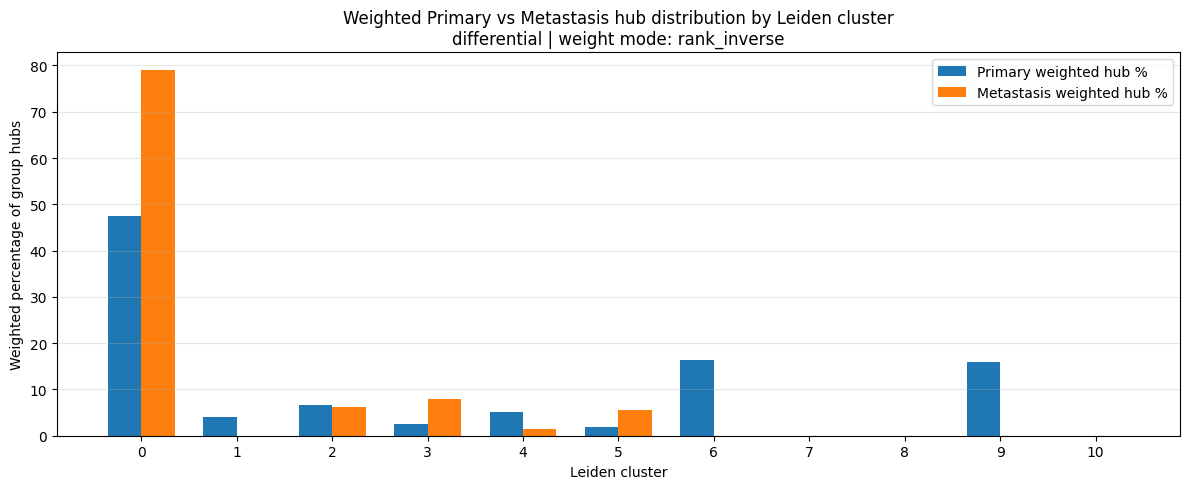

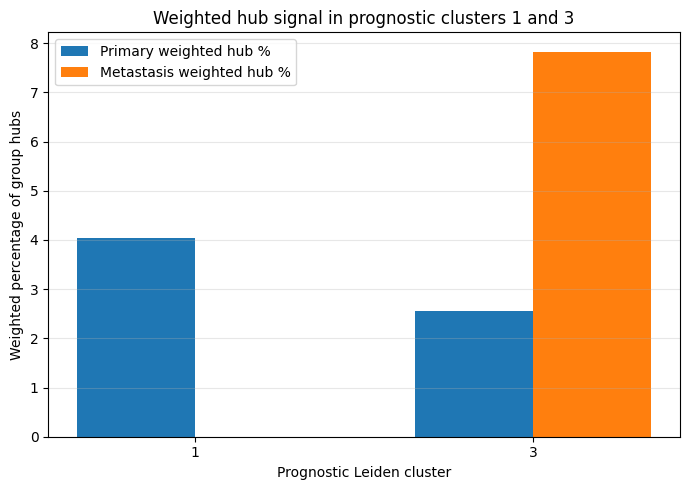


Saved weighted long table:
data_lung\clinical_to_network_by_oncotree_groups_sample_type\hub_genes_cluster_mapping\weighted_hub_distribution_by_cluster\LUAD_NSCLC_differential_rank_inverse_weighted_hub_distribution_long.csv

Saved weighted wide table:
data_lung\clinical_to_network_by_oncotree_groups_sample_type\hub_genes_cluster_mapping\weighted_hub_distribution_by_cluster\LUAD_NSCLC_differential_rank_inverse_weighted_hub_distribution_wide.csv

Saved weighted focus table:
data_lung\clinical_to_network_by_oncotree_groups_sample_type\hub_genes_cluster_mapping\weighted_hub_distribution_by_cluster\LUAD_NSCLC_differential_rank_inverse_weighted_hub_distribution_clusters_1_3.csv

Saved weighted gene detail:
data_lung\clinical_to_network_by_oncotree_groups_sample_type\hub_genes_cluster_mapping\weighted_hub_distribution_by_cluster\LUAD_NSCLC_differential_rank_inverse_weighted_gene_detail.csv

Saved weighted gene detail for clusters 1 and 3:
data_lung\clinical_to_network_by_oncotree_groups_sampl

In [29]:
import pandas as pd
import numpy as np
from pathlib import Path
import matplotlib.pyplot as plt

# ============================================================
# WEIGHTED HUB DISTRIBUTION BY LEIDEN CLUSTER
# Primary vs Metastasis
# LUAD_NSCLC
#
# Idea:
# - non conto solo quanti hub cadono in ogni cluster
# - do più peso agli hub più importanti
# - il peso diminuisce man mano che l'HubScore/rank peggiora
# ============================================================


# ============================================================
# 0. Settings
# ============================================================

data_dir = Path("data_lung")

oncotree_group = "LUAD_NSCLC"

# Scegli quale lista usare:
# "differential" = geni più rappresentativi Primary vs Metastasis
# "separate" = top hub presi separatamente da Primary e Metastasis
ANALYSIS_MODE = "differential"
# ANALYSIS_MODE = "separate"

# Tipo di peso:
# "hubscore" = usa direttamente HubScore normalizzato
# "rank_inverse" = peso = 1 / rank, quindi il primo pesa molto più degli ultimi
# "rank_linear" = peso decresce linearmente dal primo all'ultimo
WEIGHT_MODE = "rank_inverse"
# WEIGHT_MODE = "hubscore"
# WEIGHT_MODE = "rank_linear"

clusters_path = (
    data_dir
    / "networks_by_oncotree_groups"
    / "final_leiden_clusters_with_hub_metrics"
    / f"leiden_clusters_with_hub_metrics_{oncotree_group}.csv"
)

if ANALYSIS_MODE == "differential":
    mapped_path = (
            data_dir
            / "clinical_to_network_by_oncotree_groups_sample_type"
            / "hub_genes_cluster_mapping"
            / "LUAD_NSCLC_differential_primary_vs_metastasis_hub_genes_mapped_to_leiden_clusters.csv"
    )

elif ANALYSIS_MODE == "separate":
    mapped_path = (
            data_dir
            / "clinical_to_network_by_oncotree_groups_sample_type"
            / "hub_genes_cluster_mapping"
            / "LUAD_NSCLC_separate_primary_metastasis_top_hub_genes_mapped_to_leiden_clusters.csv"
    )

else:
    raise ValueError("ANALYSIS_MODE deve essere 'differential' oppure 'separate'.")

output_dir = (
        data_dir
        / "clinical_to_network_by_oncotree_groups_sample_type"
        / "hub_genes_cluster_mapping"
        / "weighted_hub_distribution_by_cluster"
)

output_dir.mkdir(parents=True, exist_ok=True)


# ============================================================
# 1. Load files
# ============================================================

clusters = pd.read_csv(clusters_path, low_memory=False)
mapped = pd.read_csv(mapped_path, low_memory=False)

clusters = clusters.loc[:, ~clusters.columns.duplicated()].copy()

# Normalize column names from the final Leiden cluster file
clusters = clusters.rename(columns={
    "Hugo_Symbol": "Gene",
    "gene": "Gene",
    "GENE": "Gene",
    "cluster": "Cluster",
    "Leiden_cluster": "Cluster",
    "Leiden_Cluster": "Cluster",
    "leiden_cluster": "Cluster",
    "hubscore": "HubScore",
    "rank_in_cluster": "Rank_in_cluster",
    "Oncotree_Code": "Oncotree_Group",
    "ONCOTREE_CODE": "Oncotree_Group",
    "Oncotree Code": "Oncotree_Group"
})
clusters = clusters.loc[:, ~clusters.columns.duplicated()].copy()
mapped = mapped.loc[:, ~mapped.columns.duplicated()].copy()

clusters["Cluster"] = pd.to_numeric(clusters["Cluster"], errors="coerce")
mapped["Cluster"] = pd.to_numeric(mapped["Cluster"], errors="coerce")

clusters["Gene"] = clusters["Gene"].astype(str)
mapped["Gene"] = mapped["Gene"].astype(str)


# ============================================================
# 2. Identify Primary / Metastasis group
# ============================================================

def infer_hub_group(row):
    text_parts = []

    for col in ["Signature_Group", "Hub_List_Group", "sample_type_group"]:
        if col in row.index:
            text_parts.append(str(row[col]))

    text = " ".join(text_parts).lower()

    if "primary" in text:
        return "Primary"

    if "metastasis" in text:
        return "Metastasis"

    return np.nan


mapped["Hub_Group"] = mapped.apply(infer_hub_group, axis=1)

mapped = mapped.dropna(
    subset=["Gene", "Hub_Group", "Cluster"]
).copy()

mapped["Cluster"] = mapped["Cluster"].astype(int)


# ============================================================
# 3. Select correct HubScore for each row
# ============================================================

def get_group_hubscore(row):
    """
    Per differential:
    - Primary usa HubScore_primary
    - Metastasis usa HubScore_metastasis

    Per separate:
    - usa HubScore
    """

    group = row["Hub_Group"]

    if group == "Primary":
        if "HubScore_primary" in row.index and pd.notna(row["HubScore_primary"]):
            return row["HubScore_primary"]

    if group == "Metastasis":
        if "HubScore_metastasis" in row.index and pd.notna(row["HubScore_metastasis"]):
            return row["HubScore_metastasis"]

    if "HubScore" in row.index and pd.notna(row["HubScore"]):
        return row["HubScore"]

    if "Abs_Delta_HubScore" in row.index and pd.notna(row["Abs_Delta_HubScore"]):
        return row["Abs_Delta_HubScore"]

    return np.nan


mapped["HubScore_for_weight"] = mapped.apply(get_group_hubscore, axis=1)

mapped["HubScore_for_weight"] = pd.to_numeric(
    mapped["HubScore_for_weight"],
    errors="coerce"
)

mapped = mapped.dropna(
    subset=["HubScore_for_weight"]
).copy()


# ============================================================
# 4. Rank hubs within each group and assign weight
# ============================================================

mapped = mapped.sort_values(
    ["Hub_Group", "HubScore_for_weight"],
    ascending=[True, False]
).copy()

mapped["Hub_rank_in_group"] = (
    mapped
    .groupby("Hub_Group")["HubScore_for_weight"]
    .rank(method="first", ascending=False)
    .astype(int)
)

mapped["n_hubs_in_group"] = (
    mapped
    .groupby("Hub_Group")["Gene"]
    .transform("nunique")
)


def assign_weight(row):
    rank = row["Hub_rank_in_group"]
    n = row["n_hubs_in_group"]
    hubscore = row["HubScore_for_weight"]

    if WEIGHT_MODE == "hubscore":
        return hubscore

    if WEIGHT_MODE == "rank_inverse":
        return 1 / rank

    if WEIGHT_MODE == "rank_linear":
        if n <= 1:
            return 1
        return (n - rank + 1) / n

    raise ValueError("WEIGHT_MODE non valido.")


mapped["raw_weight"] = mapped.apply(assign_weight, axis=1)

# Normalizzo i pesi dentro ciascun gruppo:
# la somma dei pesi Primary = 100
# la somma dei pesi Metastasis = 100
mapped["normalized_weight"] = (
        mapped["raw_weight"]
        / mapped.groupby("Hub_Group")["raw_weight"].transform("sum")
        * 100
)

mapped["normalized_weight"] = mapped["normalized_weight"].round(4)


# ============================================================
# 5. Cluster sizes
# ============================================================

cluster_sizes = (
    clusters
    .dropna(subset=["Cluster"])
    .assign(Cluster=lambda x: x["Cluster"].astype(int))
    .groupby("Cluster")
    .agg(
        cluster_size_genes=("Gene", "nunique")
    )
    .reset_index()
)


# ============================================================
# 6. Weighted summary by group and cluster
# ============================================================

weighted_long = (
    mapped
    .groupby(["Hub_Group", "Cluster"])
    .agg(
        n_hubs=("Gene", "nunique"),
        weighted_hub_score=("normalized_weight", "sum"),
        mean_hubscore=("HubScore_for_weight", "mean"),
        max_hubscore=("HubScore_for_weight", "max"),
        best_rank=("Hub_rank_in_group", "min"),
        genes=(
            "Gene",
            lambda x: ", ".join(sorted(x.dropna().astype(str).unique()))
        )
    )
    .reset_index()
)

weighted_long["weighted_hub_score"] = weighted_long["weighted_hub_score"].round(2)
weighted_long["mean_hubscore"] = weighted_long["mean_hubscore"].round(4)
weighted_long["max_hubscore"] = weighted_long["max_hubscore"].round(4)

weighted_long = weighted_long.merge(
    cluster_sizes,
    on="Cluster",
    how="left"
)

weighted_long["pct_cluster_covered_by_hubs"] = (
        weighted_long["n_hubs"]
        / weighted_long["cluster_size_genes"]
        * 100
).round(2)

weighted_long = weighted_long.sort_values(
    ["Hub_Group", "weighted_hub_score"],
    ascending=[True, False]
).reset_index(drop=True)


# ============================================================
# 7. Wide readable table
# ============================================================

all_clusters = sorted(clusters["Cluster"].dropna().astype(int).unique())

all_combinations = pd.MultiIndex.from_product(
    [["Primary", "Metastasis"], all_clusters],
    names=["Hub_Group", "Cluster"]
).to_frame(index=False)

weighted_complete = all_combinations.merge(
    weighted_long,
    on=["Hub_Group", "Cluster"],
    how="left"
)

weighted_complete = weighted_complete.merge(
    cluster_sizes,
    on="Cluster",
    how="left",
    suffixes=("", "_from_clusters")
)

weighted_complete["cluster_size_genes"] = (
    weighted_complete["cluster_size_genes"]
    .fillna(weighted_complete["cluster_size_genes_from_clusters"])
)

weighted_complete = weighted_complete.drop(
    columns=["cluster_size_genes_from_clusters"],
    errors="ignore"
)

fill_zero_cols = [
    "n_hubs",
    "weighted_hub_score",
    "mean_hubscore",
    "max_hubscore",
    "pct_cluster_covered_by_hubs"
]

for col in fill_zero_cols:
    if col in weighted_complete.columns:
        weighted_complete[col] = weighted_complete[col].fillna(0)

weighted_complete["best_rank"] = weighted_complete["best_rank"].fillna(np.nan)
weighted_complete["genes"] = weighted_complete["genes"].fillna("-")

wide_parts = []

for group in ["Primary", "Metastasis"]:

    tmp = weighted_complete[
        weighted_complete["Hub_Group"] == group
        ][
        [
            "Cluster",
            "n_hubs",
            "weighted_hub_score",
            "mean_hubscore",
            "max_hubscore",
            "best_rank",
            "pct_cluster_covered_by_hubs",
            "genes"
        ]
    ].copy()

    tmp = tmp.rename(columns={
        "n_hubs": f"{group}_n_hubs",
        "weighted_hub_score": f"{group}_weighted_pct",
        "mean_hubscore": f"{group}_mean_hubscore",
        "max_hubscore": f"{group}_max_hubscore",
        "best_rank": f"{group}_best_rank",
        "pct_cluster_covered_by_hubs": f"{group}_pct_cluster_covered",
        "genes": f"{group}_genes"
    })

    wide_parts.append(tmp)

weighted_wide = cluster_sizes.copy()

for tmp in wide_parts:
    weighted_wide = weighted_wide.merge(
        tmp,
        on="Cluster",
        how="left"
    )

weighted_wide = weighted_wide.fillna({
    "Primary_n_hubs": 0,
    "Primary_weighted_pct": 0,
    "Primary_mean_hubscore": 0,
    "Primary_max_hubscore": 0,
    "Primary_pct_cluster_covered": 0,
    "Primary_genes": "-",
    "Metastasis_n_hubs": 0,
    "Metastasis_weighted_pct": 0,
    "Metastasis_mean_hubscore": 0,
    "Metastasis_max_hubscore": 0,
    "Metastasis_pct_cluster_covered": 0,
    "Metastasis_genes": "-"
})

weighted_wide["Primary_n_hubs"] = weighted_wide["Primary_n_hubs"].astype(int)
weighted_wide["Metastasis_n_hubs"] = weighted_wide["Metastasis_n_hubs"].astype(int)

weighted_wide["Delta_weighted_pct_Primary_minus_Metastasis"] = (
        weighted_wide["Primary_weighted_pct"]
        - weighted_wide["Metastasis_weighted_pct"]
).round(2)

weighted_wide["Delta_n_hubs_Primary_minus_Metastasis"] = (
        weighted_wide["Primary_n_hubs"]
        - weighted_wide["Metastasis_n_hubs"]
)

weighted_wide = weighted_wide.sort_values("Cluster").reset_index(drop=True)


# ============================================================
# 8. Add ranked genes with weights for easier inspection
# ============================================================

weighted_gene_detail = mapped[
    [
        "Hub_Group",
        "Gene",
        "Cluster",
        "HubScore_for_weight",
        "Hub_rank_in_group",
        "raw_weight",
        "normalized_weight"
    ]
].copy()

extra_cols = [
    "Signature_Group",
    "Hub_List_Group",
    "Delta_HubScore_primary_minus_metastasis",
    "Abs_Delta_HubScore",
    "HubScore_primary",
    "HubScore_metastasis",
    "Degree_primary",
    "Degree_metastasis"
]

for col in extra_cols:
    if col in mapped.columns:
        weighted_gene_detail[col] = mapped[col]

weighted_gene_detail = weighted_gene_detail.sort_values(
    ["Hub_Group", "Hub_rank_in_group"]
).reset_index(drop=True)


# ============================================================
# 9. Focus on prognostic clusters 1 and 3
# ============================================================

clusters_of_interest = [1, 3]

weighted_focus = weighted_wide[
    weighted_wide["Cluster"].isin(clusters_of_interest)
].copy()

weighted_gene_focus = weighted_gene_detail[
    weighted_gene_detail["Cluster"].isin(clusters_of_interest)
].copy()


# ============================================================
# 10. Display results
# ============================================================

pd.set_option("display.max_colwidth", 220)

print("\n" + "=" * 120)
print(f"WEIGHTED HUB DISTRIBUTION BY CLUSTER - {ANALYSIS_MODE.upper()} - {WEIGHT_MODE.upper()}")
print("=" * 120)

display(
    weighted_wide[
        [
            "Cluster",
            "cluster_size_genes",
            "Primary_n_hubs",
            "Primary_weighted_pct",
            "Metastasis_n_hubs",
            "Metastasis_weighted_pct",
            "Delta_weighted_pct_Primary_minus_Metastasis",
            "Primary_best_rank",
            "Metastasis_best_rank",
            "Primary_genes",
            "Metastasis_genes"
        ]
    ]
)

print("\n" + "=" * 120)
print("FOCUS ON PROGNOSTIC CLUSTERS 1 AND 3")
print("=" * 120)

display(
    weighted_focus[
        [
            "Cluster",
            "cluster_size_genes",
            "Primary_n_hubs",
            "Primary_weighted_pct",
            "Metastasis_n_hubs",
            "Metastasis_weighted_pct",
            "Delta_weighted_pct_Primary_minus_Metastasis",
            "Primary_best_rank",
            "Metastasis_best_rank",
            "Primary_genes",
            "Metastasis_genes"
        ]
    ]
)

print("\n" + "=" * 120)
print("WEIGHTED GENE DETAIL - CLUSTERS 1 AND 3")
print("=" * 120)

display(weighted_gene_focus)


# ============================================================
# 11. Plot weighted percentage by cluster
# ============================================================

plot_df = weighted_wide[
    [
        "Cluster",
        "Primary_weighted_pct",
        "Metastasis_weighted_pct"
    ]
].copy()

x = np.arange(len(plot_df))
width = 0.35

plt.figure(figsize=(12, 5))

plt.bar(
    x - width / 2,
    plot_df["Primary_weighted_pct"],
    width,
    label="Primary weighted hub %"
)

plt.bar(
    x + width / 2,
    plot_df["Metastasis_weighted_pct"],
    width,
    label="Metastasis weighted hub %"
)

plt.xticks(x, plot_df["Cluster"])
plt.xlabel("Leiden cluster")
plt.ylabel("Weighted percentage of group hubs")
plt.title(
    f"Weighted Primary vs Metastasis hub distribution by Leiden cluster\n"
    f"{ANALYSIS_MODE} | weight mode: {WEIGHT_MODE}"
)
plt.grid(axis="y", alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()


# ============================================================
# 12. Plot focus clusters 1 and 3
# ============================================================

plot_focus = weighted_focus[
    [
        "Cluster",
        "Primary_weighted_pct",
        "Metastasis_weighted_pct"
    ]
].copy()

x = np.arange(len(plot_focus))
width = 0.35

plt.figure(figsize=(7, 5))

plt.bar(
    x - width / 2,
    plot_focus["Primary_weighted_pct"],
    width,
    label="Primary weighted hub %"
)

plt.bar(
    x + width / 2,
    plot_focus["Metastasis_weighted_pct"],
    width,
    label="Metastasis weighted hub %"
)

plt.xticks(x, plot_focus["Cluster"])
plt.xlabel("Prognostic Leiden cluster")
plt.ylabel("Weighted percentage of group hubs")
plt.title("Weighted hub signal in prognostic clusters 1 and 3")
plt.grid(axis="y", alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()


# ============================================================
# 13. Save outputs
# ============================================================

weighted_long_output = (
        output_dir
        / f"LUAD_NSCLC_{ANALYSIS_MODE}_{WEIGHT_MODE}_weighted_hub_distribution_long.csv"
)

weighted_wide_output = (
        output_dir
        / f"LUAD_NSCLC_{ANALYSIS_MODE}_{WEIGHT_MODE}_weighted_hub_distribution_wide.csv"
)

weighted_focus_output = (
        output_dir
        / f"LUAD_NSCLC_{ANALYSIS_MODE}_{WEIGHT_MODE}_weighted_hub_distribution_clusters_1_3.csv"
)

weighted_gene_detail_output = (
        output_dir
        / f"LUAD_NSCLC_{ANALYSIS_MODE}_{WEIGHT_MODE}_weighted_gene_detail.csv"
)

weighted_gene_focus_output = (
        output_dir
        / f"LUAD_NSCLC_{ANALYSIS_MODE}_{WEIGHT_MODE}_weighted_gene_detail_clusters_1_3.csv"
)

weighted_long.to_csv(weighted_long_output, index=False)
weighted_wide.to_csv(weighted_wide_output, index=False)
weighted_focus.to_csv(weighted_focus_output, index=False)
weighted_gene_detail.to_csv(weighted_gene_detail_output, index=False)
weighted_gene_focus.to_csv(weighted_gene_focus_output, index=False)

print("\nSaved weighted long table:")
print(weighted_long_output)

print("\nSaved weighted wide table:")
print(weighted_wide_output)

print("\nSaved weighted focus table:")
print(weighted_focus_output)

print("\nSaved weighted gene detail:")
print(weighted_gene_detail_output)

print("\nSaved weighted gene detail for clusters 1 and 3:")
print(weighted_gene_focus_output)


Available mapped genes by group:


,Hub_Group,available_genes,max_rank
0,Metastasis,20,20
1,Primary,19,19



ATTENZIONE: almeno un gruppo ha meno geni disponibili del massimo top_n richiesto.
Se il file mapped è stato generato con top_n=20, non puoi fare una vera sensitivity a top_n=30 o top_n=50 senza rigenerare prima il mapping con un top_n più alto.

TOP 3 DOMINANT CLUSTERS BY TOP_N AND GROUP


,top_n,Hub_Group,Cluster,n_hubs,weighted_hub_score,best_rank,genes
0,10,Metastasis,0,7,84.88,1,"CIC, EPHB1, KMT2A, PAK7, TBX3, TP63, ZFHX3"
1,10,Metastasis,5,1,6.83,5,FGFR1
2,10,Metastasis,2,1,4.88,7,ASXL2
3,10,Primary,0,4,50.07,1,"ANKRD11, PBRM1, PDGFRA, RFWD2"
4,10,Primary,6,2,19.92,3,"FGF3, FGF4"
5,10,Primary,9,1,17.07,2,ALK
6,20,Metastasis,0,12,78.93,1,"AMER1, ATR, CIC, DICER1, EPHB1, KIT, KMT2A, NOTCH2, PAK7, TBX3, TP63, ZFHX3"
7,20,Metastasis,3,4,7.83,10,"AKT2, APC, PMS2, RAC1"
8,20,Metastasis,2,2,6.29,7,"ASXL2, WT1"
9,20,Primary,0,7,47.42,1,"ANKRD11, CSDE1, DNMT3A, PBRM1, PDGFRA, RFWD2, TNFAIP3"



SENSITIVITY FOCUS ON CLUSTERS [1, 3]


,top_n,Cluster,cluster_size_genes,Primary_n_hubs,Primary_weighted_pct,Metastasis_n_hubs,Metastasis_weighted_pct,Delta_weighted_pct_Primary_minus_Metastasis,Primary_genes,Metastasis_genes
1,10,1,49,1,4.88,0,0.00,4.88,ATRX,-
3,10,3,44,0,0.00,1,3.41,-3.41,-,PMS2
12,20,1,49,1,4.03,0,0.00,4.03,ATRX,-
14,20,3,44,1,2.56,4,7.83,-5.27,BAP1,"AKT2, APC, PMS2, RAC1"
23,30,1,49,1,4.03,0,0.00,4.03,ATRX,-
25,30,3,44,1,2.56,4,7.83,-5.27,BAP1,"AKT2, APC, PMS2, RAC1"
34,50,1,49,1,4.03,0,0.00,4.03,ATRX,-
36,50,3,44,1,2.56,4,7.83,-5.27,BAP1,"AKT2, APC, PMS2, RAC1"


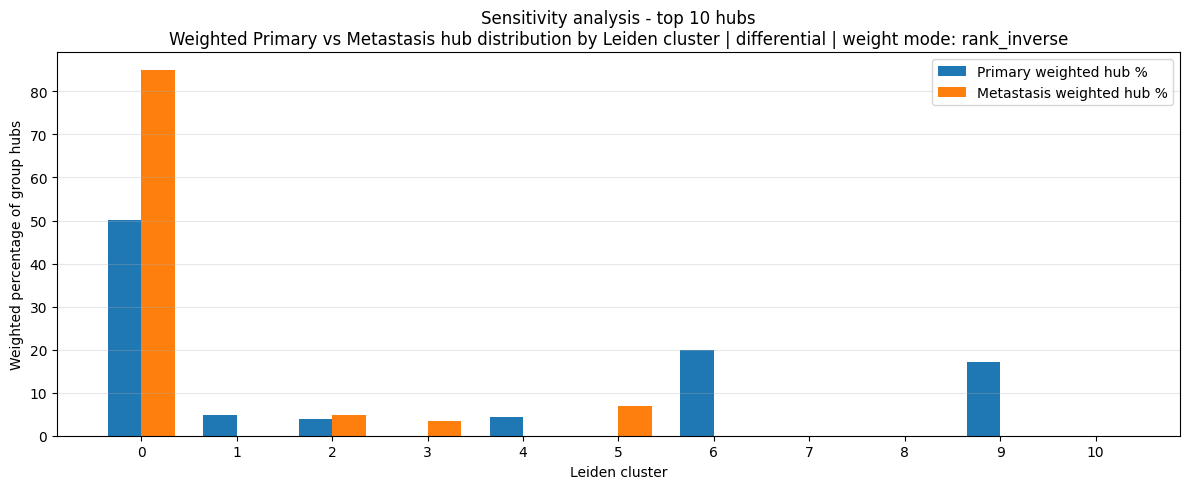

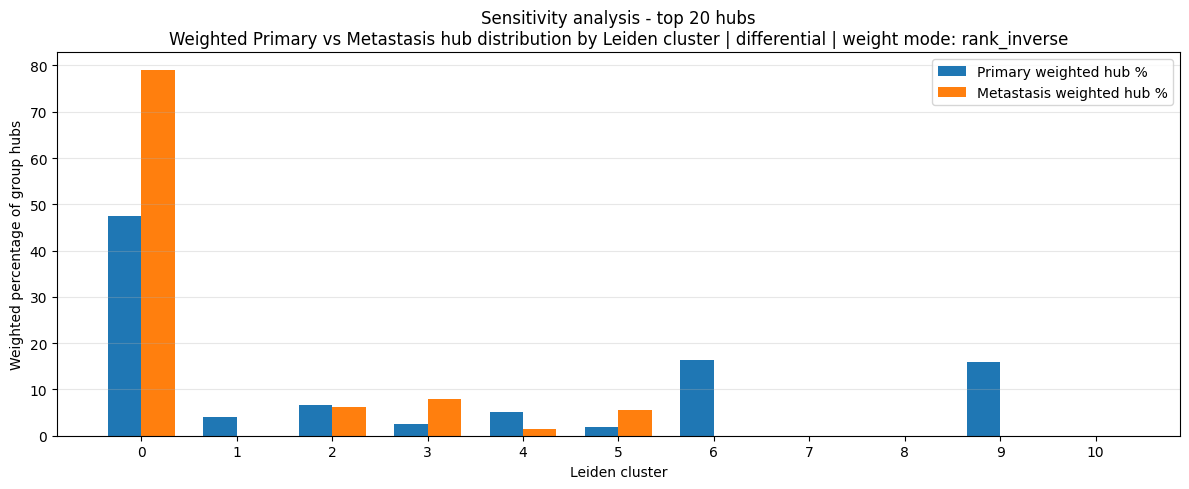

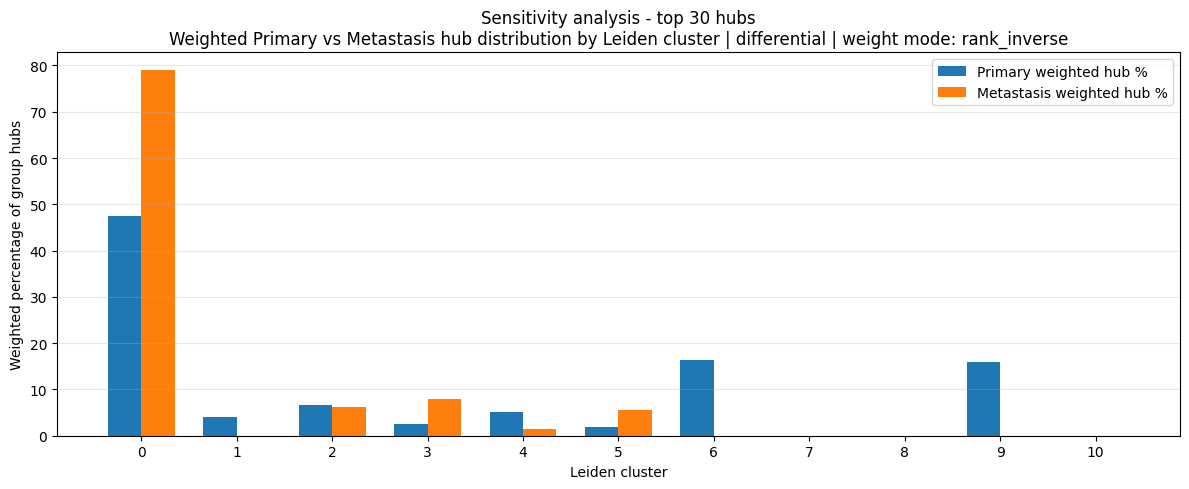

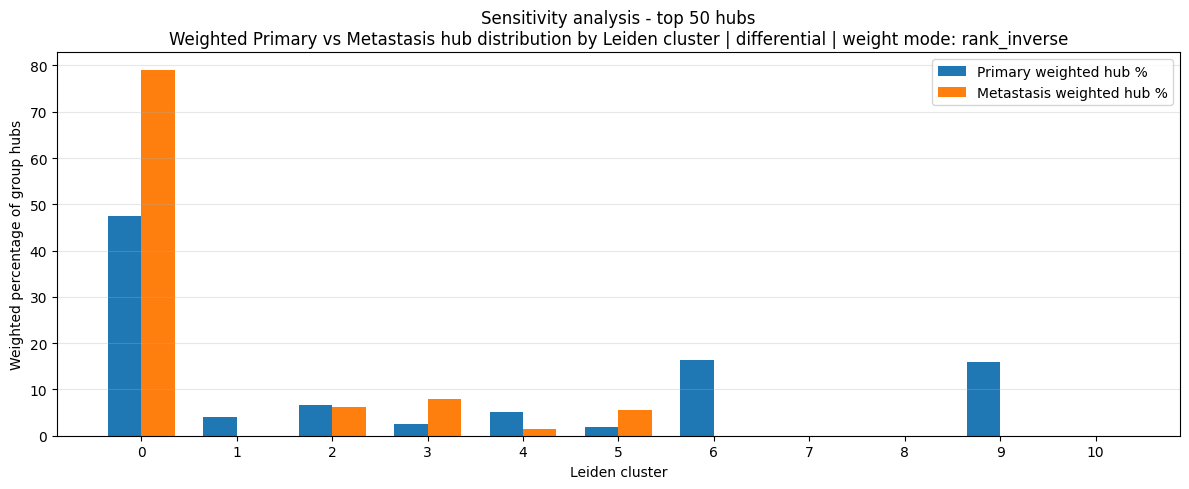

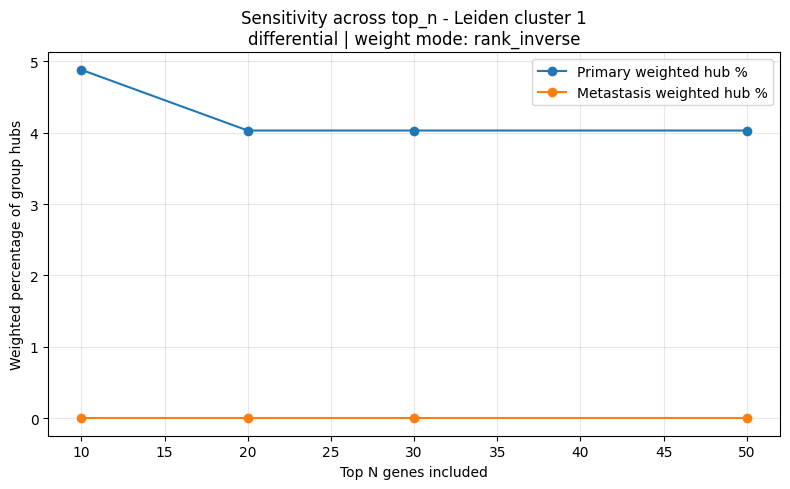

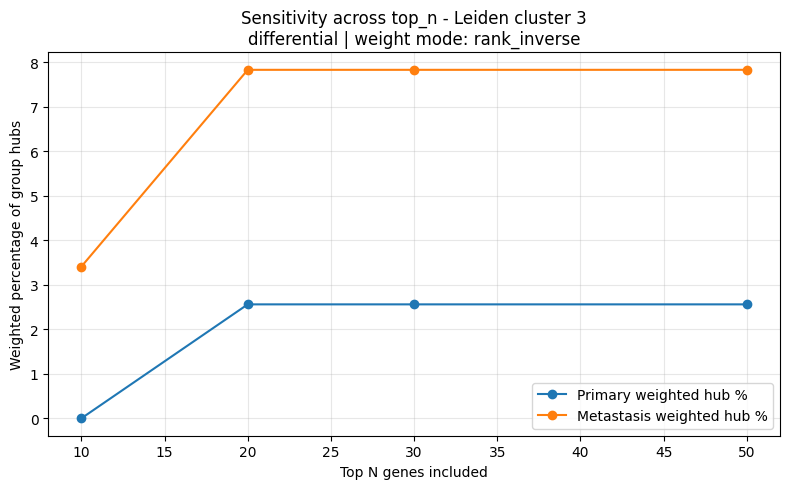


Saved sensitivity long table:
data_lung\clinical_to_network_by_oncotree_groups_sample_type\hub_genes_cluster_mapping\weighted_hub_distribution_by_cluster\sensitivity_analysis_top_n\LUAD_NSCLC_differential_rank_inverse_sample_type_sensitivity_top_n_long.csv

Saved sensitivity wide table:
data_lung\clinical_to_network_by_oncotree_groups_sample_type\hub_genes_cluster_mapping\weighted_hub_distribution_by_cluster\sensitivity_analysis_top_n\LUAD_NSCLC_differential_rank_inverse_sample_type_sensitivity_top_n_wide.csv

Saved sensitivity focus table:
data_lung\clinical_to_network_by_oncotree_groups_sample_type\hub_genes_cluster_mapping\weighted_hub_distribution_by_cluster\sensitivity_analysis_top_n\LUAD_NSCLC_differential_rank_inverse_sample_type_sensitivity_top_n_focus_clusters.csv

Saved dominant clusters table:
data_lung\clinical_to_network_by_oncotree_groups_sample_type\hub_genes_cluster_mapping\weighted_hub_distribution_by_cluster\sensitivity_analysis_top_n\LUAD_NSCLC_differential_rank_inv

In [30]:
# ============================================================
# SENSITIVITY ANALYSIS
# Weighted hub distribution by Leiden cluster
# Primary vs Metastasis
#
# Obiettivo:
# - confrontare la distribuzione pesata degli hub usando diversi top_n
# - capire se il segnale sui cluster è stabile
#
# Da eseguire DOPO la cella:
# WEIGHTED HUB DISTRIBUTION BY LEIDEN CLUSTER - Primary vs Metastasis
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path


# ============================================================
# 0. Settings
# ============================================================

TOP_N_VALUES = [10, 20, 30, 50]

PRIMARY_LABEL = "Primary"
METASTASIS_LABEL = "Metastasis"

SAMPLE_TYPE_GROUPS = [
    PRIMARY_LABEL,
    METASTASIS_LABEL
]

# Mantengo lo stesso weight mode della cella precedente
SENSITIVITY_WEIGHT_MODE = WEIGHT_MODE

# Cluster da monitorare in modo specifico
clusters_of_interest = [1, 3]

sensitivity_output_dir = (
        output_dir
        / "sensitivity_analysis_top_n"
)

sensitivity_output_dir.mkdir(parents=True, exist_ok=True)


# ============================================================
# 1. Check input variables
# ============================================================

required_vars = [
    "mapped",
    "clusters",
    "ANALYSIS_MODE",
    "WEIGHT_MODE",
    "output_dir"
]

missing_vars = [
    var for var in required_vars
    if var not in globals()
]

if missing_vars:
    raise ValueError(
        f"Variabili mancanti: {missing_vars}. "
        "Esegui prima la cella della weighted hub distribution Primary vs Metastasis."
    )

if "oncotree_group" not in globals():
    oncotree_group = "LUAD_NSCLC"


# ============================================================
# 2. Prepare base mapped table
# ============================================================

base_mapped = mapped.copy()
base_mapped = base_mapped.loc[:, ~base_mapped.columns.duplicated()].copy()

required_cols = {
    "Gene",
    "Cluster",
    "Hub_Group",
    "HubScore_for_weight"
}

missing_cols = required_cols - set(base_mapped.columns)

if missing_cols:
    raise ValueError(
        f"Colonne mancanti in mapped: {missing_cols}. "
        "Controlla che la cella precedente abbia creato Hub_Group e HubScore_for_weight."
    )

base_mapped["Gene"] = base_mapped["Gene"].astype(str)
base_mapped["Cluster"] = pd.to_numeric(base_mapped["Cluster"], errors="coerce")
base_mapped["HubScore_for_weight"] = pd.to_numeric(
    base_mapped["HubScore_for_weight"],
    errors="coerce"
)

base_mapped = base_mapped.dropna(
    subset=[
        "Gene",
        "Cluster",
        "Hub_Group",
        "HubScore_for_weight"
    ]
).copy()

base_mapped["Cluster"] = base_mapped["Cluster"].astype(int)

# Una riga per gene dentro ciascun gruppo
base_mapped = (
    base_mapped
    .sort_values(
        ["Hub_Group", "HubScore_for_weight"],
        ascending=[True, False]
    )
    .drop_duplicates(["Hub_Group", "Gene"], keep="first")
    .copy()
)

base_mapped["Full_rank_in_group"] = (
    base_mapped
    .groupby("Hub_Group")["HubScore_for_weight"]
    .rank(method="first", ascending=False)
    .astype(int)
)

available_by_group = (
    base_mapped
    .groupby("Hub_Group")
    .agg(
        available_genes=("Gene", "nunique"),
        max_rank=("Full_rank_in_group", "max")
    )
    .reset_index()
)

print("\nAvailable mapped genes by group:")
display(available_by_group)

max_requested_top_n = max(TOP_N_VALUES)

if available_by_group["available_genes"].min() < max_requested_top_n:
    print(
        "\nATTENZIONE: almeno un gruppo ha meno geni disponibili del massimo top_n richiesto.\n"
        "Se il file mapped è stato generato con top_n=20, non puoi fare una vera sensitivity "
        "a top_n=30 o top_n=50 senza rigenerare prima il mapping con un top_n più alto."
    )


# ============================================================
# 3. Cluster sizes
# ============================================================

clusters_tmp = clusters.copy()
clusters_tmp = clusters_tmp.loc[:, ~clusters_tmp.columns.duplicated()].copy()

clusters_tmp["Cluster"] = pd.to_numeric(
    clusters_tmp["Cluster"],
    errors="coerce"
)

clusters_tmp["Gene"] = clusters_tmp["Gene"].astype(str)

cluster_sizes_sens = (
    clusters_tmp
    .dropna(subset=["Cluster"])
    .assign(Cluster=lambda x: x["Cluster"].astype(int))
    .groupby("Cluster")
    .agg(
        cluster_size_genes=("Gene", "nunique")
    )
    .reset_index()
)

all_clusters = sorted(
    cluster_sizes_sens["Cluster"]
    .dropna()
    .astype(int)
    .unique()
)


# ============================================================
# 4. Helper functions
# ============================================================

def assign_sensitivity_weight(row, weight_mode):
    rank = row["Hub_rank_in_selected_group"]
    n = row["n_hubs_in_selected_group"]
    hubscore = row["HubScore_for_weight"]

    if weight_mode == "hubscore":
        return hubscore

    if weight_mode == "rank_inverse":
        return 1 / rank

    if weight_mode == "rank_linear":
        if n <= 1:
            return 1
        return (n - rank + 1) / n

    raise ValueError("SENSITIVITY_WEIGHT_MODE non valido.")


def compute_weighted_distribution_for_top_n(top_n):
    """
    Calcola distribuzione pesata per uno specifico top_n.
    """

    selected = (
        base_mapped[
            base_mapped["Full_rank_in_group"] <= top_n
            ]
        .copy()
    )

    if selected.empty:
        return pd.DataFrame(), pd.DataFrame(), pd.DataFrame()

    selected = selected.sort_values(
        ["Hub_Group", "HubScore_for_weight"],
        ascending=[True, False]
    ).copy()

    selected["Hub_rank_in_selected_group"] = (
        selected
        .groupby("Hub_Group")["HubScore_for_weight"]
        .rank(method="first", ascending=False)
        .astype(int)
    )

    selected["n_hubs_in_selected_group"] = (
        selected
        .groupby("Hub_Group")["Gene"]
        .transform("nunique")
    )

    selected["raw_weight"] = selected.apply(
        lambda row: assign_sensitivity_weight(
            row,
            SENSITIVITY_WEIGHT_MODE
        ),
        axis=1
    )

    selected["normalized_weight"] = (
            selected["raw_weight"]
            / selected.groupby("Hub_Group")["raw_weight"].transform("sum")
            * 100
    )

    selected["normalized_weight"] = selected["normalized_weight"].round(4)

    weighted_long_top = (
        selected
        .groupby(["Hub_Group", "Cluster"])
        .agg(
            n_hubs=("Gene", "nunique"),
            weighted_hub_score=("normalized_weight", "sum"),
            mean_hubscore=("HubScore_for_weight", "mean"),
            best_rank=("Hub_rank_in_selected_group", "min"),
            genes=("Gene", lambda x: ", ".join(sorted(x.dropna().astype(str).unique())))
        )
        .reset_index()
    )

    weighted_long_top["weighted_hub_score"] = (
        weighted_long_top["weighted_hub_score"]
        .round(2)
    )

    weighted_long_top["mean_hubscore"] = (
        weighted_long_top["mean_hubscore"]
        .round(4)
    )

    weighted_long_top = weighted_long_top.merge(
        cluster_sizes_sens,
        on="Cluster",
        how="left"
    )

    weighted_long_top["pct_cluster_covered_by_hubs"] = np.where(
        weighted_long_top["cluster_size_genes"] > 0,
        weighted_long_top["n_hubs"] / weighted_long_top["cluster_size_genes"] * 100,
        0
    ).round(2)

    weighted_long_top["top_n"] = top_n

    # Completo anche i cluster con 0 hub
    all_combinations = pd.MultiIndex.from_product(
        [SAMPLE_TYPE_GROUPS, all_clusters],
        names=["Hub_Group", "Cluster"]
    ).to_frame(index=False)

    complete = all_combinations.merge(
        weighted_long_top,
        on=["Hub_Group", "Cluster"],
        how="left"
    )

    complete = complete.merge(
        cluster_sizes_sens,
        on="Cluster",
        how="left",
        suffixes=("", "_from_clusters")
    )

    complete["cluster_size_genes"] = (
        complete["cluster_size_genes"]
        .fillna(complete["cluster_size_genes_from_clusters"])
    )

    complete = complete.drop(
        columns=["cluster_size_genes_from_clusters"],
        errors="ignore"
    )

    fill_zero_cols = [
        "n_hubs",
        "weighted_hub_score",
        "mean_hubscore",
        "pct_cluster_covered_by_hubs"
    ]

    for col in fill_zero_cols:
        complete[col] = complete[col].fillna(0)

    complete["best_rank"] = complete["best_rank"].fillna(np.nan)
    complete["genes"] = complete["genes"].fillna("-")
    complete["top_n"] = top_n

    # Wide table
    group_prefix = {
        PRIMARY_LABEL: "Primary",
        METASTASIS_LABEL: "Metastasis"
    }

    wide_parts = []

    for group in SAMPLE_TYPE_GROUPS:

        prefix = group_prefix[group]

        tmp = complete[
            complete["Hub_Group"] == group
            ][
            [
                "Cluster",
                "n_hubs",
                "weighted_hub_score",
                "mean_hubscore",
                "best_rank",
                "pct_cluster_covered_by_hubs",
                "genes"
            ]
        ].copy()

        tmp = tmp.rename(columns={
            "n_hubs": f"{prefix}_n_hubs",
            "weighted_hub_score": f"{prefix}_weighted_pct",
            "mean_hubscore": f"{prefix}_mean_hubscore",
            "best_rank": f"{prefix}_best_rank",
            "pct_cluster_covered_by_hubs": f"{prefix}_pct_cluster_covered",
            "genes": f"{prefix}_genes"
        })

        wide_parts.append(tmp)

    wide_top = cluster_sizes_sens.copy()

    for tmp in wide_parts:
        wide_top = wide_top.merge(
            tmp,
            on="Cluster",
            how="left"
        )

    wide_top = wide_top.fillna({
        "Primary_n_hubs": 0,
        "Primary_weighted_pct": 0,
        "Primary_mean_hubscore": 0,
        "Primary_pct_cluster_covered": 0,
        "Primary_genes": "-",
        "Metastasis_n_hubs": 0,
        "Metastasis_weighted_pct": 0,
        "Metastasis_mean_hubscore": 0,
        "Metastasis_pct_cluster_covered": 0,
        "Metastasis_genes": "-"
    })

    wide_top["Primary_n_hubs"] = wide_top["Primary_n_hubs"].astype(int)
    wide_top["Metastasis_n_hubs"] = wide_top["Metastasis_n_hubs"].astype(int)

    wide_top["Delta_weighted_pct_Primary_minus_Metastasis"] = (
            wide_top["Primary_weighted_pct"]
            - wide_top["Metastasis_weighted_pct"]
    ).round(2)

    wide_top["Delta_n_hubs_Primary_minus_Metastasis"] = (
            wide_top["Primary_n_hubs"]
            - wide_top["Metastasis_n_hubs"]
    )

    wide_top["top_n"] = top_n

    selected_detail = selected[
        [
            "Hub_Group",
            "Gene",
            "Cluster",
            "HubScore_for_weight",
            "Full_rank_in_group",
            "Hub_rank_in_selected_group",
            "raw_weight",
            "normalized_weight"
        ]
    ].copy()

    selected_detail["top_n"] = top_n

    return weighted_long_top, wide_top, selected_detail


# ============================================================
# 5. Run sensitivity analysis
# ============================================================

sensitivity_long_tables = []
sensitivity_wide_tables = []
sensitivity_gene_detail_tables = []

for top_n in TOP_N_VALUES:

    weighted_long_top, wide_top, selected_detail = compute_weighted_distribution_for_top_n(
        top_n=top_n
    )

    if not weighted_long_top.empty:
        sensitivity_long_tables.append(weighted_long_top)

    if not wide_top.empty:
        sensitivity_wide_tables.append(wide_top)

    if not selected_detail.empty:
        sensitivity_gene_detail_tables.append(selected_detail)


sensitivity_long = pd.concat(
    sensitivity_long_tables,
    ignore_index=True
) if sensitivity_long_tables else pd.DataFrame()

sensitivity_wide = pd.concat(
    sensitivity_wide_tables,
    ignore_index=True
) if sensitivity_wide_tables else pd.DataFrame()

sensitivity_gene_detail = pd.concat(
    sensitivity_gene_detail_tables,
    ignore_index=True
) if sensitivity_gene_detail_tables else pd.DataFrame()


# ============================================================
# 6. Dominant clusters by top_n
# ============================================================

if not sensitivity_long.empty:

    dominant_clusters_by_top_n = (
        sensitivity_long
        .sort_values(
            ["top_n", "Hub_Group", "weighted_hub_score"],
            ascending=[True, True, False]
        )
        .groupby(["top_n", "Hub_Group"])
        .head(3)
        .reset_index(drop=True)
    )

    print("\n" + "=" * 120)
    print("TOP 3 DOMINANT CLUSTERS BY TOP_N AND GROUP")
    print("=" * 120)

    display(
        dominant_clusters_by_top_n[
            [
                "top_n",
                "Hub_Group",
                "Cluster",
                "n_hubs",
                "weighted_hub_score",
                "best_rank",
                "genes"
            ]
        ]
    )

else:
    dominant_clusters_by_top_n = pd.DataFrame()
    print("No sensitivity results available.")


# ============================================================
# 7. Focus table on selected clusters
# ============================================================

if not sensitivity_wide.empty:

    sensitivity_focus = sensitivity_wide[
        sensitivity_wide["Cluster"].isin(clusters_of_interest)
    ].copy()

    print("\n" + "=" * 120)
    print(f"SENSITIVITY FOCUS ON CLUSTERS {clusters_of_interest}")
    print("=" * 120)

    display_cols = [
        "top_n",
        "Cluster",
        "cluster_size_genes",
        "Primary_n_hubs",
        "Primary_weighted_pct",
        "Metastasis_n_hubs",
        "Metastasis_weighted_pct",
        "Delta_weighted_pct_Primary_minus_Metastasis",
        "Primary_genes",
        "Metastasis_genes"
    ]

    display(sensitivity_focus[display_cols])

else:
    sensitivity_focus = pd.DataFrame()


# ============================================================
# 8. Plot 1: weighted distribution for each top_n
# General plot over all clusters
# ============================================================

if not sensitivity_wide.empty:

    for top_n in TOP_N_VALUES:

        plot_df = sensitivity_wide[
            sensitivity_wide["top_n"] == top_n
            ][
            [
                "Cluster",
                "Primary_weighted_pct",
                "Metastasis_weighted_pct"
            ]
        ].copy()

        if plot_df.empty:
            continue

        x = np.arange(len(plot_df))
        width = 0.35

        plt.figure(figsize=(12, 5))

        plt.bar(
            x - width / 2,
            plot_df["Primary_weighted_pct"],
            width,
            label="Primary weighted hub %"
        )

        plt.bar(
            x + width / 2,
            plot_df["Metastasis_weighted_pct"],
            width,
            label="Metastasis weighted hub %"
        )

        plt.xticks(x, plot_df["Cluster"])
        plt.xlabel("Leiden cluster")
        plt.ylabel("Weighted percentage of group hubs")
        plt.title(
            f"Sensitivity analysis - top {top_n} hubs\n"
            f"Weighted Primary vs Metastasis hub distribution by Leiden cluster | "
            f"{ANALYSIS_MODE} | weight mode: {SENSITIVITY_WEIGHT_MODE}"
        )
        plt.grid(axis="y", alpha=0.3)
        plt.legend()
        plt.tight_layout()
        plt.show()


# ============================================================
# 9. Plot 2: stability of selected clusters across top_n
# ============================================================

if not sensitivity_wide.empty and not sensitivity_focus.empty:

    for cluster_id in clusters_of_interest:

        plot_cluster = sensitivity_wide[
            sensitivity_wide["Cluster"] == cluster_id
            ].sort_values("top_n").copy()

        if plot_cluster.empty:
            continue

        plt.figure(figsize=(8, 5))

        plt.plot(
            plot_cluster["top_n"],
            plot_cluster["Primary_weighted_pct"],
            marker="o",
            label="Primary weighted hub %"
        )

        plt.plot(
            plot_cluster["top_n"],
            plot_cluster["Metastasis_weighted_pct"],
            marker="o",
            label="Metastasis weighted hub %"
        )

        plt.xlabel("Top N genes included")
        plt.ylabel("Weighted percentage of group hubs")
        plt.title(
            f"Sensitivity across top_n - Leiden cluster {cluster_id}\n"
            f"{ANALYSIS_MODE} | weight mode: {SENSITIVITY_WEIGHT_MODE}"
        )
        plt.grid(alpha=0.3)
        plt.legend()
        plt.tight_layout()
        plt.show()


# ============================================================
# 10. Save outputs
# ============================================================

sensitivity_long_output = (
        sensitivity_output_dir
        / f"{oncotree_group}_{ANALYSIS_MODE}_{SENSITIVITY_WEIGHT_MODE}_sample_type_sensitivity_top_n_long.csv"
)

sensitivity_wide_output = (
        sensitivity_output_dir
        / f"{oncotree_group}_{ANALYSIS_MODE}_{SENSITIVITY_WEIGHT_MODE}_sample_type_sensitivity_top_n_wide.csv"
)

sensitivity_focus_output = (
        sensitivity_output_dir
        / f"{oncotree_group}_{ANALYSIS_MODE}_{SENSITIVITY_WEIGHT_MODE}_sample_type_sensitivity_top_n_focus_clusters.csv"
)

sensitivity_dominant_output = (
        sensitivity_output_dir
        / f"{oncotree_group}_{ANALYSIS_MODE}_{SENSITIVITY_WEIGHT_MODE}_sample_type_sensitivity_top_n_dominant_clusters.csv"
)

sensitivity_gene_detail_output = (
        sensitivity_output_dir
        / f"{oncotree_group}_{ANALYSIS_MODE}_{SENSITIVITY_WEIGHT_MODE}_sample_type_sensitivity_top_n_gene_detail.csv"
)

sensitivity_long.to_csv(sensitivity_long_output, index=False)
sensitivity_wide.to_csv(sensitivity_wide_output, index=False)
sensitivity_focus.to_csv(sensitivity_focus_output, index=False)
dominant_clusters_by_top_n.to_csv(sensitivity_dominant_output, index=False)
sensitivity_gene_detail.to_csv(sensitivity_gene_detail_output, index=False)

print("\nSaved sensitivity long table:")
print(sensitivity_long_output)

print("\nSaved sensitivity wide table:")
print(sensitivity_wide_output)

print("\nSaved sensitivity focus table:")
print(sensitivity_focus_output)

print("\nSaved dominant clusters table:")
print(sensitivity_dominant_output)

print("\nSaved sensitivity gene detail:")
print(sensitivity_gene_detail_output)


# ============================================================
# 11. Interpretation helper
# ============================================================

print("\n" + "=" * 120)
print("INTERPRETATION GUIDE")
print("=" * 120)

print(
    "1. Se gli stessi cluster restano dominanti passando da top 10 a top 20, 30 e 50, "
    "il segnale è più robusto."
)

print(
    "2. Se un cluster è dominante solo con top 10 ma scompare con top 30/top 50, "
    "probabilmente il risultato dipende dai primissimi hub."
)

print(
    "3. Se un cluster aumenta usando top_n più grande, significa che il segnale non è limitato "
    "ai primissimi hub ma coinvolge anche hub meno estremi."
)

print(
    "4. Nel report puoi usare top 20 come analisi principale e questa sensitivity analysis "
    "come controllo di robustezza."
)

OS_MONTHS/event non presenti nel merged sample type file. Li recupero da filtered_data_LUNG.csv.
Loaded:
data_lung\CLINICAL_merged_mutations_cna_sv_with_sample_type_groups_BY_ONCOTREE_GROUPS.csv

Duplicate columns after cleaning:
[]

Rows: 16025
Patients: 1301
Oncotree Groups: ['LUAD_NSCLC', 'LUSC_NSCLC']

Patients by Oncotree Group:


,Oncotree_Group,Included_Oncotree_Codes,n_patients,n_events
0,LUAD_NSCLC,LUAD+NSCLC,1195,826
1,LUSC_NSCLC,LUSC+NSCLC,211,158



Sample Type distribution by Oncotree Group:


,Oncotree_Group,Included_Oncotree_Codes,sample_type_group,n_patients,n_events
0,LUAD_NSCLC,LUAD+NSCLC,Metastasis,707,508
1,LUAD_NSCLC,LUAD+NSCLC,Primary,488,318
2,LUSC_NSCLC,LUSC+NSCLC,Metastasis,107,78
3,LUSC_NSCLC,LUSC+NSCLC,Primary,104,80



ONCOTREE GROUP: LUAD_NSCLC (LUAD+NSCLC)
Signature: LUAD_NSCLC_PRIMARY_hub_signature
Genes: ATRX, BAP1, DNMT3A, FGF3, PBRM1, PDGFRA, PIK3C3, RFWD2, SMAD2, TNFAIP3
Patients with signature mutation: 222
Patients without signature mutation: 973
Events with signature mutation: 157
Events without signature mutation: 669


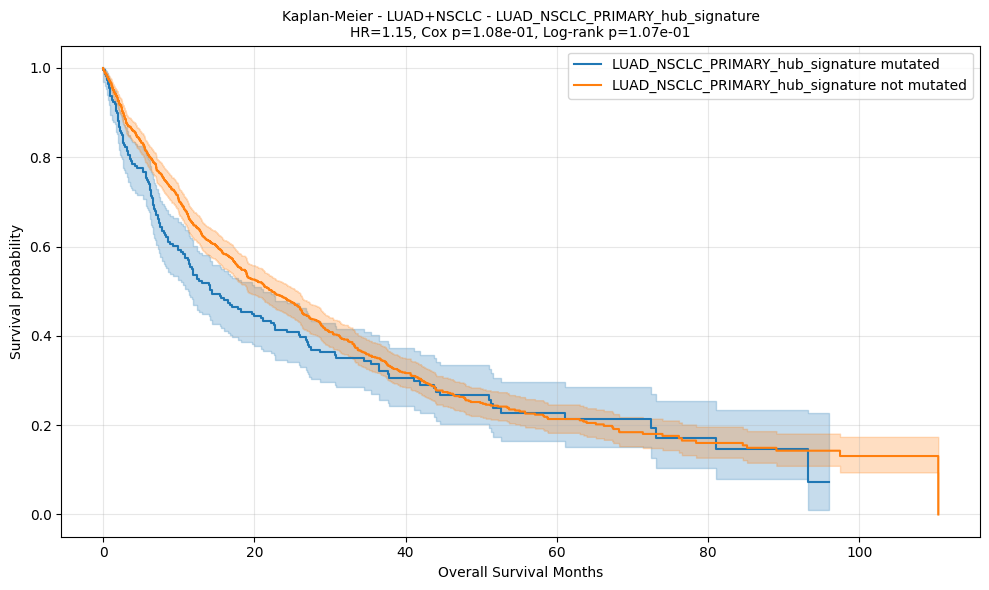

KM plot salvato in: data_lung\clinical_to_network_by_oncotree_groups_sample_type\km_hub_signatures_by_oncotree_group_sample_type\KM_LUAD_NSCLC_LUAD_NSCLC_PRIMARY_hub_signature.png

ONCOTREE GROUP: LUAD_NSCLC (LUAD+NSCLC)
Signature: LUAD_NSCLC_METASTASIS_hub_signature
Genes: ASXL2, CIC, EPHB1, FGFR1, KMT2A, PAK7, PMS2, TBX3, TP63, ZFHX3
Patients with signature mutation: 303
Patients without signature mutation: 892
Events with signature mutation: 199
Events without signature mutation: 627


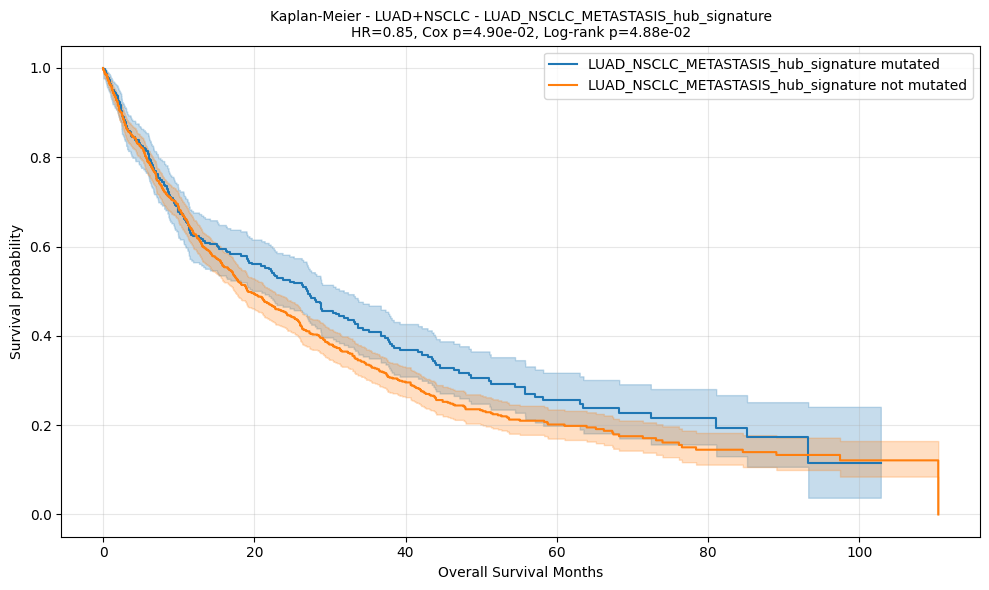

KM plot salvato in: data_lung\clinical_to_network_by_oncotree_groups_sample_type\km_hub_signatures_by_oncotree_group_sample_type\KM_LUAD_NSCLC_LUAD_NSCLC_METASTASIS_hub_signature.png

ONCOTREE GROUP: LUSC_NSCLC (LUSC+NSCLC)
Signature: LUSC_NSCLC_PRIMARY_hub_signature
Genes: KEAP1, KRAS, PREX2, SMARCA4, STK11
Patients with signature mutation: 98
Patients without signature mutation: 113
Events with signature mutation: 76
Events without signature mutation: 82


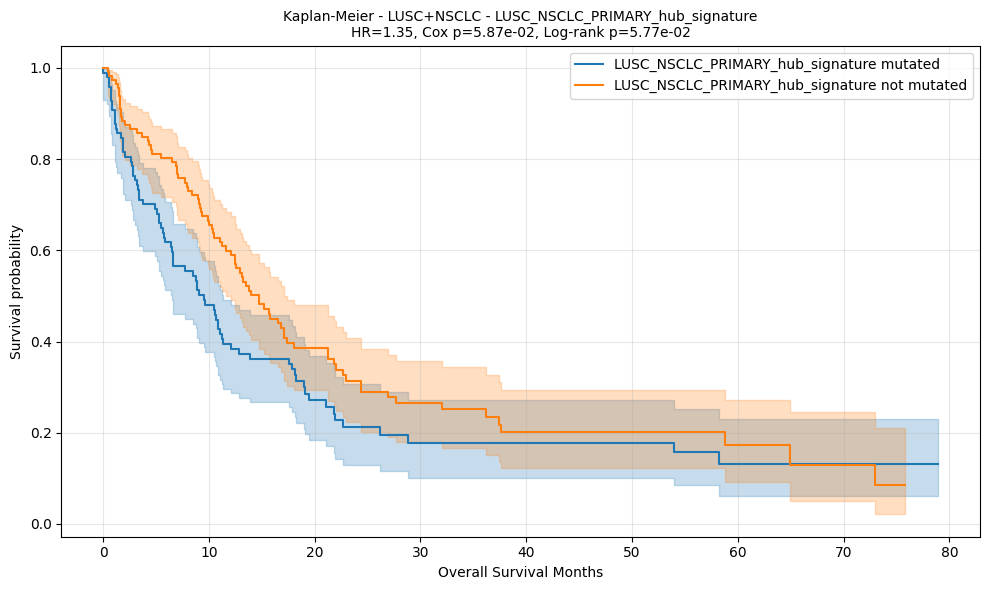

KM plot salvato in: data_lung\clinical_to_network_by_oncotree_groups_sample_type\km_hub_signatures_by_oncotree_group_sample_type\KM_LUSC_NSCLC_LUSC_NSCLC_PRIMARY_hub_signature.png

ONCOTREE GROUP: LUSC_NSCLC (LUSC+NSCLC)
Signature: LUSC_NSCLC_METASTASIS_hub_signature
Genes: KEAP1, KRAS, PREX2, SMARCA4, STK11
Patients with signature mutation: 98
Patients without signature mutation: 113
Events with signature mutation: 76
Events without signature mutation: 82


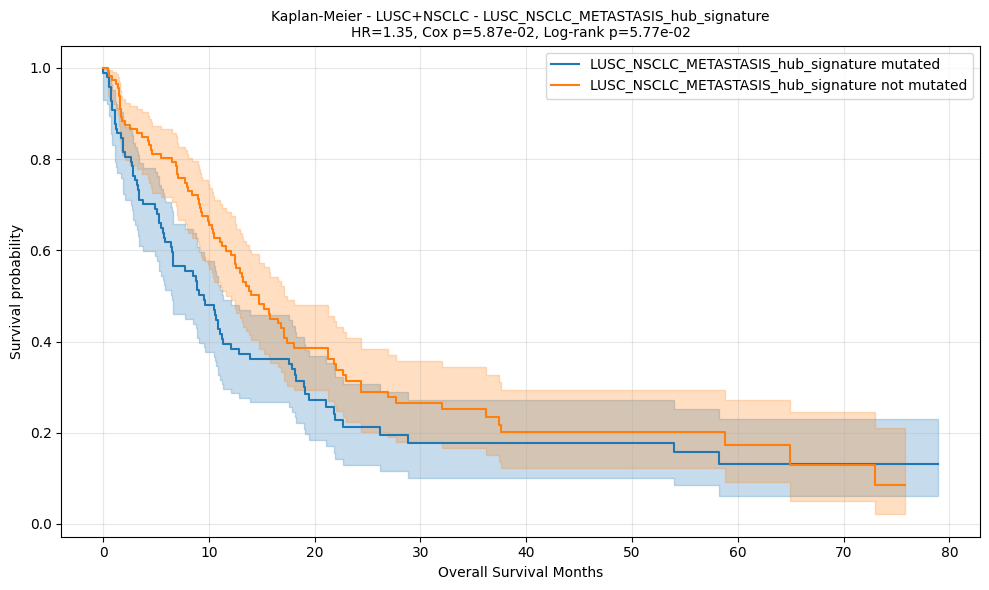

KM plot salvato in: data_lung\clinical_to_network_by_oncotree_groups_sample_type\km_hub_signatures_by_oncotree_group_sample_type\KM_LUSC_NSCLC_LUSC_NSCLC_METASTASIS_hub_signature.png

KM results - clinical to network Sample Type-derived signatures by Oncotree Group:


,Oncotree_Group,Included_Oncotree_Codes,Signature,Num_genes,Genes,Patients_with_signature,Events_with_signature,Patients_without_signature,Events_without_signature,Logrank_p_value,Hazard_Ratio,Cox_p_value
0,LUAD_NSCLC,LUAD+NSCLC,LUAD_NSCLC_METASTASIS_hub_signature,10,"ASXL2, CIC, EPHB1, FGFR1, KMT2A, PAK7, PMS2, T...",303,199,892,627,0.048779,0.851668,0.048965
1,LUAD_NSCLC,LUAD+NSCLC,LUAD_NSCLC_PRIMARY_hub_signature,10,"ATRX, BAP1, DNMT3A, FGF3, PBRM1, PDGFRA, PIK3C...",222,157,973,669,0.106958,1.153447,0.107639
2,LUSC_NSCLC,LUSC+NSCLC,LUSC_NSCLC_PRIMARY_hub_signature,5,"KEAP1, KRAS, PREX2, SMARCA4, STK11",98,76,113,82,0.057738,1.352370,0.058713
3,LUSC_NSCLC,LUSC+NSCLC,LUSC_NSCLC_METASTASIS_hub_signature,5,"KEAP1, KRAS, PREX2, SMARCA4, STK11",98,76,113,82,0.057738,1.352370,0.058713



KM results salvati in:
data_lung\clinical_to_network_by_oncotree_groups_sample_type\km_hub_signatures_by_oncotree_group_sample_type\km_results_clinical_to_network_sample_type_hub_signatures_by_oncotree_groups.csv


In [25]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

from lifelines import KaplanMeierFitter, CoxPHFitter
from lifelines.statistics import logrank_test


# ============================================================
# KM ANALYSIS - CLINICAL TO NETWORK
# Oncotree Groups-oriented
# Hub gene signatures: PRIMARY-hub vs METASTASIS-hub
#
# LUAD_NSCLC = LUAD + NSCLC
# LUSC_NSCLC = LUSC + NSCLC
#
# Nota:
# - la stratificazione di rete viene da sample_type_group
# - la Kaplan-Meier usa comunque OS_MONTHS ed event
# ============================================================

data_dir = Path("data_lung")

merged_path = (
        data_dir
        / "CLINICAL_merged_mutations_cna_sv_with_sample_type_groups_BY_ONCOTREE_GROUPS.csv"
)

# File clinico originale usato solo come fallback se OS_MONTHS / event
# non sono presenti nel merged sample type file.
clinical_fallback_path = data_dir / "filtered_data_LUNG.csv"

km_output_dir = (
        data_dir
        / "clinical_to_network_by_oncotree_groups_sample_type"
        / "km_hub_signatures_by_oncotree_group_sample_type"
)

km_output_dir.mkdir(parents=True, exist_ok=True)

target_groups = ["LUAD_NSCLC", "LUSC_NSCLC"]

group_labels = {
    "LUAD_NSCLC": "LUAD+NSCLC",
    "LUSC_NSCLC": "LUSC+NSCLC",
}


# ============================================================
# Helpers against duplicate columns
# ============================================================

def collapse_duplicate_columns(df):
    """
    Se ci sono colonne duplicate, le collassa prendendo il primo valore non nullo.
    """
    df = df.copy()

    if not df.columns.duplicated().any():
        return df

    collapsed = pd.DataFrame(index=df.index)

    for col in pd.unique(df.columns):
        same_cols = df.loc[:, df.columns == col]

        if same_cols.shape[1] == 1:
            collapsed[col] = same_cols.iloc[:, 0]
        else:
            collapsed[col] = same_cols.bfill(axis=1).iloc[:, 0]

    return collapsed.copy()


def get_single_column(df, col):
    """
    Restituisce sempre una Series, anche se per errore ci sono colonne duplicate.
    """
    obj = df[col]

    if isinstance(obj, pd.DataFrame):
        return obj.iloc[:, 0]

    return obj


def safe_filename(text):
    text = str(text)
    text = text.replace("+", "_")
    text = text.replace("/", "_")
    text = text.replace(" ", "_")
    text = text.replace("(", "")
    text = text.replace(")", "")
    text = text.replace(",", "")
    return text


# ============================================================
# Load merged dataset
# ============================================================

df_merge = pd.read_csv(merged_path, low_memory=False)
df_merge = collapse_duplicate_columns(df_merge)


# ------------------------------------------------------------
# Uniform column names safely
# ------------------------------------------------------------

if "PATIENT_ID" in df_merge.columns and "Patient_ID" not in df_merge.columns:
    df_merge = df_merge.rename(columns={"PATIENT_ID": "Patient_ID"})

if "Oncotree Code" in df_merge.columns and "ONCOTREE_CODE" not in df_merge.columns:
    df_merge = df_merge.rename(columns={"Oncotree Code": "ONCOTREE_CODE"})

if "ONCOTREE_GROUP" in df_merge.columns and "Oncotree_Group" not in df_merge.columns:
    df_merge = df_merge.rename(columns={"ONCOTREE_GROUP": "Oncotree_Group"})

if "Oncotree Group" in df_merge.columns and "Oncotree_Group" not in df_merge.columns:
    df_merge = df_merge.rename(columns={"Oncotree Group": "Oncotree_Group"})

if "Sample Type" in df_merge.columns and "SAMPLE_TYPE" not in df_merge.columns:
    df_merge = df_merge.rename(columns={"Sample Type": "SAMPLE_TYPE"})

if "Sample_Type" in df_merge.columns and "SAMPLE_TYPE" not in df_merge.columns:
    df_merge = df_merge.rename(columns={"Sample_Type": "SAMPLE_TYPE"})

if "sample_type" in df_merge.columns and "SAMPLE_TYPE" not in df_merge.columns:
    df_merge = df_merge.rename(columns={"sample_type": "SAMPLE_TYPE"})

if "SAMPLE_TYPE_GROUP" in df_merge.columns and "sample_type_group" not in df_merge.columns:
    df_merge = df_merge.rename(columns={"SAMPLE_TYPE_GROUP": "sample_type_group"})

# Gestione gene column:
# se esiste già Hugo_Symbol, uso quella;
# se non esiste ma esiste Gene, rinomino Gene.
if "Hugo_Symbol" not in df_merge.columns and "Gene" in df_merge.columns:
    df_merge = df_merge.rename(columns={"Gene": "Hugo_Symbol"})
elif "Hugo_Symbol" in df_merge.columns and "Gene" in df_merge.columns:
    df_merge = df_merge.drop(columns=["Gene"])

df_merge = collapse_duplicate_columns(df_merge)


# ============================================================
# Fallback: add OS_MONTHS / event if missing
# ============================================================
# La pipeline sample type potrebbe non aver salvato OS_MONTHS ed event.
# Per la KM servono obbligatoriamente, quindi se mancano li recupero
# dal filtered_data_LUNG.csv originale.

needs_survival_fallback = (
        "OS_MONTHS" not in df_merge.columns
        or "event" not in df_merge.columns
)

if needs_survival_fallback:
    print(
        "OS_MONTHS/event non presenti nel merged sample type file. "
        "Li recupero da filtered_data_LUNG.csv."
    )

    clinical_surv = pd.read_csv(clinical_fallback_path, low_memory=False)
    clinical_surv = collapse_duplicate_columns(clinical_surv)

    clinical_surv = clinical_surv.rename(columns={
        "Patient_ID": "Patient_ID",
        "PATIENT_ID": "Patient_ID",
        "Overall Survival (Months)": "OS_MONTHS",
        "Overall Survival Status": "OS_STATUS"
    })

    required_surv_cols = {
        "Patient_ID",
        "OS_MONTHS",
        "OS_STATUS"
    }

    missing_surv_cols = required_surv_cols - set(clinical_surv.columns)

    if missing_surv_cols:
        raise ValueError(
            f"Colonne mancanti nel file clinico fallback per survival: {missing_surv_cols}"
        )

    clinical_surv["Patient_ID"] = clinical_surv["Patient_ID"].astype(str)

    clinical_surv["OS_MONTHS"] = pd.to_numeric(
        clinical_surv["OS_MONTHS"],
        errors="coerce"
    )

    clinical_surv["OS_STATUS"] = clinical_surv["OS_STATUS"].astype(str)

    clinical_surv["event"] = (
        clinical_surv["OS_STATUS"]
        .str.contains("DECEASED", case=False, na=False)
        .astype(int)
    )

    clinical_surv = (
        clinical_surv[
            [
                "Patient_ID",
                "OS_MONTHS",
                "OS_STATUS",
                "event"
            ]
        ]
        .dropna(subset=["Patient_ID", "OS_MONTHS", "event"])
        .drop_duplicates("Patient_ID")
        .copy()
    )

    cols_to_remove_before_surv_merge = [
        col for col in ["OS_MONTHS", "OS_STATUS", "event"]
        if col in df_merge.columns
    ]

    df_merge = df_merge.drop(
        columns=cols_to_remove_before_surv_merge
    ).copy()

    df_merge["Patient_ID"] = df_merge["Patient_ID"].astype(str)

    df_merge = df_merge.merge(
        clinical_surv,
        on="Patient_ID",
        how="left"
    )

    df_merge = collapse_duplicate_columns(df_merge)


# ============================================================
# Check required columns
# ============================================================

required_cols = {
    "Patient_ID",
    "Hugo_Symbol",
    "Oncotree_Group",
    "sample_type_group",
    "OS_MONTHS",
    "event"
}

missing_cols = required_cols - set(df_merge.columns)

if missing_cols:
    raise ValueError(
        f"Colonne mancanti nel merged file per gruppi Oncotree + Sample Type: {missing_cols}. "
        "Controlla che sample_type_group, OS_MONTHS, event e Oncotree_Group siano disponibili."
    )


# ============================================================
# Check hub comparison table
# ============================================================

if "hub_comparison_all_oncotree" not in globals():
    if "hub_comparison_all_oncotree_sample_type" in globals():
        hub_comparison_all_oncotree = hub_comparison_all_oncotree_sample_type
    else:
        raise ValueError(
            "hub_comparison_all_oncotree non disponibile. "
            "Esegui prima la cella hub Primary vs Metastasis per Oncotree Group."
        )


# ============================================================
# Type conversion and cleaning
# ============================================================

df_merge["Patient_ID"] = get_single_column(df_merge, "Patient_ID").astype(str)
df_merge["Hugo_Symbol"] = get_single_column(df_merge, "Hugo_Symbol").astype(str)
df_merge["Oncotree_Group"] = get_single_column(df_merge, "Oncotree_Group").astype(str)
df_merge["sample_type_group"] = get_single_column(df_merge, "sample_type_group").astype(str)

df_merge["OS_MONTHS"] = pd.to_numeric(
    get_single_column(df_merge, "OS_MONTHS"),
    errors="coerce"
)

df_merge["event"] = pd.to_numeric(
    get_single_column(df_merge, "event"),
    errors="coerce"
)

df_merge = df_merge.dropna(
    subset=[
        "Patient_ID",
        "Hugo_Symbol",
        "Oncotree_Group",
        "sample_type_group",
        "OS_MONTHS",
        "event"
    ]
).copy()

df_merge["event"] = df_merge["event"].astype(int)

# Tengo solo i due gruppi richiesti
df_merge = df_merge[
    df_merge["Oncotree_Group"].isin(target_groups)
].copy()

if "Included_Oncotree_Codes" not in df_merge.columns:
    df_merge["Included_Oncotree_Codes"] = df_merge["Oncotree_Group"].map(group_labels)

print("Loaded:")
print(merged_path)

print("\nDuplicate columns after cleaning:")
print(df_merge.columns[df_merge.columns.duplicated()].tolist())

print("\nRows:", df_merge.shape[0])
print("Patients:", df_merge["Patient_ID"].nunique())
print("Oncotree Groups:", sorted(df_merge["Oncotree_Group"].unique()))

print("\nPatients by Oncotree Group:")

display(
    df_merge
    .drop_duplicates(["Patient_ID", "Oncotree_Group"])
    .groupby(["Oncotree_Group", "Included_Oncotree_Codes"])
    .agg(
        n_patients=("Patient_ID", "nunique"),
        n_events=("event", "sum")
    )
    .reset_index()
    .sort_values("n_patients", ascending=False)
)

print("\nSample Type distribution by Oncotree Group:")

display(
    df_merge
    .drop_duplicates(["Patient_ID", "Oncotree_Group", "sample_type_group"])
    .groupby(["Oncotree_Group", "Included_Oncotree_Codes", "sample_type_group"])
    .agg(
        n_patients=("Patient_ID", "nunique"),
        n_events=("event", "sum")
    )
    .reset_index()
    .sort_values(["Oncotree_Group", "sample_type_group"])
)


# ============================================================
# PARAMETERS
# ============================================================

top_n_genes = 10
min_patients_per_group = 10
min_events_per_group = 5

km_results = []


# ============================================================
# KM helper
# ============================================================

def run_km_for_gene_signature(
        df_group,
        oncotree_group,
        gene_signature,
        signature_name
):
    """
    Confronta:
    - pazienti con almeno una mutazione nei geni della signature
    - pazienti senza mutazioni nei geni della signature

    Le signature derivano dai geni hub Primary/Metastasis,
    ma l'endpoint testato resta la sopravvivenza globale.
    """

    df_group = collapse_duplicate_columns(df_group)

    readable_group = group_labels.get(oncotree_group, oncotree_group)

    gene_signature = set([
        str(g)
        for g in gene_signature
        if pd.notna(g)
    ])

    if len(gene_signature) == 0:
        print(f"[{oncotree_group} - {signature_name}] No genes in signature.")
        return None

    clinical = (
        df_group[
            [
                "Patient_ID",
                "OS_MONTHS",
                "event"
            ]
        ]
        .drop_duplicates("Patient_ID")
        .copy()
    )

    gene_series = get_single_column(df_group, "Hugo_Symbol").astype(str)

    mask_signature = gene_series.isin(gene_signature)

    patients_with_signature = (
        df_group.loc[mask_signature, "Patient_ID"]
        .dropna()
        .astype(str)
        .unique()
    )

    clinical["has_signature"] = (
        clinical["Patient_ID"]
        .astype(str)
        .isin(patients_with_signature)
        .astype(int)
    )

    n_mut = int(clinical["has_signature"].sum())
    n_wt = int((clinical["has_signature"] == 0).sum())

    events_mut = int(
        clinical.loc[
            clinical["has_signature"] == 1,
            "event"
        ].sum()
    )

    events_wt = int(
        clinical.loc[
            clinical["has_signature"] == 0,
            "event"
        ].sum()
    )

    print("\n" + "=" * 90)
    print(f"ONCOTREE GROUP: {oncotree_group} ({readable_group})")
    print(f"Signature: {signature_name}")
    print(f"Genes: {', '.join(sorted(gene_signature))}")
    print(f"Patients with signature mutation: {n_mut}")
    print(f"Patients without signature mutation: {n_wt}")
    print(f"Events with signature mutation: {events_mut}")
    print(f"Events without signature mutation: {events_wt}")

    if (
            n_mut < min_patients_per_group
            or n_wt < min_patients_per_group
            or events_mut < min_events_per_group
            or events_wt < min_events_per_group
    ):
        print("Skipped: too few patients or events.")
        return None

    group_mut = clinical[clinical["has_signature"] == 1]
    group_wt = clinical[clinical["has_signature"] == 0]

    lr = logrank_test(
        group_mut["OS_MONTHS"],
        group_wt["OS_MONTHS"],
        event_observed_A=group_mut["event"],
        event_observed_B=group_wt["event"]
    )

    cox_df = clinical[
        [
            "OS_MONTHS",
            "event",
            "has_signature"
        ]
    ].copy()

    cph = CoxPHFitter()
    cph.fit(
        cox_df,
        duration_col="OS_MONTHS",
        event_col="event"
    )

    hr = np.exp(cph.params_["has_signature"])
    p_cox = cph.summary.loc["has_signature", "p"]

    kmf = KaplanMeierFitter()

    plt.figure(figsize=(10, 6))

    kmf.fit(
        group_mut["OS_MONTHS"],
        event_observed=group_mut["event"],
        label=f"{signature_name} mutated"
    )
    kmf.plot_survival_function()

    kmf.fit(
        group_wt["OS_MONTHS"],
        event_observed=group_wt["event"],
        label=f"{signature_name} not mutated"
    )
    kmf.plot_survival_function()

    plt.title(
        f"Kaplan-Meier - {readable_group} - {signature_name}\n"
        f"HR={hr:.2f}, Cox p={p_cox:.2e}, Log-rank p={lr.p_value:.2e}",
        fontsize=10
    )

    plt.xlabel("Overall Survival Months")
    plt.ylabel("Survival probability")
    plt.grid(alpha=0.3)
    plt.tight_layout()

    fig_path = (
            km_output_dir
            / f"KM_{safe_filename(oncotree_group)}_{safe_filename(signature_name)}.png"
    )

    plt.savefig(fig_path, dpi=300, bbox_inches="tight")
    plt.show()

    print(f"KM plot salvato in: {fig_path}")

    return {
        "Oncotree_Group": oncotree_group,
        "Included_Oncotree_Codes": readable_group,
        "Signature": signature_name,
        "Num_genes": len(gene_signature),
        "Genes": ", ".join(sorted(gene_signature)),
        "Patients_with_signature": n_mut,
        "Events_with_signature": events_mut,
        "Patients_without_signature": n_wt,
        "Events_without_signature": events_wt,
        "Logrank_p_value": lr.p_value,
        "Hazard_Ratio": hr,
        "Cox_p_value": p_cox
    }


# ============================================================
# RUN KM PER ONCOTREE GROUP
# ============================================================

hub_comparison_all_oncotree = collapse_duplicate_columns(hub_comparison_all_oncotree)

# Compatibilità:
# se per caso la tabella ha ancora ONCOTREE_CODE ma contiene LUAD_NSCLC/LUSC_NSCLC,
# la rinomino in Oncotree_Group.
if "Oncotree_Group" not in hub_comparison_all_oncotree.columns:
    if "ONCOTREE_CODE" in hub_comparison_all_oncotree.columns:
        hub_comparison_all_oncotree = hub_comparison_all_oncotree.rename(
            columns={"ONCOTREE_CODE": "Oncotree_Group"}
        )
    else:
        raise ValueError(
            "hub_comparison_all_oncotree deve contenere Oncotree_Group "
            "oppure ONCOTREE_CODE."
        )

required_hub_cols = {
    "Oncotree_Group",
    "Gene",
    "Delta_HubScore_primary_minus_metastasis"
}

missing_hub_cols = required_hub_cols - set(hub_comparison_all_oncotree.columns)

if missing_hub_cols:
    raise ValueError(
        f"Colonne mancanti in hub_comparison_all_oncotree: {missing_hub_cols}"
    )

hub_comparison_all_oncotree["Oncotree_Group"] = (
    hub_comparison_all_oncotree["Oncotree_Group"]
    .astype(str)
)

hub_comparison_all_oncotree = hub_comparison_all_oncotree[
    hub_comparison_all_oncotree["Oncotree_Group"].isin(target_groups)
].copy()


for oncotree_group in sorted(
        hub_comparison_all_oncotree["Oncotree_Group"]
                .dropna()
                .astype(str)
                .unique()
):

    readable_group = group_labels.get(oncotree_group, oncotree_group)

    df_group = df_merge[
        df_merge["Oncotree_Group"] == oncotree_group
        ].copy()

    comp = hub_comparison_all_oncotree[
        hub_comparison_all_oncotree["Oncotree_Group"].astype(str) == oncotree_group
        ].copy()

    if comp.empty:
        continue

    primary_signature_genes = (
        comp
        .sort_values("Delta_HubScore_primary_minus_metastasis", ascending=False)
        .head(top_n_genes)["Gene"]
        .dropna()
        .astype(str)
        .tolist()
    )

    metastasis_signature_genes = (
        comp
        .sort_values("Delta_HubScore_primary_minus_metastasis", ascending=True)
        .head(top_n_genes)["Gene"]
        .dropna()
        .astype(str)
        .tolist()
    )

    res_primary = run_km_for_gene_signature(
        df_group=df_group,
        oncotree_group=oncotree_group,
        gene_signature=primary_signature_genes,
        signature_name=f"{oncotree_group}_PRIMARY_hub_signature"
    )

    if res_primary is not None:
        km_results.append(res_primary)

    res_metastasis = run_km_for_gene_signature(
        df_group=df_group,
        oncotree_group=oncotree_group,
        gene_signature=metastasis_signature_genes,
        signature_name=f"{oncotree_group}_METASTASIS_hub_signature"
    )

    if res_metastasis is not None:
        km_results.append(res_metastasis)


# ============================================================
# FINAL TABLE
# ============================================================

km_results_clinical_to_network = pd.DataFrame(km_results)

if not km_results_clinical_to_network.empty:
    km_results_clinical_to_network = (
        km_results_clinical_to_network
        .sort_values(["Oncotree_Group", "Logrank_p_value"])
        .reset_index(drop=True)
    )

    output_file = (
            km_output_dir
            / "km_results_clinical_to_network_sample_type_hub_signatures_by_oncotree_groups.csv"
    )

    km_results_clinical_to_network.to_csv(
        output_file,
        index=False
    )

    print("\nKM results - clinical to network Sample Type-derived signatures by Oncotree Group:")

    display(km_results_clinical_to_network)

    print("\nKM results salvati in:")
    print(output_file)

else:
    print("\nNo KM result passed the minimum patient/event thresholds.")


# ============================================================
# OPTIONAL COMPATIBILITY ALIAS
# ============================================================

km_results_clinical_to_network_oncotree_groups = km_results_clinical_to_network
km_results_clinical_to_network_oncotree_groups_sample_type = km_results_clinical_to_network